In [1]:
import torch

if torch.backends.mps.is_available():
    device = torch.device("mps")  # Apple GPU
else:
    device = torch.device("cpu")

print("Training device:", device)

Training device: mps


In [2]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Convert images to tensors: arrays PyTorch can process.
transform = transforms.ToTensor()

full_train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(full_train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", full_train_dataset.classes)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


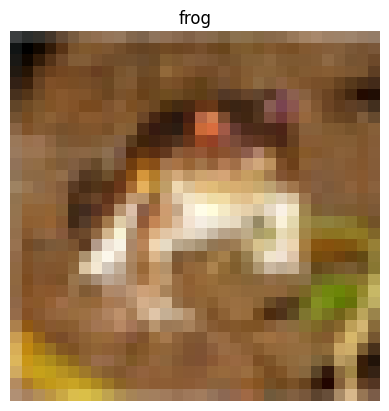

Image shape: torch.Size([3, 32, 32])
Number of pixel values: 3072
Pixel value range: 0.0 1.0


In [3]:
image, label = full_train_dataset[0]

plt.imshow(image.permute(1, 2, 0))
plt.title(full_train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Number of pixel values:", image.numel())
print("Pixel value range:", image.min().item(), image.max().item())

In [4]:
from torch.utils.data import random_split, DataLoader

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Training images: 45000
Validation images: 5000
Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])


In [5]:
import torch.nn as nn

class CNNTrunk(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            # Input: 3 × 32 × 32
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Output: 16 × 16 × 16

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Output: 32 × 8 × 8

            nn.Flatten()
            # Output: 2,048 numbers per image
        )

    def forward(self, x):
        return self.layers(x)


trunk = CNNTrunk().to(device)

images, labels = next(iter(train_loader))

with torch.no_grad():
    features = trunk(images.to(device))

print("Image batch shape:", images.shape)
print("Feature batch shape:", features.shape)

Image batch shape: torch.Size([128, 3, 32, 32])
Feature batch shape: torch.Size([128, 2048])


In [8]:
class RootNode(nn.Module):
    def __init__(self, hidden_width=64):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(2048, hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, 10)
        )

    def forward(self, features):
        return self.layers(features)


root_node = RootNode().to(device)

# The existing trunk and the new root form one model.
model = nn.Sequential(trunk, root_node).to(device)

with torch.no_grad():
    scores = model(images.to(device))

print("Output shape:", scores.shape)
print("First image's scores:", scores[0].cpu())

Output shape: torch.Size([128, 10])
First image's scores: tensor([-0.0157, -0.1090, -0.0589,  0.0367, -0.0742, -0.0700,  0.0609,  0.0654,
         0.0338,  0.0404])


In [9]:
import time

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = []

def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            scores = model(images)
            loss = criterion(scores, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


# Start with 5 epochs to measure learning and speed.
for epoch in range(5):
    start = time.perf_counter()
    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

    # Evaluate the final weights on both sets.
    train_loss, train_acc = evaluate(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch + 1}: "
        f"train loss={train_loss:.3f}, accuracy={train_acc:.2f}% | "
        f"val loss={val_loss:.3f}, accuracy={val_acc:.2f}% | "
        f"time={time.perf_counter() - start:.1f}s"
    )

Epoch 1: train loss=1.521, accuracy=45.06% | val loss=1.525, accuracy=45.48% | time=4.9s
Epoch 2: train loss=1.386, accuracy=50.77% | val loss=1.406, accuracy=50.00% | time=3.5s
Epoch 3: train loss=1.254, accuracy=55.38% | val loss=1.291, accuracy=54.26% | time=3.4s
Epoch 4: train loss=1.161, accuracy=58.82% | val loss=1.204, accuracy=57.28% | time=3.5s
Epoch 5: train loss=1.101, accuracy=60.87% | val loss=1.157, accuracy=58.70% | time=3.6s


In [10]:
root_node = RootNode().to(device)
model = nn.Sequential(trunk, root_node).to(device)

print(model)

Sequential(
  (0): CNNTrunk(
    (layers): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (1): RootNode(
    (layers): Sequential(
      (0): Linear(in_features=2048, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=10, bias=True)
    )
  )
)


In [11]:
# Preserve the mixed-run history for debugging.
previous_history = [entry.copy() for entry in history]

# Attach a fresh optimizer to the CURRENT model.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Start a separate history for the corrected training run.
history = []

model_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

assert model_ids == optimizer_ids
print("Optimizer matches model: True")

Epoch 6: train loss=2.280, accuracy=17.65% | val loss=2.278, accuracy=17.94% | time=3.3s
Epoch 7: train loss=2.262, accuracy=20.56% | val loss=2.260, accuracy=21.12% | time=4.0s
Epoch 8: train loss=2.241, accuracy=23.00% | val loss=2.238, accuracy=23.90% | time=4.0s
Epoch 9: train loss=2.215, accuracy=22.56% | val loss=2.211, accuracy=22.98% | time=4.2s
Epoch 10: train loss=2.182, accuracy=22.84% | val loss=2.177, accuracy=23.16% | time=4.4s
Epoch 11: train loss=2.145, accuracy=24.18% | val loss=2.141, accuracy=24.58% | time=3.4s
Epoch 12: train loss=2.107, accuracy=25.10% | val loss=2.103, accuracy=25.70% | time=3.8s
Epoch 13: train loss=2.069, accuracy=26.17% | val loss=2.066, accuracy=26.74% | time=4.1s
Epoch 14: train loss=2.033, accuracy=27.72% | val loss=2.031, accuracy=28.22% | time=4.4s
Epoch 15: train loss=1.995, accuracy=29.12% | val loss=1.995, accuracy=29.20% | time=3.7s
Epoch 16: train loss=1.958, accuracy=30.64% | val loss=1.957, accuracy=30.76% | time=3.6s
Epoch 17: trai

In [12]:
 # Check that the optimizer updates the current model.
model_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

print("Optimizer matches model:", model_ids == optimizer_ids)
print("Learning rates:", [
    group["lr"] for group in optimizer.param_groups
])

print("\nCurrent model:")
print(model)

print("\nFirst 10 history entries:")
for entry in history[:10]:
    print(entry)

print("\nDataset sizes:")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))

Optimizer matches model: False
Learning rates: [0.001]

Current model:
Sequential(
  (0): CNNTrunk(
    (layers): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (1): RootNode(
    (layers): Sequential(
      (0): Linear(in_features=2048, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=10, bias=True)
    )
  )
)

First 10 history entries:
{'epoch': 1, 'train_loss': 1.5214931257459852, 'train_accuracy': 45.062222222222225, 'val_loss': 1.5250696941375732, 'val_accuracy': 45.48}
{'epoch': 2, 'train_loss': 1.3859775843302409, 'train_accuracy': 50.77333333333333, 'val_loss

In [13]:
# Preserve the mixed-run history for debugging.
previous_history = [entry.copy() for entry in history]

# Attach a fresh optimizer to the CURRENT model.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Start a separate history for the corrected training run.
history = []

model_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

assert model_ids == optimizer_ids
print("Optimizer matches model: True")

Optimizer matches model: True


In [14]:
for _ in range(25):
    epoch_number = len(history) + 1
    start = time.perf_counter()

    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

    train_loss, train_acc = evaluate(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    history.append({
        "epoch": epoch_number,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    # Save progress after every epoch.
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "history": history
    }, "cifar_root_checkpoint.pt")

    print(
        f"Epoch {epoch_number}: "
        f"train loss={train_loss:.3f}, accuracy={train_acc:.2f}% | "
        f"val loss={val_loss:.3f}, accuracy={val_acc:.2f}% | "
        f"time={time.perf_counter() - start:.1f}s"
    )

Epoch 1: train loss=1.466, accuracy=45.22% | val loss=1.489, accuracy=44.58% | time=3.5s
Epoch 2: train loss=1.337, accuracy=51.31% | val loss=1.372, accuracy=50.36% | time=3.8s
Epoch 3: train loss=1.342, accuracy=50.91% | val loss=1.373, accuracy=49.78% | time=3.5s
Epoch 4: train loss=1.279, accuracy=52.86% | val loss=1.338, accuracy=51.32% | time=3.6s
Epoch 5: train loss=1.217, accuracy=55.79% | val loss=1.273, accuracy=54.52% | time=3.6s
Epoch 6: train loss=1.148, accuracy=58.63% | val loss=1.211, accuracy=56.66% | time=3.5s
Epoch 7: train loss=1.142, accuracy=58.82% | val loss=1.212, accuracy=56.08% | time=3.5s
Epoch 8: train loss=1.120, accuracy=59.85% | val loss=1.205, accuracy=57.42% | time=4.0s
Epoch 9: train loss=1.090, accuracy=61.10% | val loss=1.184, accuracy=56.96% | time=3.7s
Epoch 10: train loss=1.087, accuracy=60.93% | val loss=1.177, accuracy=57.76% | time=4.1s
Epoch 11: train loss=1.056, accuracy=62.02% | val loss=1.152, accuracy=58.68% | time=3.7s
Epoch 12: train los

In [15]:
# Keep the learned trunk weights fixed.
trunk.eval()

for parameter in trunk.parameters():
    parameter.requires_grad_(False)


def extract_features(dataset):
    # Fixed order keeps each feature vector aligned with its label.
    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0
    )

    feature_batches = []
    label_batches = []

    with torch.no_grad():
        for images, labels in loader:
            features = trunk(images.to(device))

            feature_batches.append(features.cpu())
            label_batches.append(labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )


X_train, y_train = extract_features(train_dataset)
X_val, y_val = extract_features(val_dataset)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_val.shape)

torch.save({
    "trunk_state": trunk.state_dict(),
    "root_state": root_node.state_dict(),
    "train_indices": list(train_dataset.indices),
    "val_indices": list(val_dataset.indices),
    "history": history
}, "cifar_baseline_before_tree.pt")

Training features: torch.Size([45000, 2048])
Training labels: torch.Size([45000])
Validation features: torch.Size([5000, 2048])


In [16]:
from torch.utils.data import DataLoader

# Freeze the learned CNN trunk.
trunk.eval()

for parameter in trunk.parameters():
    parameter.requires_grad_(False)


def extract_features(dataset):
    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0
    )

    feature_batches = []
    label_batches = []

    with torch.no_grad():
        for images, labels in loader:
            features = trunk(images.to(device))

            feature_batches.append(features.cpu())
            label_batches.append(labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )


X_train, y_train = extract_features(train_dataset)
X_val, y_val = extract_features(val_dataset)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_val.shape)

# Save the baseline weights and dataset split.
torch.save({
    "trunk_state": trunk.state_dict(),
    "root_state": root_node.state_dict(),
    "train_indices": list(train_dataset.indices),
    "val_indices": list(val_dataset.indices),
    "history": history
}, "cifar_baseline_before_tree.pt")

Training features: torch.Size([45000, 2048])
Training labels: torch.Size([45000])
Validation features: torch.Size([5000, 2048])


In [17]:
from torch.utils.data import TensorDataset, DataLoader

cat_class = full_train_dataset.classes.index("cat")

# Convert ten-class labels into cat-versus-rest labels.
cat_train_targets = (y_train == cat_class).float()
cat_val_targets = (y_val == cat_class).float()


class BinaryNode(nn.Module):
    def __init__(self, input_dim=2048, hidden_width=64):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, 1)
        )

    def forward(self, features):
        return self.layers(features).squeeze(-1)


cat_root = BinaryNode().to(device)

cat_loader = DataLoader(
    TensorDataset(X_train, cat_train_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

# Cats are approximately 10% of the dataset.
# Give positive examples more weight during training.
positive_count = cat_train_targets.sum()
negative_count = len(cat_train_targets) - positive_count

positive_weight = (
    negative_count / positive_count
).reshape(1).to(device)

binary_loss = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight
)

cat_optimizer = torch.optim.Adam(
    cat_root.parameters(),
    lr=0.001
)

print("Cat examples:", int(positive_count.item()))
print("Other examples:", int(negative_count.item()))

Cat examples: 4529
Other examples: 40471


In [18]:
def binary_metrics(node, features, targets):
    node.eval()
    predictions = []

    with torch.no_grad():
        for batch in features.split(512):
            scores = node(batch.to(device))
            predictions.append((scores >= 0).cpu())

    predicted = torch.cat(predictions)
    actual = targets.bool()

    accuracy = (predicted == actual).float().mean().item()

    # Recall for each of the two classes.
    cat_recall = predicted[actual].float().mean().item()
    other_recall = (~predicted[~actual]).float().mean().item()

    balanced_accuracy = (cat_recall + other_recall) / 2

    return accuracy, balanced_accuracy, predicted


for epoch in range(10):
    cat_root.train()

    for features, targets in cat_loader:
        features = features.to(device)
        targets = targets.to(device)

        cat_optimizer.zero_grad()

        scores = cat_root(features)
        loss = binary_loss(scores, targets)

        loss.backward()
        cat_optimizer.step()

    train_acc, train_balanced, _ = binary_metrics(
        cat_root, X_train, cat_train_targets
    )

    val_acc, val_balanced, _ = binary_metrics(
        cat_root, X_val, cat_val_targets
    )

    print(
        f"Epoch {epoch + 1}: "
        f"train accuracy={100 * train_acc:.2f}%, "
        f"balanced={100 * train_balanced:.2f}% | "
        f"val accuracy={100 * val_acc:.2f}%, "
        f"balanced={100 * val_balanced:.2f}%"
    )

Epoch 1: train accuracy=61.21%, balanced=75.95% | val accuracy=60.62%, balanced=74.08%
Epoch 2: train accuracy=78.81%, balanced=80.55% | val accuracy=78.62%, balanced=78.02%
Epoch 3: train accuracy=79.30%, balanced=82.34% | val accuracy=78.30%, balanced=79.27%
Epoch 4: train accuracy=86.74%, balanced=80.39% | val accuracy=85.64%, balanced=76.09%
Epoch 5: train accuracy=84.18%, balanced=83.58% | val accuracy=82.90%, balanced=78.67%
Epoch 6: train accuracy=80.85%, balanced=85.09% | val accuracy=79.26%, balanced=78.47%
Epoch 7: train accuracy=72.54%, balanced=83.36% | val accuracy=71.62%, balanced=78.82%
Epoch 8: train accuracy=82.69%, balanced=86.43% | val accuracy=80.34%, balanced=79.26%
Epoch 9: train accuracy=73.88%, balanced=84.44% | val accuracy=72.38%, balanced=79.24%
Epoch 10: train accuracy=83.17%, balanced=87.96% | val accuracy=80.52%, balanced=79.26%


In [19]:
_, _, predicted = binary_metrics(
    cat_root, X_train, cat_train_targets
)

actual = cat_train_targets.bool()

C1 = (~predicted) & (~actual)  # Correct other
C2 = predicted & actual       # Correct cat
C3 = (~predicted) & actual    # Missed cat
C4 = predicted & (~actual)    # Other mistaken for cat

for name, mask in [
    ("C1", C1),
    ("C2", C2),
    ("C3", C3),
    ("C4", C4)
]:
    print(name, ":", mask.sum().item())

torch.save(
    cat_root.state_dict(),
    "cifar_cat_binary_root.pt"
)

C1 : 33172
C2 : 4255
C3 : 274
C4 : 7299


In [20]:
def train_child(features, targets, epochs=15):
    child = BinaryNode(hidden_width=32).to(device)

    positive_count = targets.sum().item()
    negative_count = len(targets) - positive_count

    # Handle a task containing only one target class.
    if positive_count == 0 or negative_count == 0:
        return None, float(positive_count > 0)

    loader = DataLoader(
        TensorDataset(features, targets),
        batch_size=256,
        shuffle=True,
        num_workers=0
    )

    positive_weight = torch.tensor(
        [negative_count / positive_count],
        dtype=torch.float32,
        device=device
    )

    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=positive_weight
    )

    optimizer = torch.optim.Adam(
        child.parameters(),
        lr=0.001
    )

    for epoch in range(epochs):
        child.train()

        for batch_features, batch_targets in loader:
            batch_features = batch_features.to(device)
            batch_targets = batch_targets.to(device)

            optimizer.zero_grad()
            scores = child(batch_features)
            loss = loss_function(scores, batch_targets)
            loss.backward()
            optimizer.step()

        if (epoch + 1) % 5 == 0:
            accuracy, balanced, _ = binary_metrics(
                child, features, targets
            )

            print(
                f"Epoch {epoch + 1}: "
                f"accuracy={100 * accuracy:.2f}% | "
                f"balanced={100 * balanced:.2f}%"
            )

    return child, None


# Child A:
# Target 1 for C3, target 0 for C1 and C4, ignore C2.
A_mask = ~C2
A_targets = C3[A_mask].float()

# Child B:
# Target 1 for C4, target 0 for C2 and C3, ignore C1.
B_mask = ~C1
B_targets = C4[B_mask].float()


print("TRAINING CHILD A")
child_A, constant_A = train_child(
    X_train[A_mask],
    A_targets
)

print("\nTRAINING CHILD B")
child_B, constant_B = train_child(
    X_train[B_mask],
    B_targets
)

TRAINING CHILD A
Epoch 5: accuracy=60.15% | balanced=77.40%
Epoch 10: accuracy=56.88% | balanced=78.30%
Epoch 15: accuracy=86.50% | balanced=91.03%

TRAINING CHILD B
Epoch 5: accuracy=38.29% | balanced=50.00%
Epoch 10: accuracy=68.75% | balanced=63.94%
Epoch 15: accuracy=65.30% | balanced=64.25%


In [21]:
import torch.nn.functional as F

def collect_tree_inputs(features):
    batches = []

    cat_root.eval()

    if child_A is not None:
        child_A.eval()
    if child_B is not None:
        child_B.eval()

    with torch.no_grad():
        for batch in features.split(512):
            batch = batch.to(device)

            root_score = cat_root(batch)

            if child_A is None:
                A = torch.full_like(root_score, constant_A)
            else:
                A = (child_A(batch) >= 0).float()

            if child_B is None:
                B = torch.full_like(root_score, constant_B)
            else:
                B = (child_B(batch) >= 0).float()

            batches.append(
                torch.stack([root_score, A, B], dim=1).cpu()
            )

    return torch.cat(batches)


tree_train_inputs = collect_tree_inputs(X_train)
tree_val_inputs = collect_tree_inputs(X_val)


class CorrectionConnections(nn.Module):
    def __init__(self):
        super().__init__()

        # Softplus ensures positive correction magnitudes.
        self.raw_a = nn.Parameter(torch.tensor(-4.0))
        self.raw_b = nn.Parameter(torch.tensor(-4.0))
        self.bias = nn.Parameter(torch.tensor(0.0))

    def forward(self, inputs):
        root_score = inputs[:, 0]
        A = inputs[:, 1]
        B = inputs[:, 2]

        a = F.softplus(self.raw_a)
        b = F.softplus(self.raw_b)

        return root_score + a * A - b * B + self.bias


connections = CorrectionConnections().to(device)

connection_optimizer = torch.optim.Adam(
    connections.parameters(),
    lr=0.03
)

# Ordinary binary loss: every training example has equal weight.
connection_loss = nn.BCEWithLogitsLoss()

inputs = tree_train_inputs.to(device)
targets = cat_train_targets.to(device)

for step in range(300):
    connection_optimizer.zero_grad()

    scores = connections(inputs)
    loss = connection_loss(scores, targets)

    loss.backward()
    connection_optimizer.step()


# Compare the original root with the corrected tree.
for name, data, targets in [
    ("TRAIN", tree_train_inputs, cat_train_targets),
    ("VALIDATION", tree_val_inputs, cat_val_targets)
]:
    actual = targets.bool()

    with torch.no_grad():
        root_predicted = data[:, 0] >= 0
        tree_predicted = (
            connections(data.to(device)) >= 0
        ).cpu()

    print(f"\n{name}")

    for model_name, predicted in [
        ("Root", root_predicted),
        ("Tree", tree_predicted)
    ]:
        accuracy = (predicted == actual).float().mean().item()
        cat_recall = predicted[actual].float().mean().item()
        other_recall = (~predicted[~actual]).float().mean().item()
        balanced = (cat_recall + other_recall) / 2

        missed_cats = ((~predicted) & actual).sum().item()
        false_cats = (predicted & (~actual)).sum().item()

        print(
            f"{model_name}: accuracy={100 * accuracy:.2f}% | "
            f"balanced={100 * balanced:.2f}% | "
            f"missed cats={missed_cats} | "
            f"false cats={false_cats}"
        )

print(
    "\nCorrection strengths:",
    "a =", F.softplus(connections.raw_a).item(),
    "b =", F.softplus(connections.raw_b).item(),
    "bias =", connections.bias.item()
)


TRAIN
Root: accuracy=83.17% | balanced=87.96% | missed cats=274 | false cats=7299
Tree: accuracy=92.42% | balanced=71.65% | missed cats=2462 | false cats=949

VALIDATION
Root: accuracy=80.52% | balanced=79.26% | missed cats=105 | false cats=869
Tree: accuracy=90.84% | balanced=64.51% | missed cats=320 | false cats=138

Correction strengths: a = 0.023119883611798286 b = 0.5726835131645203 bias = -1.8798775672912598


In [22]:
# Recreate ONLY the connection parameters.
connections = CorrectionConnections().to(device)

connection_optimizer = torch.optim.Adam(
    connections.parameters(),
    lr=0.03
)

positive_count = cat_train_targets.sum()
negative_count = len(cat_train_targets) - positive_count

weight = (
    negative_count / positive_count
).reshape(1).to(device)

connection_loss = nn.BCEWithLogitsLoss(pos_weight=weight)

inputs = tree_train_inputs.to(device)
targets = cat_train_targets.to(device)

for step in range(300):
    connection_optimizer.zero_grad()
    scores = connections(inputs)
    loss = connection_loss(scores, targets)
    loss.backward()
    connection_optimizer.step()

for name, data, targets in [
    ("TRAIN", tree_train_inputs, cat_train_targets),
    ("VALIDATION", tree_val_inputs, cat_val_targets)
]:
    actual = targets.bool()

    with torch.no_grad():
        predicted = (
            connections(data.to(device)) >= 0
        ).cpu()

    accuracy = (predicted == actual).float().mean().item()
    cat_recall = predicted[actual].float().mean().item()
    other_recall = (~predicted[~actual]).float().mean().item()

    print(
        f"{name}: accuracy={100 * accuracy:.2f}% | "
        f"balanced={50 * (cat_recall + other_recall):.2f}% | "
        f"missed cats={((~predicted) & actual).sum().item()} | "
        f"false cats={(predicted & (~actual)).sum().item()}"
    )

TRAIN: accuracy=85.34% | balanced=88.39% | missed cats=353 | false cats=6245
VALIDATION: accuracy=82.36% | balanced=79.23% | missed cats=116 | false cats=766


In [23]:
torch.save({
    "trunk_state": trunk.state_dict(),
    "cat_root_state": cat_root.state_dict(),
    "child_A_state": (
        child_A.state_dict() if child_A is not None else None
    ),
    "child_B_state": (
        child_B.state_dict() if child_B is not None else None
    ),
    "constant_A": constant_A,
    "constant_B": constant_B,
    "connections_state": connections.state_dict(),
    "train_indices": list(train_dataset.indices),
    "val_indices": list(val_dataset.indices)
}, "cifar_cat_correction_tree.pt")

In [24]:
_, _, B_predicted = binary_metrics(
    child_B,
    X_train[B_mask],
    B_targets
)

B_actual = B_targets.bool()

print("Child B task size:", len(B_targets))
print(
    "Missed downward corrections:",
    ((~B_predicted) & B_actual).sum().item()
)
print(
    "Unwanted downward corrections:",
    (B_predicted & (~B_actual)).sum().item()
)

Child B task size: 11828
Missed downward corrections: 2281
Unwanted downward corrections: 1823


In [25]:
# Preserve B before adding its correction children.
original_B = child_B

B_features = X_train[B_mask]
B_actual = B_targets.bool()

# B's own four categories.
B_C1 = (~B_predicted) & (~B_actual)
B_C2 = B_predicted & B_actual
B_C3 = (~B_predicted) & B_actual
B_C4 = B_predicted & (~B_actual)

# Positive correction beneath B.
BA_mask = ~B_C2
BA_targets = B_C3[BA_mask].float()

# Negative correction beneath B.
BB_mask = ~B_C1
BB_targets = B_C4[BB_mask].float()

print("Training positive grandchild beneath B")
grandchild_BA, constant_BA = train_child(
    B_features[BA_mask],
    BA_targets,
    epochs=30
)

print("\nTraining negative grandchild beneath B")
grandchild_BB, constant_BB = train_child(
    B_features[BB_mask],
    BB_targets,
    epochs=30
)


class CorrectedBinaryNode(nn.Module):
    def __init__(
        self, base, positive_child, negative_child,
        positive_constant, negative_constant, connections
    ):
        super().__init__()

        self.base = base
        self.positive_child = positive_child
        self.negative_child = negative_child
        self.positive_constant = positive_constant
        self.negative_constant = negative_constant
        self.connections = connections

    def connection_inputs(self, features):
        base_score = self.base(features)

        if self.positive_child is None:
            A = torch.full_like(
                base_score, self.positive_constant
            )
        else:
            A = (self.positive_child(features) >= 0).float()

        if self.negative_child is None:
            B = torch.full_like(
                base_score, self.negative_constant
            )
        else:
            B = (self.negative_child(features) >= 0).float()

        return torch.stack([base_score, A, B], dim=1)

    def forward(self, features):
        return self.connections(
            self.connection_inputs(features)
        )


B_connections = CorrectionConnections().to(device)

corrected_B = CorrectedBinaryNode(
    original_B,
    grandchild_BA,
    grandchild_BB,
    constant_BA,
    constant_BB,
    B_connections
).to(device)

# Cache grandchild outputs.
corrected_B.eval()

with torch.no_grad():
    cached_inputs = torch.cat([
        corrected_B.connection_inputs(batch.to(device)).cpu()
        for batch in B_features.split(512)
    ])

# Fit only B's correction strengths and bias.
B_connection_optimizer = torch.optim.Adam(
    B_connections.parameters(),
    lr=0.03
)

positive_count = B_targets.sum()
negative_count = len(B_targets) - positive_count

B_connection_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

inputs = cached_inputs.to(device)
targets = B_targets.to(device)

for step in range(300):
    B_connection_optimizer.zero_grad()

    scores = B_connections(inputs)
    loss = B_connection_loss(scores, targets)

    loss.backward()
    B_connection_optimizer.step()

# Compare both versions on B's assigned training task.
for name, node in [
    ("Original B", original_B),
    ("Corrected B", corrected_B)
]:
    accuracy, balanced, predicted = binary_metrics(
        node, B_features, B_targets
    )

    missed = ((~predicted) & B_actual).sum().item()
    unwanted = (predicted & (~B_actual)).sum().item()

    print(
        f"\n{name}: "
        f"accuracy={100 * accuracy:.2f}% | "
        f"balanced={100 * balanced:.2f}% | "
        f"missed corrections={missed} | "
        f"unwanted corrections={unwanted}"
    )

Training positive grandchild beneath B
Epoch 5: accuracy=59.35% | balanced=62.85%
Epoch 10: accuracy=59.56% | balanced=67.39%
Epoch 15: accuracy=63.42% | balanced=63.77%
Epoch 20: accuracy=66.73% | balanced=70.77%
Epoch 25: accuracy=67.09% | balanced=73.56%
Epoch 30: accuracy=71.35% | balanced=75.62%

Training negative grandchild beneath B
Epoch 5: accuracy=69.60% | balanced=65.55%
Epoch 10: accuracy=64.60% | balanced=71.36%
Epoch 15: accuracy=72.69% | balanced=71.37%
Epoch 20: accuracy=72.19% | balanced=76.04%
Epoch 25: accuracy=76.88% | balanced=79.36%
Epoch 30: accuracy=74.76% | balanced=80.36%

Original B: accuracy=65.30% | balanced=64.25% | missed corrections=2281 | unwanted corrections=1823

Corrected B: accuracy=69.31% | balanced=70.59% | missed corrections=2545 | unwanted corrections=1085


In [26]:
# Keep the previous top connections for comparison.
import copy

previous_connections = copy.deepcopy(connections)
previous_train_inputs = tree_train_inputs
previous_val_inputs = tree_val_inputs

# Insert B's subtree.
child_B = corrected_B

tree_train_inputs = collect_tree_inputs(X_train)
tree_val_inputs = collect_tree_inputs(X_val)

# Refit the top connections.
connections = CorrectionConnections().to(device)

connection_optimizer = torch.optim.Adam(
    connections.parameters(), lr=0.03
)

positive_count = cat_train_targets.sum()
negative_count = len(cat_train_targets) - positive_count

connection_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

inputs = tree_train_inputs.to(device)
targets = cat_train_targets.to(device)

for step in range(300):
    connection_optimizer.zero_grad()
    loss = connection_loss(connections(inputs), targets)
    loss.backward()
    connection_optimizer.step()


def print_tree_metrics(name, connection_model, data, targets):
    actual = targets.bool()

    with torch.no_grad():
        predicted = (
            connection_model(data.to(device)) >= 0
        ).cpu()

    accuracy = (predicted == actual).float().mean().item()
    cat_recall = predicted[actual].float().mean().item()
    other_recall = (~predicted[~actual]).float().mean().item()

    print(
        f"{name}: accuracy={100 * accuracy:.2f}% | "
        f"balanced={50 * (cat_recall + other_recall):.2f}% | "
        f"missed cats={((~predicted) & actual).sum().item()} | "
        f"false cats={(predicted & (~actual)).sum().item()}"
    )


for split, old_data, new_data, targets in [
    ("TRAIN", previous_train_inputs,
     tree_train_inputs, cat_train_targets),
    ("VALIDATION", previous_val_inputs,
     tree_val_inputs, cat_val_targets)
]:
    print(f"\n{split}")

    print_tree_metrics(
        "Previous tree", previous_connections, old_data, targets
    )
    print_tree_metrics(
        "Expanded tree", connections, new_data, targets
    )


TRAIN
Previous tree: accuracy=85.34% | balanced=88.39% | missed cats=353 | false cats=6245
Expanded tree: accuracy=86.03% | balanced=89.22% | missed cats=307 | false cats=5981

VALIDATION
Previous tree: accuracy=82.36% | balanced=79.23% | missed cats=116 | false cats=766
Expanded tree: accuracy=82.58% | balanced=78.21% | missed cats=128 | false cats=743


In [27]:
# A separate capacity experiment.
# This does not replace any node in the existing tree.
wide_B = BinaryNode(hidden_width=256).to(device)

wide_B_optimizer = torch.optim.Adam(
    wide_B.parameters(),
    lr=0.001
)

positive_count = B_targets.sum()
negative_count = len(B_targets) - positive_count

wide_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

wide_B_loader = DataLoader(
    TensorDataset(B_features, B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

wide_B_history = []

for epoch in range(100):
    wide_B.train()

    for features, targets in wide_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        wide_B_optimizer.zero_grad()
        scores = wide_B(features)
        loss = wide_B_loss(scores, targets)
        loss.backward()
        wide_B_optimizer.step()

    if (epoch + 1) % 10 == 0:
        accuracy, balanced, predicted = binary_metrics(
            wide_B, B_features, B_targets
        )

        errors = (
            predicted != B_targets.bool()
        ).sum().item()

        wide_B_history.append({
            "epoch": epoch + 1,
            "accuracy": accuracy,
            "balanced_accuracy": balanced,
            "errors": errors
        })

        print(
            f"Epoch {epoch + 1}: "
            f"accuracy={100 * accuracy:.2f}% | "
            f"balanced={100 * balanced:.2f}% | "
            f"errors={errors}"
        )

        if errors == 0:
            print("B's assigned training task is fully fitted.")
            break

torch.save({
    "state": wide_B.state_dict(),
    "hidden_width": 256,
    "history": wide_B_history
}, "cifar_wide_B_experiment.pt")

Epoch 10: accuracy=56.77% | balanced=59.99% | errors=5113
Epoch 20: accuracy=63.41% | balanced=66.16% | errors=4328
Epoch 30: accuracy=70.72% | balanced=73.02% | errors=3463
Epoch 40: accuracy=70.92% | balanced=67.63% | errors=3439
Epoch 50: accuracy=73.69% | balanced=76.93% | errors=3112
Epoch 60: accuracy=76.18% | balanced=77.11% | errors=2818
Epoch 70: accuracy=75.63% | balanced=79.11% | errors=2882
Epoch 80: accuracy=76.22% | balanced=79.90% | errors=2813
Epoch 90: accuracy=79.38% | balanced=82.58% | errors=2439
Epoch 100: accuracy=80.41% | balanced=81.84% | errors=2317


In [28]:
# Reduce the learning rate while retaining weights and optimizer state.
for group in wide_B_optimizer.param_groups:
    group["lr"] = 0.0001

for epoch in range(100, 200):
    wide_B.train()

    for features, targets in wide_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        wide_B_optimizer.zero_grad()
        scores = wide_B(features)
        loss = wide_B_loss(scores, targets)
        loss.backward()
        wide_B_optimizer.step()

    if (epoch + 1) % 10 == 0:
        accuracy, balanced, predicted = binary_metrics(
            wide_B, B_features, B_targets
        )

        errors = (
            predicted != B_targets.bool()
        ).sum().item()

        wide_B_history.append({
            "epoch": epoch + 1,
            "accuracy": accuracy,
            "balanced_accuracy": balanced,
            "errors": errors
        })

        print(
            f"Epoch {epoch + 1}: "
            f"accuracy={100 * accuracy:.2f}% | "
            f"balanced={100 * balanced:.2f}% | "
            f"errors={errors}"
        )

        if errors == 0:
            break

torch.save({
    "state": wide_B.state_dict(),
    "hidden_width": 256,
    "history": wide_B_history
}, "cifar_wide_B_experiment.pt")

Epoch 110: accuracy=82.63% | balanced=85.01% | errors=2054
Epoch 120: accuracy=82.81% | balanced=85.04% | errors=2033
Epoch 130: accuracy=83.08% | balanced=85.55% | errors=2001
Epoch 140: accuracy=83.29% | balanced=85.83% | errors=1977
Epoch 150: accuracy=83.37% | balanced=85.75% | errors=1967
Epoch 160: accuracy=83.57% | balanced=86.10% | errors=1943
Epoch 170: accuracy=83.70% | balanced=86.01% | errors=1928
Epoch 180: accuracy=83.78% | balanced=86.37% | errors=1919
Epoch 190: accuracy=83.91% | balanced=86.29% | errors=1903
Epoch 200: accuracy=84.14% | balanced=86.60% | errors=1876


In [29]:
# Statistics come ONLY from the training features.
feature_mean = X_train.mean(dim=0)
feature_std = X_train.std(dim=0).clamp_min(1e-6)


class CIFARRoots(nn.Module):
    def __init__(self, mean, std, hidden_width=256):
        super().__init__()

        self.register_buffer("feature_mean", mean)
        self.register_buffer("feature_std", std)

        # One independent small network per class.
        self.nodes = nn.ModuleList([
            BinaryNode(hidden_width=hidden_width)
            for _ in range(10)
        ])

    def forward(self, features):
        normalized = (
            features - self.feature_mean
        ) / self.feature_std

        return torch.stack(
            [node(normalized) for node in self.nodes],
            dim=1
        )


cifar_roots = CIFARRoots(
    feature_mean, feature_std
).to(device)

feature_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

# Each column means "this class versus the rest".
class_counts = torch.bincount(y_train, minlength=10).float()
positive_weights = (
    (len(y_train) - class_counts) / class_counts
).to(device)

roots_loss = nn.BCEWithLogitsLoss(
    pos_weight=positive_weights
)

roots_optimizer = torch.optim.Adam(
    cifar_roots.parameters(), lr=0.001
)

roots_history = []

In [30]:
def multiclass_accuracy(network, features, labels):
    network.eval()
    correct = 0

    with torch.no_grad():
        for start in range(0, len(labels), 512):
            batch = features[start:start + 512].to(device)

            # Largest one-versus-rest score selects the class.
            predicted = network(batch).argmax(dim=1).cpu()

            correct += (
                predicted == labels[start:start + 512]
            ).sum().item()

    return 100 * correct / len(labels)


for epoch in range(50):
    cifar_roots.train()

    # Smaller updates during the second half.
    if epoch == 25:
        for group in roots_optimizer.param_groups:
            group["lr"] = 0.0001

    for features, labels in feature_loader:
        features = features.to(device)
        labels = labels.to(device)

        targets = F.one_hot(
            labels, num_classes=10
        ).float()

        roots_optimizer.zero_grad()
        scores = cifar_roots(features)
        loss = roots_loss(scores, targets)
        loss.backward()
        roots_optimizer.step()

    if (epoch + 1) % 5 == 0:
        train_accuracy = multiclass_accuracy(
            cifar_roots, X_train, y_train
        )
        val_accuracy = multiclass_accuracy(
            cifar_roots, X_val, y_val
        )

        roots_history.append({
            "epoch": epoch + 1,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy
        })

        print(
            f"Epoch {epoch + 1}: "
            f"10-class train={train_accuracy:.2f}% | "
            f"validation={val_accuracy:.2f}%"
        )

        torch.save({
            "state": cifar_roots.state_dict(),
            "optimizer_state": roots_optimizer.state_dict(),
            "hidden_width": 256,
            "history": roots_history
        }, "cifar_all_binary_roots.pt")

Epoch 5: 10-class train=90.42% | validation=68.74%
Epoch 10: 10-class train=97.25% | validation=69.36%
Epoch 15: 10-class train=99.22% | validation=69.32%
Epoch 20: 10-class train=99.91% | validation=71.08%
Epoch 25: 10-class train=99.98% | validation=70.78%
Epoch 30: 10-class train=100.00% | validation=71.00%
Epoch 35: 10-class train=99.99% | validation=71.00%
Epoch 40: 10-class train=100.00% | validation=71.02%
Epoch 45: 10-class train=100.00% | validation=71.14%
Epoch 50: 10-class train=100.00% | validation=70.98%


In [31]:
# Evaluate all binary roots on training features.
cifar_roots.eval()

with torch.no_grad():
    train_scores = torch.cat([
        cifar_roots(batch.to(device)).cpu()
        for batch in X_train.split(512)
    ])

multiclass_predictions = train_scores.argmax(dim=1)

print(
    "Exact ten-class training errors:",
    (multiclass_predictions != y_train).sum().item()
)

binary_categories = {}

for k, class_name in enumerate(full_train_dataset.classes):
    actual = y_train == k
    predicted = train_scores[:, k] >= 0

    C1_k = (~predicted) & (~actual)
    C2_k = predicted & actual
    C3_k = (~predicted) & actual
    C4_k = predicted & (~actual)

    binary_categories[k] = {
        "C1": C1_k,
        "C2": C2_k,
        "C3": C3_k,
        "C4": C4_k
    }

    print(
        f"{class_name:12s}: "
        f"missed positives={C3_k.sum().item():4d} | "
        f"false positives={C4_k.sum().item():4d}"
    )

Exact ten-class training errors: 1
airplane    : missed positives=   0 | false positives=  12
automobile  : missed positives=   0 | false positives=   0
bird        : missed positives=   0 | false positives=   0
cat         : missed positives=   0 | false positives=   0
deer        : missed positives=   0 | false positives=   0
dog         : missed positives=   0 | false positives=   0
frog        : missed positives=   0 | false positives=   0
horse       : missed positives=   0 | false positives=   0
ship        : missed positives=   0 | false positives=   0
truck       : missed positives=   0 | false positives=   0


## Train the aeroplane correction child

In [32]:
# Get current training scores.
cifar_roots.eval()

with torch.no_grad():
    train_scores = torch.cat([
        cifar_roots(batch.to(device)).cpu()
        for batch in X_train.split(512)
    ])

airplane_index = full_train_dataset.classes.index("airplane")

actual_airplane = y_train == airplane_index
predicted_airplane = train_scores[:, airplane_index] >= 0

# Child B must activate on false positives.
false_positives = predicted_airplane & (~actual_airplane)

# Include actual airplanes and false positives.
# Correctly rejected non-airplanes are "don't care".
airplane_B_mask = actual_airplane | false_positives

airplane_B_features = (
    X_train[airplane_B_mask] - feature_mean
) / feature_std

airplane_B_targets = false_positives[airplane_B_mask].float()

positive_count = airplane_B_targets.sum()
negative_count = len(airplane_B_targets) - positive_count

print("False positives to correct:", int(positive_count.item()))
print("Actual airplanes to protect:", int(negative_count.item()))

if positive_count.item() == 0:
    raise ValueError(
        "The current airplane root has no false positives. "
        "No downward child is needed."
    )

airplane_B = BinaryNode(hidden_width=128).to(device)

airplane_B_loader = DataLoader(
    TensorDataset(airplane_B_features, airplane_B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

airplane_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

airplane_B_optimizer = torch.optim.Adam(
    airplane_B.parameters(), lr=0.001
)

for epoch in range(100):
    airplane_B.train()

    for features, targets in airplane_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        airplane_B_optimizer.zero_grad()
        scores = airplane_B(features)
        loss = airplane_B_loss(scores, targets)
        loss.backward()
        airplane_B_optimizer.step()

    if (epoch + 1) % 10 == 0:
        _, _, predicted = binary_metrics(
            airplane_B,
            airplane_B_features,
            airplane_B_targets
        )

        actual = airplane_B_targets.bool()

        missed = ((~predicted) & actual).sum().item()
        unwanted = (predicted & (~actual)).sum().item()

        print(
            f"Epoch {epoch + 1}: "
            f"missed corrections={missed} | "
            f"airplanes wrongly corrected={unwanted}"
        )

        if missed == 0 and unwanted == 0:
            print("Child fits its assigned training task perfectly.")
            break

torch.save({
    "state": airplane_B.state_dict(),
    "hidden_width": 128,
    "class_index": airplane_index,
    "feature_mean": feature_mean,
    "feature_std": feature_std
}, "cifar_airplane_correction_child.pt")

False positives to correct: 12
Actual airplanes to protect: 4512
Epoch 10: missed corrections=0 | airplanes wrongly corrected=221
Epoch 20: missed corrections=3 | airplanes wrongly corrected=60
Epoch 30: missed corrections=0 | airplanes wrongly corrected=129
Epoch 40: missed corrections=0 | airplanes wrongly corrected=103
Epoch 50: missed corrections=0 | airplanes wrongly corrected=215
Epoch 60: missed corrections=0 | airplanes wrongly corrected=131
Epoch 70: missed corrections=0 | airplanes wrongly corrected=237
Epoch 80: missed corrections=0 | airplanes wrongly corrected=95
Epoch 90: missed corrections=0 | airplanes wrongly corrected=38
Epoch 100: missed corrections=0 | airplanes wrongly corrected=71


## Evaluating the Airplane Correction Child in the Complete CIFAR-10 Classifier

Select the downward correction strength using training data, then compare the original and corrected classifiers on training and validation data.

In [33]:
# Evaluate the airplane child inside the complete ten-class model.
import torch

cifar_roots.eval()
airplane_B.eval()

@torch.no_grad()
def get_root_scores_and_child(features):
    root_outputs = []
    child_outputs = []

    for batch in features.split(512):
        batch = batch.to(device)

        root_outputs.append(cifar_roots(batch).cpu())

        normalized = (
            batch - feature_mean.to(device)
        ) / feature_std.to(device)

        child_outputs.append(
            (airplane_B(normalized) >= 0).cpu()
        )

    return (
        torch.cat(root_outputs),
        torch.cat(child_outputs).bool()
    )

train_scores, train_child_active = get_root_scores_and_child(X_train)

train_labels = y_train.cpu()
train_is_airplane = train_labels == airplane_index

# Search a range of correction strengths.
# Include b=0 so we can retain the original predictions if needed.
active_scores = train_scores[
    train_child_active, airplane_index
]

upper = (
    max(0.0, active_scores.max().item()) + 1.0
    if active_scores.numel() else 1.0
)

strengths = torch.linspace(0.0, upper, 201)

best_key = None
best_b = 0.0

for strength in strengths:
    b = strength.item()

    corrected = train_scores.clone()
    corrected[:, airplane_index] -= (
        b * train_child_active.float()
    )

    # Complete ten-class prediction.
    class_errors = (
        corrected.argmax(dim=1) != train_labels
    ).sum().item()

    # Airplane-versus-rest prediction.
    predicts_airplane = corrected[:, airplane_index] >= 0

    missed_airplanes = (
        (~predicts_airplane) & train_is_airplane
    ).sum().item()

    false_airplanes = (
        predicts_airplane & (~train_is_airplane)
    ).sum().item()

    # First protect ten-class accuracy.
    # Break ties using binary errors, then smaller strength.
    key = (
        class_errors,
        missed_airplanes + false_airplanes,
        b
    )

    if best_key is None or key < best_key:
        best_key = key
        best_b = b

print(f"Selected correction strength b = {best_b:.6f}")


def report_correction(name, scores, child_active, labels):
    labels = labels.cpu()
    actual_airplane = labels == airplane_index

    for model_name, strength in [
        ("Original roots", 0.0),
        ("Roots + airplane child", best_b)
    ]:
        corrected = scores.clone()
        corrected[:, airplane_index] -= (
            strength * child_active.float()
        )

        errors = (
            corrected.argmax(dim=1) != labels
        ).sum().item()

        accuracy = 100 * (1 - errors / len(labels))

        predicts_airplane = (
            corrected[:, airplane_index] >= 0
        )

        missed = (
            (~predicts_airplane) & actual_airplane
        ).sum().item()

        false_positive = (
            predicts_airplane & (~actual_airplane)
        ).sum().item()

        print(
            f"{name} | {model_name}: "
            f"10-class accuracy={accuracy:.4f}% | "
            f"errors={errors} | "
            f"missed airplanes={missed} | "
            f"false airplanes={false_positive}"
        )


report_correction(
    "TRAIN", train_scores, train_child_active, y_train
)

# Validation is evaluated only after choosing b on training data.
val_scores, val_child_active = get_root_scores_and_child(X_val)

report_correction(
    "VALIDATION", val_scores, val_child_active, y_val
)

Selected correction strength b = 3.625057
TRAIN | Original roots: 10-class accuracy=99.9978% | errors=1 | missed airplanes=0 | false airplanes=12
TRAIN | Roots + airplane child: 10-class accuracy=100.0000% | errors=0 | missed airplanes=0 | false airplanes=0
VALIDATION | Original roots: 10-class accuracy=70.9800% | errors=1451 | missed airplanes=104 | false airplanes=126
VALIDATION | Roots + airplane child: 10-class accuracy=70.9600% | errors=1452 | missed airplanes=106 | false airplanes=124


### Results of the Airplane Correction Child

The correction strength was selected using training data only.
With b = 3.625057, the corrected classifier achieved exactly
100% training accuracy, compared with 99.9978% for the original
roots. All 12 training airplane false positives were removed,
with no missed training airplanes.

Validation accuracy changed from 70.98% to 70.96%, corresponding
to one additional error. Thus, the correction improved training
fit but did not improve generalization.

## Saving the CIFAR-10 Neural Tree with Perfect Training Accuracy

In [34]:
# Save the shared trunk, ten roots, and airplane correction child.
# These three components together form our final CIFAR-10 model.

cifar_tree_checkpoint = {
    "trunk_state": trunk.state_dict(),
    "roots_state": cifar_roots.state_dict(),
    "airplane_child_state": airplane_B.state_dict(),

    "root_hidden_width": 256,
    "child_hidden_width": 128,

    "feature_mean": feature_mean.cpu(),
    "feature_std": feature_std.cpu(),

    "airplane_index": airplane_index,
    "correction_strength": float(best_b),
    "child_threshold": 0.0,

    "classes": list(full_train_dataset.classes),

    "results": {
        "training_images": len(y_train),
        "validation_images": len(y_val),
        "training_errors": 0,
        "training_accuracy_percent": 100.0,
        "validation_errors": 1452,
        "validation_accuracy_percent": 70.96
    }
}

torch.save(
    cifar_tree_checkpoint,
    "cifar10_neural_tree_final.pt"
)

# Count learned parameters.
trunk_parameters = sum(p.numel() for p in trunk.parameters())
root_parameters = sum(p.numel() for p in cifar_roots.parameters())
child_parameters = sum(p.numel() for p in airplane_B.parameters())

# Include the selected scalar correction strength.
total_parameters = (
    trunk_parameters + root_parameters + child_parameters + 1
)

print("Saved: cifar10_neural_tree_final.pt")
print(f"Shared CNN trunk: {trunk_parameters:,} parameters")
print(f"Ten root networks: {root_parameters:,} parameters")
print(f"Airplane child: {child_parameters:,} parameters")
print(f"Total, including correction strength: {total_parameters:,}")

Saved: cifar10_neural_tree_final.pt
Shared CNN trunk: 5,088 parameters
Ten root networks: 5,248,010 parameters
Airplane child: 262,401 parameters
Total, including correction strength: 5,515,500


## Node Receptive-Field Exploration Using Input-Gradient Maps

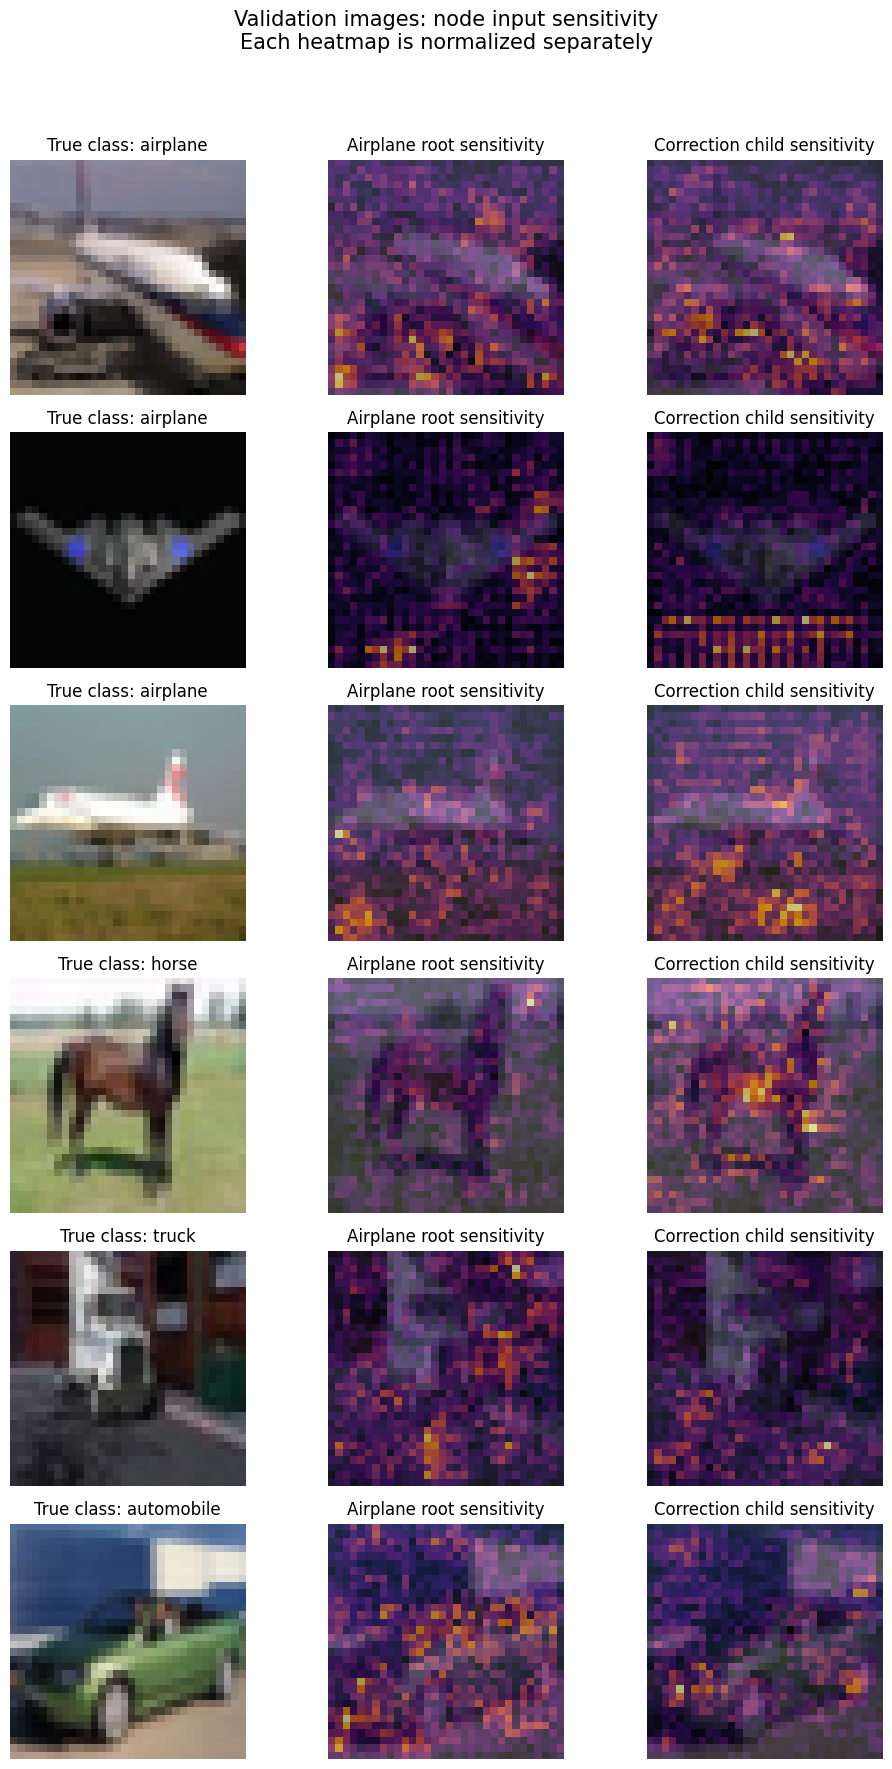

Saved: cifar10_node_sensitivity.png
Saved: cifar10_node_sensitivity.pdf


In [35]:
import matplotlib.pyplot as plt
import numpy as np

trunk.eval()
cifar_roots.eval()
airplane_B.eval()


def node_sensitivity(image, node_name):
    # Enable gradients on the input image.
    image_input = (
        image.unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    # Gradients still pass through a frozen trunk to the image.
    features = trunk(image_input)

    if node_name == "airplane_root":
        score = cifar_roots(features)[0, airplane_index]

    elif node_name == "airplane_child":
        normalized = (
            features - feature_mean.to(device)
        ) / feature_std.to(device)

        # Use the child's continuous score, before its hard threshold.
        score = airplane_B(normalized).reshape(-1)[0]

    else:
        raise ValueError("Unknown node name")

    gradient = torch.autograd.grad(
        score, image_input
    )[0]

    # Combine the three colour-channel gradients.
    sensitivity = (
        gradient.abs()
        .amax(dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )

    # Normalize each map separately for display.
    sensitivity /= max(float(sensitivity.max()), 1e-12)

    return sensitivity


# Select three airplanes and three non-airplanes from validation.
# No selection is based on the appearance of the resulting maps.
example_indices = []

for wanted_airplane in [True, False]:
    count = 0

    for index in range(len(val_dataset)):
        _, label = val_dataset[index]

        if (int(label) == airplane_index) == wanted_airplane:
            example_indices.append(index)
            count += 1

        if count == 3:
            break


fig, axes = plt.subplots(
    len(example_indices), 3,
    figsize=(10, 3 * len(example_indices)),
    squeeze=False
)

for row, index in enumerate(example_indices):
    image, label = val_dataset[index]

    # Our dataset uses ToTensor(), so pixels are in [0, 1].
    displayed_image = image.permute(1, 2, 0).cpu().numpy()
    displayed_image = np.clip(displayed_image, 0, 1)

    root_map = node_sensitivity(image, "airplane_root")
    child_map = node_sensitivity(image, "airplane_child")

    axes[row, 0].imshow(displayed_image)
    axes[row, 0].set_title(
        f"True class: {full_train_dataset.classes[int(label)]}"
    )

    axes[row, 1].imshow(displayed_image)
    axes[row, 1].imshow(
        root_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 1].set_title("Airplane root sensitivity")

    axes[row, 2].imshow(displayed_image)
    axes[row, 2].imshow(
        child_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 2].set_title("Correction child sensitivity")

    for axis in axes[row]:
        axis.axis("off")

fig.suptitle(
    "Validation images: node input sensitivity\n"
    "Each heatmap is normalized separately",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "cifar10_node_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "cifar10_node_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved: cifar10_node_sensitivity.png")
print("Saved: cifar10_node_sensitivity.pdf")

### Interpretation of Node Sensitivity Maps

Input-gradient maps reveal different spatial sensitivity patterns
for the airplane root and its correction child, despite their use
of the same CNN features. Responses occur on both objects and
background regions. For example, the correction child shows a
strong horizontal response below the second airplane, whereas
the root responds more strongly near the right image boundary.

The maps do not demonstrate consistent localization of airplane
parts. They visualize local sensitivity of each node's continuous
score, rather than the direction of its decision or the final
classifier's prediction. Each map is normalized independently,
so brightness cannot be compared quantitatively across nodes.

The correction achieves perfect training fit without improving
validation accuracy. The visualizations provide qualitative
evidence of different node sensitivities, but do not establish
the cause of this generalization gap.

## Input Sensitivity of All Ten CIFAR-10 Root Nodes

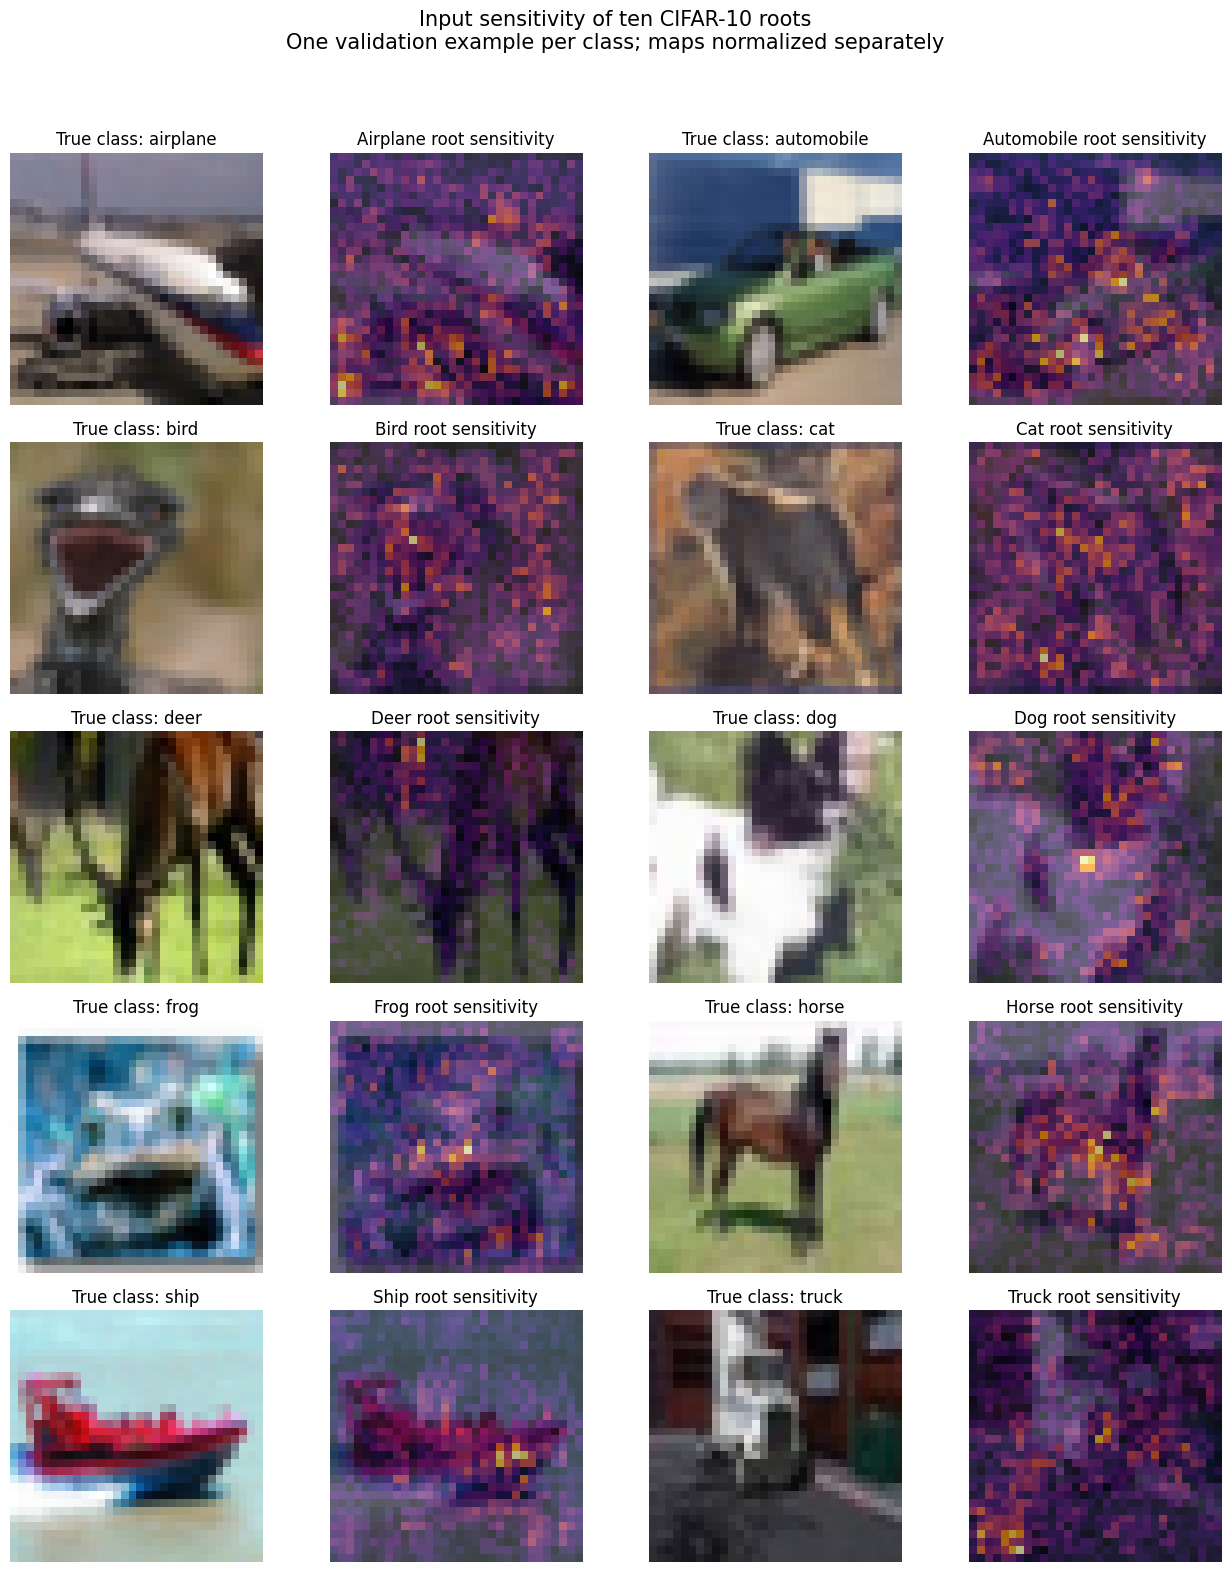

Saved: cifar10_all_root_sensitivity.png
Saved: cifar10_all_root_sensitivity.pdf


In [36]:
# Uses our existing trained trunk and cifar_roots.
trunk.eval()
cifar_roots.eval()


def class_root_sensitivity(image, class_index):
    image_input = (
        image.unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    features = trunk(image_input)
    score = cifar_roots(features)[0, class_index]

    gradient = torch.autograd.grad(
        score, image_input
    )[0]

    heatmap = (
        gradient.abs()
        .amax(dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )

    heatmap /= max(float(heatmap.max()), 1e-12)
    return heatmap


# Select the first validation example of every class.
class_examples = {}

for index in range(len(val_dataset)):
    image, label = val_dataset[index]
    label = int(label)

    if label not in class_examples:
        class_examples[label] = image

    if len(class_examples) == 10:
        break


fig, axes = plt.subplots(5, 4, figsize=(13, 16))

for class_index in range(10):
    row = class_index // 2
    column = 2 * (class_index % 2)

    image = class_examples[class_index]
    image_rgb = image.permute(1, 2, 0).cpu().numpy()
    image_rgb = np.clip(image_rgb, 0, 1)

    heatmap = class_root_sensitivity(image, class_index)
    class_name = full_train_dataset.classes[class_index]

    axes[row, column].imshow(image_rgb)
    axes[row, column].set_title(f"True class: {class_name}")

    axes[row, column + 1].imshow(image_rgb)
    axes[row, column + 1].imshow(
        heatmap,
        cmap="inferno",
        alpha=0.65,
        vmin=0,
        vmax=1
    )
    axes[row, column + 1].set_title(
        f"{class_name.capitalize()} root sensitivity"
    )

for axis in axes.flat:
    axis.axis("off")

fig.suptitle(
    "Input sensitivity of ten CIFAR-10 roots\n"
    "One validation example per class; maps normalized separately",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "cifar10_all_root_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "cifar10_all_root_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved: cifar10_all_root_sensitivity.png")
print("Saved: cifar10_all_root_sensitivity.pdf")

### Observations Across the Ten Root Nodes

The input-gradient maps show spatially distributed sensitivity.
Some strong responses overlap object regions, such as the ship's
hull and the horse's body, while others occur in the background.
The maps therefore do not show consistent object-only localization.

Although all roots share a CNN trunk, each root has independently
learned weights. Their input sensitivities can consequently differ.

These examples provide a qualitative illustration rather than a
class-wide conclusion: only one image per class is shown, and both
the image and root change between examples. Each map is normalized
separately, so brightness does not indicate comparable sensitivity
magnitudes across roots.

## Capacity Sweep: Root Width, Training Fit, and Validation Error

Keep the CNN trunk and dataset split fixed. Train ten independent
binary roots at different hidden widths using the same training
schedule. Measure exact ten-class errors and parameter counts.

This experiment studies the root stage before correction children.
Double descent will be reported only if supported by the results.

In [37]:
import time
import csv
import gc
import torch.nn.functional as F

capacity_widths = [8, 32, 64, 128, 256, 512]
capacity_epochs = 50
capacity_results = []

capacity_train_X = X_train.detach().cpu()
capacity_train_y = y_train.detach().cpu()
capacity_val_X = X_val.detach().cpu()
capacity_val_y = y_val.detach().cpu()

capacity_counts = torch.bincount(
    capacity_train_y, minlength=10
).float()

capacity_pos_weights = (
    (len(capacity_train_y) - capacity_counts)
    / capacity_counts
).to(device)


@torch.no_grad()
def capacity_errors(network, features, labels):
    network.eval()
    errors = 0

    for start in range(0, len(labels), 512):
        batch = features[start:start + 512].to(device)
        predicted = network(batch).argmax(dim=1).cpu()

        errors += (
            predicted != labels[start:start + 512]
        ).sum().item()

    return errors


for width in capacity_widths:
    # Reset the seed and data order for each run.
    torch.manual_seed(42)

    capacity_loader = DataLoader(
        TensorDataset(capacity_train_X, capacity_train_y),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    capacity_model = CIFARRoots(
        feature_mean.detach().cpu(),
        feature_std.detach().cpu(),
        hidden_width=width
    ).to(device)

    capacity_optimizer = torch.optim.Adam(
        capacity_model.parameters(), lr=0.001
    )

    capacity_loss = nn.BCEWithLogitsLoss(
        pos_weight=capacity_pos_weights
    )

    first_zero_error_epoch = None
    capacity_history = []
    start_time = time.perf_counter()

    print(f"\nTRAINING ROOT WIDTH {width}", flush=True)

    for epoch in range(1, capacity_epochs + 1):
        # Same learning-rate schedule for every width.
        if epoch == 25:
            for group in capacity_optimizer.param_groups:
                group["lr"] = 0.0001

        capacity_model.train()

        for features, labels in capacity_loader:
            features = features.to(device)
            labels = labels.to(device)

            binary_targets = F.one_hot(
                labels, num_classes=10
            ).float()

            capacity_optimizer.zero_grad(set_to_none=True)

            scores = capacity_model(features)
            loss = capacity_loss(scores, binary_targets)

            loss.backward()
            capacity_optimizer.step()

        if epoch % 10 == 0:
            train_errors = capacity_errors(
                capacity_model,
                capacity_train_X,
                capacity_train_y
            )

            val_errors = capacity_errors(
                capacity_model,
                capacity_val_X,
                capacity_val_y
            )

            if train_errors == 0 and first_zero_error_epoch is None:
                first_zero_error_epoch = epoch

            capacity_history.append({
                "epoch": epoch,
                "train_errors": train_errors,
                "val_errors": val_errors
            })

            print(
                f"Epoch {epoch}: "
                f"train errors={train_errors} | "
                f"validation errors={val_errors}",
                flush=True
            )

    root_parameters = sum(
        p.numel() for p in capacity_model.parameters()
    )

    total_parameters = root_parameters + sum(
        p.numel() for p in trunk.parameters()
    )

    result = {
        "width": width,
        "root_parameters": root_parameters,
        "total_parameters_with_trunk": total_parameters,
        "train_errors": train_errors,
        "val_errors": val_errors,
        "train_error_percent": (
            100 * train_errors / len(capacity_train_y)
        ),
        "val_error_percent": (
            100 * val_errors / len(capacity_val_y)
        ),
        "first_zero_error_checkpoint": first_zero_error_epoch,
        "seconds": round(time.perf_counter() - start_time, 1)
    }

    capacity_results.append(result)

    # Save each model for possible follow-up correction experiments.
    torch.save({
        "state": {
            name: tensor.detach().cpu()
            for name, tensor in capacity_model.state_dict().items()
        },
        "hidden_width": width,
        "history": capacity_history,
        "result": result
    }, f"cifar10_capacity_width_{width}.pt")

    # Save completed results after every width.
    with open(
        "cifar10_capacity_results.csv",
        "w",
        newline=""
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(result.keys())
        )
        writer.writeheader()
        writer.writerows(capacity_results)

    print(
        f"Width {width} finished | "
        f"train={100 - result['train_error_percent']:.4f}% | "
        f"validation={100 - result['val_error_percent']:.2f}% | "
        f"parameters={total_parameters:,} | "
        f"time={result['seconds']}s",
        flush=True
    )

    del capacity_model, capacity_optimizer
    gc.collect()

    if device.type == "mps":
        torch.mps.empty_cache()

print("\nSweep complete. Saved: cifar10_capacity_results.csv")


TRAINING ROOT WIDTH 8
Epoch 10: train errors=7552 | validation errors=1693
Epoch 20: train errors=4059 | validation errors=1724
Epoch 30: train errors=2414 | validation errors=1720
Epoch 40: train errors=2122 | validation errors=1741
Epoch 50: train errors=1856 | validation errors=1758
Width 8 finished | train=95.8756% | validation=64.84% | parameters=169,098 | time=45.8s

TRAINING ROOT WIDTH 32
Epoch 10: train errors=2455 | validation errors=1554
Epoch 20: train errors=274 | validation errors=1588
Epoch 30: train errors=43 | validation errors=1545
Epoch 40: train errors=24 | validation errors=1541
Epoch 50: train errors=10 | validation errors=1539
Width 32 finished | train=99.9778% | validation=69.22% | parameters=661,098 | time=51.1s

TRAINING ROOT WIDTH 64
Epoch 10: train errors=1200 | validation errors=1485
Epoch 20: train errors=69 | validation errors=1470
Epoch 30: train errors=7 | validation errors=1481
Epoch 40: train errors=4 | validation errors=1488
Epoch 50: train errors=2 

## Capacity Sweep Results: Accuracy and Model Size

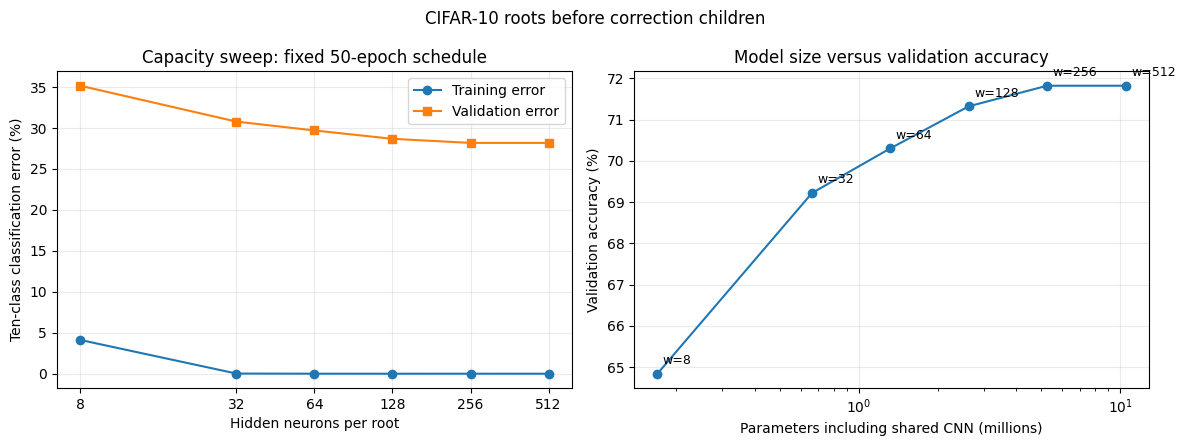

In [38]:
import csv
import matplotlib.pyplot as plt

# Read the saved results so this also works after a notebook restart.
with open("cifar10_capacity_results.csv", newline="") as file:
    sweep_rows = list(csv.DictReader(file))

sweep_rows.sort(key=lambda row: int(row["width"]))

widths = [int(row["width"]) for row in sweep_rows]
parameters = [
    int(row["total_parameters_with_trunk"])
    for row in sweep_rows
]
train_error = [
    float(row["train_error_percent"])
    for row in sweep_rows
]
val_error = [
    float(row["val_error_percent"])
    for row in sweep_rows
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel 1: capacity versus error.
axes[0].plot(widths, train_error, "o-", label="Training error")
axes[0].plot(widths, val_error, "s-", label="Validation error")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(widths)
axes[0].set_xticklabels(widths)
axes[0].set_xlabel("Hidden neurons per root")
axes[0].set_ylabel("Ten-class classification error (%)")
axes[0].set_title("Capacity sweep: fixed 50-epoch schedule")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Panel 2: size versus validation performance.
axes[1].plot(
    [count / 1e6 for count in parameters],
    [100 - error for error in val_error],
    "o-"
)

for count, error, width in zip(parameters, val_error, widths):
    axes[1].annotate(
        f"w={width}",
        (count / 1e6, 100 - error),
        xytext=(4, 7),
        textcoords="offset points",
        fontsize=9
    )

axes[1].set_xscale("log")
axes[1].set_xlabel("Parameters including shared CNN (millions)")
axes[1].set_ylabel("Validation accuracy (%)")
axes[1].set_title("Model size versus validation accuracy")
axes[1].grid(alpha=0.25)

fig.suptitle("CIFAR-10 roots before correction children")
plt.tight_layout()

plt.savefig(
    "cifar10_capacity_sweep.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "cifar10_capacity_sweep.pdf",
    bbox_inches="tight"
)
plt.show()

### Capacity and Size Findings

Increasing root width reduced final validation error from 35.16%
at width 8 to 28.18% at widths 256 and 512. This sweep did not
show a validation-error peak followed by a second descent.

No root-only run achieved exactly zero training errors within
50 epochs. Consequently, the experiment does not clearly establish
behavior beyond the exact interpolation threshold.

Width 32 was the smallest tested root-stage model achieving
greater than 99.9% training accuracy. It used 661,098 parameters,
approximately 87.4% fewer than width 256, with lower validation
accuracy (69.22% versus 71.82%).

These are exploratory results from one run per width with a fixed
training budget. They do not establish the minimum possible model
size or rule out double descent under other training conditions.

## Cats vs Dogs: Downloading the Separate Dataset

In [43]:
%pip install --upgrade certifi


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [44]:
import ssl
import certifi
import urllib.request

catsdogs_ssl_context = ssl.create_default_context(
    cafile=certifi.where()
)

catsdogs_download_opener = urllib.request.build_opener(
    urllib.request.HTTPSHandler(context=catsdogs_ssl_context)
)

urllib.request.install_opener(catsdogs_download_opener)

print("Certificate bundle configured.")

Certificate bundle configured.


## Cats vs Dogs: Downloading the Separate Dataset

In [45]:
from pathlib import Path
import urllib.request
import zipfile

# Separate variables and folders from our CIFAR experiment.
catsdogs_folder = Path("data/cats_vs_dogs")
catsdogs_folder.mkdir(parents=True, exist_ok=True)

catsdogs_zip = catsdogs_folder / "kagglecatsanddogs_5340.zip"
catsdogs_images = catsdogs_folder / "PetImages"

catsdogs_url = (
    "https://download.microsoft.com/download/"
    "3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/"
    "kagglecatsanddogs_5340.zip"
)

if not catsdogs_images.exists():
    if not catsdogs_zip.exists():
        print("Downloading Cats vs Dogs. This may take a few minutes.",
              flush=True)

        # Download to a temporary file so an interrupted download
        # is not mistaken for a completed archive.
        temporary_zip = catsdogs_zip.with_suffix(".zip.part")
        urllib.request.urlretrieve(catsdogs_url, temporary_zip)
        temporary_zip.replace(catsdogs_zip)

        print("Download complete.", flush=True)

    print("Extracting images...", flush=True)

    with zipfile.ZipFile(catsdogs_zip, "r") as archive:
        archive.extractall(catsdogs_folder)

for class_name in ["Cat", "Dog"]:
    class_folder = catsdogs_images / class_name

    if not class_folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {class_folder}")

    count = len(list(class_folder.glob("*.jpg")))
    print(f"{class_name}: {count} JPEG files")

print("Dataset location:", catsdogs_images.resolve())

Download complete.
Extracting images...
Cat: 12500 JPEG files
Dog: 12500 JPEG files
Dataset location: /Users/aroma/data/cats_vs_dogs/PetImages


## Cats vs Dogs: Image Validation and Reproducible Dataset Splits

In [46]:
from pathlib import Path
from PIL import Image
import numpy as np
import csv

catsdogs_images = Path(
    "/Users/aroma/data/cats_vs_dogs/PetImages"
)

# Cat = 0, Dog = 1.
catsdogs_class_names = ["Cat", "Dog"]
catsdogs_valid_files = {0: [], 1: []}
catsdogs_invalid_files = []

for label, class_name in enumerate(catsdogs_class_names):
    image_paths = sorted(
        (catsdogs_images / class_name).glob("*.jpg")
    )

    print(f"Checking {class_name} images...", flush=True)

    for path in image_paths:
        try:
            # Fully decode the image, matching our RGB loading step.
            with Image.open(path) as image:
                image.convert("RGB").load()

            catsdogs_valid_files[label].append(path)

        except Exception as error:
            # Record invalid files without deleting the originals.
            catsdogs_invalid_files.append(
                (str(path), str(error))
            )

    print(
        f"{class_name}: "
        f"{len(catsdogs_valid_files[label])} valid images",
        flush=True
    )


# Split each class independently with a fixed seed.
catsdogs_rng = np.random.default_rng(42)

catsdogs_splits = {
    "train": [],
    "validation": [],
    "test": []
}

for label, paths in catsdogs_valid_files.items():
    order = catsdogs_rng.permutation(len(paths))

    train_end = int(0.80 * len(paths))
    validation_end = train_end + int(0.10 * len(paths))

    class_split_indices = {
        "train": order[:train_end],
        "validation": order[train_end:validation_end],
        "test": order[validation_end:]
    }

    for split_name, indices in class_split_indices.items():
        catsdogs_splits[split_name].extend(
            (paths[int(index)], label)
            for index in indices
        )


# Confirm that no file appears in more than one split.
split_path_sets = {
    name: {str(path) for path, label in samples}
    for name, samples in catsdogs_splits.items()
}

assert split_path_sets["train"].isdisjoint(
    split_path_sets["validation"]
)
assert split_path_sets["train"].isdisjoint(
    split_path_sets["test"]
)
assert split_path_sets["validation"].isdisjoint(
    split_path_sets["test"]
)


# Save relative file paths so the split can be reused elsewhere.
catsdogs_manifest = catsdogs_images.parent / "split_manifest.csv"

with catsdogs_manifest.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["relative_path", "label", "class", "split"])

    for split_name, samples in catsdogs_splits.items():
        for path, label in samples:
            writer.writerow([
                str(path.relative_to(catsdogs_images)),
                label,
                catsdogs_class_names[label],
                split_name
            ])


catsdogs_invalid_log = (
    catsdogs_images.parent / "invalid_images.csv"
)

with catsdogs_invalid_log.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["path", "error"])
    writer.writerows(catsdogs_invalid_files)


print("\nExcluded unreadable images:", len(catsdogs_invalid_files))

for split_name, samples in catsdogs_splits.items():
    cats = sum(label == 0 for path, label in samples)
    dogs = sum(label == 1 for path, label in samples)

    print(
        f"{split_name.upper()}: {len(samples)} images "
        f"| cats={cats} | dogs={dogs}"
    )

print("\nSaved split manifest:", catsdogs_manifest)
print("Saved invalid-image log:", catsdogs_invalid_log)

Checking Cat images...
Cat: 12499 valid images
Checking Dog images...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/PIL/TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog: 12499 valid images

Excluded unreadable images: 2
TRAIN: 19998 images | cats=9999 | dogs=9999
VALIDATION: 2498 images | cats=1249 | dogs=1249
TEST: 2502 images | cats=1251 | dogs=1251

Saved split manifest: /Users/aroma/data/cats_vs_dogs/split_manifest.csv
Saved invalid-image log: /Users/aroma/data/cats_vs_dogs/invalid_images.csv


## Cats vs Dogs: Shared CNN Trunk and Binary Root

In [47]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image


class CatsDogsDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        with Image.open(path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return image, label


catsdogs_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

catsdogs_train_dataset = CatsDogsDataset(
    catsdogs_splits["train"], catsdogs_transform
)
catsdogs_val_dataset = CatsDogsDataset(
    catsdogs_splits["validation"], catsdogs_transform
)
catsdogs_test_dataset = CatsDogsDataset(
    catsdogs_splits["test"], catsdogs_transform
)

catsdogs_train_loader = DataLoader(
    catsdogs_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

catsdogs_val_loader = DataLoader(
    catsdogs_val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)


# Fresh networks: these do not modify our CIFAR model.
torch.manual_seed(42)

catsdogs_trunk = CNNTrunk().to(device)

catsdogs_root = BinaryNode(
    input_dim=2048,
    hidden_width=128
).to(device)

catsdogs_model = nn.Sequential(
    catsdogs_trunk,
    catsdogs_root
).to(device)

# Label convention: Cat=0, Dog=1.
catsdogs_criterion = nn.BCEWithLogitsLoss()

catsdogs_optimizer = torch.optim.Adam(
    catsdogs_model.parameters(),
    lr=0.001
)

catsdogs_history = []

# Check the shapes without using the test set.
sample_images, sample_labels = next(
    iter(catsdogs_train_loader)
)

with torch.no_grad():
    sample_features = catsdogs_trunk(
        sample_images.to(device)
    )
    sample_scores = catsdogs_model(
        sample_images.to(device)
    )

print("Device:", device)
print("Image batch:", sample_images.shape)
print("CNN features:", sample_features.shape)
print("Binary scores:", sample_scores.shape)
print("Labels: Cat=0, Dog=1")

print(
    "Parameters:",
    f"{sum(p.numel() for p in catsdogs_model.parameters()):,}"
)

Device: mps
Image batch: torch.Size([128, 3, 32, 32])
CNN features: torch.Size([128, 2048])
Binary scores: torch.Size([128])
Labels: Cat=0, Dog=1
Parameters: 267,489


In [48]:
import time

# A non-shuffled loader for measuring training accuracy.
catsdogs_train_eval_loader = DataLoader(
    catsdogs_train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)


@torch.no_grad()
def evaluate_catsdogs(network, loader):
    network.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        targets = labels.to(device).float()

        scores = network(images)
        loss = catsdogs_criterion(scores, targets)

        predicted = scores >= 0
        correct += (
            predicted == targets.bool()
        ).sum().item()

        total_loss += loss.item() * len(labels)
        total += len(labels)

    return total_loss / total, 100 * correct / total


for _ in range(20):
    epoch = len(catsdogs_history) + 1
    start = time.perf_counter()

    catsdogs_model.train()

    for images, labels in catsdogs_train_loader:
        images = images.to(device)
        targets = labels.to(device).float()

        catsdogs_optimizer.zero_grad(set_to_none=True)

        scores = catsdogs_model(images)
        loss = catsdogs_criterion(scores, targets)

        loss.backward()
        catsdogs_optimizer.step()

    train_loss, train_accuracy = evaluate_catsdogs(
        catsdogs_model, catsdogs_train_eval_loader
    )

    val_loss, val_accuracy = evaluate_catsdogs(
        catsdogs_model, catsdogs_val_loader
    )

    catsdogs_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    # Save after every epoch.
    torch.save({
        "trunk_state": catsdogs_trunk.state_dict(),
        "root_state": catsdogs_root.state_dict(),
        "optimizer_state": catsdogs_optimizer.state_dict(),
        "root_hidden_width": 128,
        "image_size": 32,
        "class_names": ["Cat", "Dog"],
        "history": catsdogs_history
    }, "catsdogs_root_checkpoint.pt")

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"accuracy={train_accuracy:.2f}% | "
        f"val loss={val_loss:.3f}, "
        f"accuracy={val_accuracy:.2f}% | "
        f"time={time.perf_counter() - start:.1f}s",
        flush=True
    )

Epoch 1: train loss=0.596, accuracy=68.35% | val loss=0.606, accuracy=68.21% | time=30.9s
Epoch 2: train loss=0.549, accuracy=72.50% | val loss=0.563, accuracy=71.22% | time=31.3s
Epoch 3: train loss=0.570, accuracy=69.71% | val loss=0.585, accuracy=68.98% | time=30.6s
Epoch 4: train loss=0.509, accuracy=74.96% | val loss=0.533, accuracy=73.34% | time=32.4s
Epoch 5: train loss=0.462, accuracy=78.53% | val loss=0.494, accuracy=76.54% | time=31.1s
Epoch 6: train loss=0.465, accuracy=78.07% | val loss=0.491, accuracy=76.70% | time=32.1s
Epoch 7: train loss=0.463, accuracy=78.02% | val loss=0.496, accuracy=76.06% | time=31.0s
Epoch 8: train loss=0.430, accuracy=80.39% | val loss=0.472, accuracy=77.94% | time=31.1s
Epoch 9: train loss=0.421, accuracy=80.81% | val loss=0.480, accuracy=77.02% | time=30.9s
Epoch 10: train loss=0.419, accuracy=80.68% | val loss=0.481, accuracy=77.10% | time=29.8s
Epoch 11: train loss=0.393, accuracy=82.27% | val loss=0.466, accuracy=78.10% | time=31.3s
Epoch 12

## Cats vs Dogs: Freezing the Trunk and Caching Features

In [49]:
from torch.utils.data import TensorDataset

# Freeze only the Cats vs Dogs trunk.
catsdogs_trunk.eval()

for parameter in catsdogs_trunk.parameters():
    parameter.requires_grad_(False)


@torch.no_grad()
def extract_catsdogs_features(loader):
    feature_batches = []
    label_batches = []

    for images, labels in loader:
        features = catsdogs_trunk(images.to(device))

        feature_batches.append(features.cpu())
        label_batches.append(labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )


# Use non-shuffled loaders to preserve image-to-feature alignment.
catsdogs_X_train, catsdogs_y_train = extract_catsdogs_features(
    catsdogs_train_eval_loader
)

catsdogs_X_val, catsdogs_y_val = extract_catsdogs_features(
    catsdogs_val_loader
)

# Calculate normalization using training features only.
catsdogs_feature_mean = catsdogs_X_train.mean(dim=0)
catsdogs_feature_std = (
    catsdogs_X_train.std(dim=0).clamp_min(1e-6)
)

catsdogs_Z_train = (
    catsdogs_X_train - catsdogs_feature_mean
) / catsdogs_feature_std

catsdogs_Z_val = (
    catsdogs_X_val - catsdogs_feature_mean
) / catsdogs_feature_std

torch.save({
    "train_features": catsdogs_X_train,
    "train_labels": catsdogs_y_train,
    "validation_features": catsdogs_X_val,
    "validation_labels": catsdogs_y_val,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std
}, "catsdogs_cached_features.pt")

print("Training features:", catsdogs_X_train.shape)
print("Training labels:", catsdogs_y_train.shape)
print("Validation features:", catsdogs_X_val.shape)
print("CNN trunk frozen.")
print("Saved: catsdogs_cached_features.pt")

Training features: torch.Size([19998, 2048])
Training labels: torch.Size([19998])
Validation features: torch.Size([2498, 2048])
CNN trunk frozen.
Saved: catsdogs_cached_features.pt


## Cats vs Dogs: Fitting a Binary Root on Frozen CNN Features

In [50]:
import time

torch.manual_seed(42)

# A fresh root receiving standardized features.
catsdogs_feature_root = BinaryNode(
    input_dim=2048,
    hidden_width=128
).to(device)

catsdogs_feature_optimizer = torch.optim.Adam(
    catsdogs_feature_root.parameters(),
    lr=0.001
)

catsdogs_feature_loss = nn.BCEWithLogitsLoss()

catsdogs_feature_loader = DataLoader(
    TensorDataset(
        catsdogs_Z_train,
        catsdogs_y_train.float()
    ),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

catsdogs_feature_history = []


@torch.no_grad()
def evaluate_catsdogs_node(node, features, labels):
    node.eval()
    scores = torch.cat([
        node(batch.to(device)).cpu()
        for batch in features.split(512)
    ])

    predictions = scores >= 0
    actual = labels.cpu().bool()

    errors = (predictions != actual).sum().item()

    # Dog = positive class; Cat = negative class.
    missed_dogs = ((~predictions) & actual).sum().item()
    false_dogs = (predictions & (~actual)).sum().item()

    accuracy = 100 * (1 - errors / len(actual))

    return accuracy, errors, missed_dogs, false_dogs


start_time = time.perf_counter()

for epoch in range(1, 101):
    if epoch == 51:
        for group in catsdogs_feature_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_feature_root.train()

    for features, targets in catsdogs_feature_loader:
        features = features.to(device)
        targets = targets.to(device)

        catsdogs_feature_optimizer.zero_grad(set_to_none=True)

        scores = catsdogs_feature_root(features)
        loss = catsdogs_feature_loss(scores, targets)

        loss.backward()
        catsdogs_feature_optimizer.step()

    if epoch % 10 == 0:
        train_result = evaluate_catsdogs_node(
            catsdogs_feature_root,
            catsdogs_Z_train,
            catsdogs_y_train
        )

        val_result = evaluate_catsdogs_node(
            catsdogs_feature_root,
            catsdogs_Z_val,
            catsdogs_y_val
        )

        catsdogs_feature_history.append({
            "epoch": epoch,
            "train_accuracy": train_result[0],
            "train_errors": train_result[1],
            "val_accuracy": val_result[0],
            "val_errors": val_result[1]
        })

        torch.save({
            "state": catsdogs_feature_root.state_dict(),
            "optimizer_state": catsdogs_feature_optimizer.state_dict(),
            "hidden_width": 128,
            "feature_mean": catsdogs_feature_mean,
            "feature_std": catsdogs_feature_std,
            "history": catsdogs_feature_history
        }, "catsdogs_feature_root.pt")

        print(
            f"Epoch {epoch}: "
            f"train={train_result[0]:.4f}% | "
            f"errors={train_result[1]} | "
            f"missed dogs={train_result[2]} | "
            f"false dogs={train_result[3]} | "
            f"validation={val_result[0]:.2f}%",
            flush=True
        )

print(f"Finished in {time.perf_counter() - start_time:.1f}s")

Epoch 10: train=99.8900% | errors=22 | missed dogs=18 | false dogs=4 | validation=80.02%
Epoch 20: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.94%
Epoch 30: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.30%
Epoch 40: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.58%
Epoch 50: train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=79.82%
Epoch 60: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.86%
Epoch 70: train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=79.70%
Epoch 80: train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=79.94%
Epoch 90: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.74%
Epoch 100: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.78%
Finished in 21.0s


## Cats vs Dogs: Training the Downward Correction Child

In [51]:
import copy

catsdogs_feature_root.eval()

with torch.no_grad():
    catsdogs_root_train_scores = torch.cat([
        catsdogs_feature_root(batch.to(device)).cpu()
        for batch in catsdogs_Z_train.split(512)
    ])

catsdogs_actual_dog = catsdogs_y_train.bool()
catsdogs_predicted_dog = catsdogs_root_train_scores >= 0

catsdogs_false_dogs = (
    catsdogs_predicted_dog & (~catsdogs_actual_dog)
)

# Protect genuine dogs and correct false dog predictions.
# Correctly rejected cats are ignored for this child's task.
catsdogs_B_mask = catsdogs_actual_dog | catsdogs_false_dogs

catsdogs_B_features = catsdogs_Z_train[catsdogs_B_mask]
catsdogs_B_targets = (
    catsdogs_false_dogs[catsdogs_B_mask].float()
)

positive_count = int(catsdogs_B_targets.sum().item())
negative_count = len(catsdogs_B_targets) - positive_count

print("False dog predictions to correct:", positive_count)
print("Actual dogs to protect:", negative_count)

if positive_count == 0:
    raise ValueError("No downward correction child is needed.")

torch.manual_seed(42)

catsdogs_child_B = BinaryNode(
    input_dim=2048,
    hidden_width=32
).to(device)

catsdogs_B_optimizer = torch.optim.Adam(
    catsdogs_child_B.parameters(), lr=0.001
)

catsdogs_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [negative_count / positive_count],
        device=device
    )
)

catsdogs_B_loader = DataLoader(
    TensorDataset(catsdogs_B_features, catsdogs_B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

# Keep the best checked child, rather than only the last epoch.
catsdogs_B_best_key = None
catsdogs_B_best_state = None
catsdogs_B_best_epoch = None

for epoch in range(1, 101):
    if epoch == 51:
        for group in catsdogs_B_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_child_B.train()

    for features, targets in catsdogs_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        catsdogs_B_optimizer.zero_grad(set_to_none=True)

        loss = catsdogs_B_loss(
            catsdogs_child_B(features), targets
        )

        loss.backward()
        catsdogs_B_optimizer.step()

    if epoch % 10 == 0:
        _, _, missed, unwanted = evaluate_catsdogs_node(
            catsdogs_child_B,
            catsdogs_B_features,
            catsdogs_B_targets
        )

        # Prioritize detecting both root errors, then protecting dogs.
        key = (missed, unwanted)

        if catsdogs_B_best_key is None or key < catsdogs_B_best_key:
            catsdogs_B_best_key = key
            catsdogs_B_best_epoch = epoch
            catsdogs_B_best_state = copy.deepcopy(
                catsdogs_child_B.state_dict()
            )

        print(
            f"Epoch {epoch}: "
            f"missed corrections={missed} | "
            f"dogs flagged for unwanted correction={unwanted}",
            flush=True
        )

        if missed == 0 and unwanted == 0:
            break

catsdogs_child_B.load_state_dict(catsdogs_B_best_state)
catsdogs_child_B.eval()

torch.save({
    "state": catsdogs_child_B.state_dict(),
    "hidden_width": 32,
    "best_epoch": catsdogs_B_best_epoch,
    "task_errors": {
        "missed_corrections": catsdogs_B_best_key[0],
        "unwanted_corrections": catsdogs_B_best_key[1]
    },
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std
}, "catsdogs_downward_child.pt")

print(
    f"Restored epoch {catsdogs_B_best_epoch}: "
    f"missed={catsdogs_B_best_key[0]}, "
    f"unwanted={catsdogs_B_best_key[1]}"
)

False dog predictions to correct: 2
Actual dogs to protect: 9999
Epoch 10: missed corrections=0 | dogs flagged for unwanted correction=24
Epoch 20: missed corrections=0 | dogs flagged for unwanted correction=5
Epoch 30: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 40: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 50: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 60: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 70: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 80: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 90: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 100: missed corrections=0 | dogs flagged for unwanted correction=4
Restored epoch 30: missed=0, unwanted=4


## Cats vs Dogs: Selecting the Correction Strength and Evaluating the Tree

In [52]:
@torch.no_grad()
def catsdogs_tree_components(features):
    catsdogs_feature_root.eval()
    catsdogs_child_B.eval()

    root_scores = []
    child_flags = []

    for batch in features.split(512):
        batch = batch.to(device)

        root_scores.append(
            catsdogs_feature_root(batch).cpu()
        )
        child_flags.append(
            (catsdogs_child_B(batch) >= 0).cpu()
        )

    return torch.cat(root_scores), torch.cat(child_flags)


cd_train_scores, cd_train_flags = catsdogs_tree_components(
    catsdogs_Z_train
)

cd_actual = catsdogs_y_train.cpu().bool()

# Predictions can change only when b crosses a flagged image's
# root score. Check every nonnegative breakpoint and the intervals.
cd_breakpoints = torch.unique(
    cd_train_scores[
        cd_train_flags & (cd_train_scores >= 0)
    ].double()
).sort().values

cd_candidates = [0.0]

if len(cd_breakpoints):
    first = cd_breakpoints[0].item()

    if first > 0:
        cd_candidates.append(first / 2)

    cd_candidates.extend(cd_breakpoints.tolist())

    cd_candidates.extend(
        (
            (cd_breakpoints[:-1] + cd_breakpoints[1:]) / 2
        ).tolist()
    )

    last = cd_breakpoints[-1].item()
    cd_candidates.append(last + max(1.0, abs(last) * 0.01))

cd_best_key = None
catsdogs_best_b = 0.0

for b in sorted(set(cd_candidates)):
    corrected_scores = (
        cd_train_scores.double() - b * cd_train_flags.double()
    )
    predicted = corrected_scores >= 0

    errors = (predicted != cd_actual).sum().item()

    # Prefer fewer training errors, then a smaller correction.
    key = (errors, b)

    if cd_best_key is None or key < cd_best_key:
        cd_best_key = key
        catsdogs_best_b = b

print(f"Selected correction strength b = {catsdogs_best_b:.8f}")


def report_catsdogs_tree(name, scores, flags, labels):
    actual = labels.cpu().bool()

    results = {}

    for model_name, strength in [
        ("Root", 0.0),
        ("Root + child B", catsdogs_best_b)
    ]:
        corrected_scores = (
            scores.double() - strength * flags.double()
        )
        predicted = corrected_scores >= 0

        errors = (predicted != actual).sum().item()
        missed_dogs = ((~predicted) & actual).sum().item()
        false_dogs = (predicted & (~actual)).sum().item()
        accuracy = 100 * (1 - errors / len(actual))

        results[model_name] = {
            "accuracy": accuracy,
            "errors": errors,
            "missed_dogs": missed_dogs,
            "false_dogs": false_dogs
        }

        print(
            f"{name} | {model_name}: "
            f"accuracy={accuracy:.4f}% | errors={errors} | "
            f"missed dogs={missed_dogs} | false dogs={false_dogs}"
        )

    return results


catsdogs_tree_train_results = report_catsdogs_tree(
    "TRAIN",
    cd_train_scores,
    cd_train_flags,
    catsdogs_y_train
)

cd_val_scores, cd_val_flags = catsdogs_tree_components(
    catsdogs_Z_val
)

catsdogs_tree_val_results = report_catsdogs_tree(
    "VALIDATION",
    cd_val_scores,
    cd_val_flags,
    catsdogs_y_val
)

Selected correction strength b = 0.00000000
TRAIN | Root: accuracy=99.9900% | errors=2 | missed dogs=0 | false dogs=2
TRAIN | Root + child B: accuracy=99.9900% | errors=2 | missed dogs=0 | false dogs=2
VALIDATION | Root: accuracy=79.7838% | errors=505 | missed dogs=261 | false dogs=244
VALIDATION | Root + child B: accuracy=79.7838% | errors=505 | missed dogs=261 | false dogs=244


## Diagnosing the Downward Child: Root-Score Margins

In [53]:
# Both mistaken cats and genuine dogs activate child B.
# Compare their root scores: subtraction must cross these scores
# to change a dog prediction into a cat prediction.

cd_false_dog_mask = (
    (~cd_actual) & (cd_train_scores >= 0)
)

cd_flagged_dog_mask = cd_actual & cd_train_flags

print("Root scores of the two cats predicted as dogs:")
print(cd_train_scores[cd_false_dog_mask].tolist())

print("\nRoot scores of genuine dogs flagged by child B:")
print(cd_train_scores[cd_flagged_dog_mask].tolist())

print("\nChild detects both mistaken cats:",
      bool(cd_train_flags[cd_false_dog_mask].all()))

Root scores of the two cats predicted as dogs:
[0.5933709144592285, 2.585129499435425]

Root scores of genuine dogs flagged by child B:
[0.5933709144592285, 2.585129499435425, 2.585129499435425, 2.585129499435425]

Child detects both mistaken cats: True


## Checking Opposite-Label Examples for Identical Features and Images

In [54]:
cd_bad_cat_indices = torch.where(cd_false_dog_mask)[0]
cd_dog_indices = torch.where(catsdogs_y_train == 1)[0]

for cat_index_tensor in cd_bad_cat_indices:
    cat_index = int(cat_index_tensor)
    cat_features = catsdogs_X_train[cat_index]

    # Find genuine dogs with exactly the same cached CNN features.
    matching_dogs = []

    for dog_indices in cd_dog_indices.split(512):
        dog_features = catsdogs_X_train[dog_indices]

        identical = (dog_features == cat_features).all(dim=1)

        matching_dogs.extend(
            dog_indices[identical].tolist()
        )

    cat_path = catsdogs_train_dataset.samples[cat_index][0]
    cat_image, _ = catsdogs_train_dataset[cat_index]

    print("\nCAT:", cat_path)
    print("Dogs with identical CNN features:", len(matching_dogs))

    for dog_index in matching_dogs:
        dog_path = catsdogs_train_dataset.samples[dog_index][0]
        dog_image, _ = catsdogs_train_dataset[dog_index]

        same_resized_image = torch.equal(cat_image, dog_image)

        print("  DOG:", dog_path)
        print("  Identical 32x32 image:", same_resized_image)
        print(
            "  Maximum pixel difference:",
            (cat_image - dog_image).abs().max().item()
        )


CAT: /Users/aroma/data/cats_vs_dogs/PetImages/Cat/8456.jpg
Dogs with identical CNN features: 1
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/8736.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0

CAT: /Users/aroma/data/cats_vs_dogs/PetImages/Cat/11565.jpg
Dogs with identical CNN features: 3
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/2877.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/10797.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/10401.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0


### Conflicting Labels Impose an Interpolation Limit

Two groups of training examples have exactly identical images
after 32 × 32 preprocessing but conflicting Cat/Dog labels.
The groups contain one cat and one dog, and one cat and three
dogs, respectively.

Any deterministic classifier operating on these inputs must
make at least two training errors. Our root makes exactly two
errors, achieving 99.99% accuracy and attaining this upper bound.

The downward child activates on both mistaken cats and their
identical dog counterparts. Consequently, its corrections cannot
separate these examples. Training-based selection chooses b=0,
leaving the root predictions unchanged.

This finding applies to the current preprocessing; it does not
establish that the original full-resolution files are identical.

## Cats vs Dogs: A Smaller Root for the Correction-Tree Experiment

In [55]:
torch.manual_seed(42)

catsdogs_small_root = BinaryNode(
    input_dim=2048,
    hidden_width=8
).to(device)

catsdogs_small_optimizer = torch.optim.Adam(
    catsdogs_small_root.parameters(), lr=0.001
)

catsdogs_small_loss = nn.BCEWithLogitsLoss()

catsdogs_small_loader = DataLoader(
    TensorDataset(
        catsdogs_Z_train,
        catsdogs_y_train.float()
    ),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

catsdogs_small_history = []

for epoch in range(1, 101):
    if epoch == 51:
        for group in catsdogs_small_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_small_root.train()

    for features, targets in catsdogs_small_loader:
        features = features.to(device)
        targets = targets.to(device)

        catsdogs_small_optimizer.zero_grad(set_to_none=True)

        loss = catsdogs_small_loss(
            catsdogs_small_root(features), targets
        )

        loss.backward()
        catsdogs_small_optimizer.step()

    if epoch % 10 == 0:
        train_result = evaluate_catsdogs_node(
            catsdogs_small_root,
            catsdogs_Z_train,
            catsdogs_y_train
        )

        val_result = evaluate_catsdogs_node(
            catsdogs_small_root,
            catsdogs_Z_val,
            catsdogs_y_val
        )

        catsdogs_small_history.append({
            "epoch": epoch,
            "train_accuracy": train_result[0],
            "train_errors": train_result[1],
            "val_accuracy": val_result[0],
            "val_errors": val_result[1]
        })

        print(
            f"Epoch {epoch}: "
            f"train={train_result[0]:.4f}% | "
            f"errors={train_result[1]} | "
            f"missed dogs={train_result[2]} | "
            f"false dogs={train_result[3]} | "
            f"validation={val_result[0]:.2f}%",
            flush=True
        )

torch.save({
    "state": catsdogs_small_root.state_dict(),
    "hidden_width": 8,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std,
    "history": catsdogs_small_history
}, "catsdogs_small_root.pt")

small_root_parameters = sum(
    p.numel() for p in catsdogs_small_root.parameters()
)
trunk_parameters = sum(
    p.numel() for p in catsdogs_trunk.parameters()
)

print(
    "Small root + shared CNN parameters:",
    f"{small_root_parameters + trunk_parameters:,}"
)

Epoch 10: train=93.0093% | errors=1398 | missed dogs=583 | false dogs=815 | validation=79.98%
Epoch 20: train=97.1197% | errors=576 | missed dogs=326 | false dogs=250 | validation=79.18%
Epoch 30: train=99.0599% | errors=188 | missed dogs=105 | false dogs=83 | validation=78.86%
Epoch 40: train=99.5950% | errors=81 | missed dogs=10 | false dogs=71 | validation=78.86%
Epoch 50: train=99.7300% | errors=54 | missed dogs=1 | false dogs=53 | validation=78.50%
Epoch 60: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.38%
Epoch 70: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.62%
Epoch 80: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.54%
Epoch 90: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.30%
Epoch 100: train=99.7400% | errors=52 | missed dogs=0 | false dogs=52 | validation=78.58%
Small root + shared CNN parameters: 21,489


## Cats vs Dogs: An Eight-Neuron Downward Child for the Small Root

In [56]:
import copy

catsdogs_small_root.eval()

with torch.no_grad():
    cd_small_train_scores = torch.cat([
        catsdogs_small_root(batch.to(device)).cpu()
        for batch in catsdogs_Z_train.split(512)
    ])

cd_small_actual_dog = catsdogs_y_train.bool()
cd_small_predicted_dog = cd_small_train_scores >= 0

cd_small_false_dogs = (
    cd_small_predicted_dog & (~cd_small_actual_dog)
)

# Child should activate on false dogs and remain off on genuine dogs.
cd_small_B_mask = cd_small_actual_dog | cd_small_false_dogs
cd_small_B_features = catsdogs_Z_train[cd_small_B_mask]
cd_small_B_targets = (
    cd_small_false_dogs[cd_small_B_mask].float()
)

cd_small_positive_count = int(cd_small_B_targets.sum().item())
cd_small_negative_count = (
    len(cd_small_B_targets) - cd_small_positive_count
)

print("False dog predictions:", cd_small_positive_count)
print("Genuine dogs to protect:", cd_small_negative_count)

if cd_small_positive_count == 0:
    raise ValueError("No downward child is needed.")

torch.manual_seed(42)

catsdogs_small_child_B = BinaryNode(
    input_dim=2048, hidden_width=8
).to(device)

cd_small_B_optimizer = torch.optim.Adam(
    catsdogs_small_child_B.parameters(), lr=0.001
)

cd_small_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [cd_small_negative_count / cd_small_positive_count],
        device=device
    )
)

cd_small_B_loader = DataLoader(
    TensorDataset(cd_small_B_features, cd_small_B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

cd_small_B_best_key = None
cd_small_B_best_state = None
cd_small_B_best_epoch = None
cd_small_B_history = []

for epoch in range(1, 101):
    if epoch == 51:
        for group in cd_small_B_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_small_child_B.train()

    for features, targets in cd_small_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        cd_small_B_optimizer.zero_grad(set_to_none=True)

        loss = cd_small_B_loss(
            catsdogs_small_child_B(features), targets
        )
        loss.backward()
        cd_small_B_optimizer.step()

    if epoch % 10 == 0:
        _, _, missed, unwanted = evaluate_catsdogs_node(
            catsdogs_small_child_B,
            cd_small_B_features,
            cd_small_B_targets
        )

        # Balance the two task error rates for checkpoint selection.
        balanced_error = 0.5 * (
            missed / cd_small_positive_count
            + unwanted / cd_small_negative_count
        )
        key = (balanced_error, missed + unwanted)

        cd_small_B_history.append({
            "epoch": epoch,
            "missed_corrections": missed,
            "unwanted_corrections": unwanted,
            "balanced_error": balanced_error
        })

        if cd_small_B_best_key is None or key < cd_small_B_best_key:
            cd_small_B_best_key = key
            cd_small_B_best_epoch = epoch
            cd_small_B_best_state = copy.deepcopy(
                catsdogs_small_child_B.state_dict()
            )

        print(
            f"Epoch {epoch}: missed corrections={missed} | "
            f"dogs flagged for unwanted correction={unwanted}",
            flush=True
        )

catsdogs_small_child_B.load_state_dict(cd_small_B_best_state)
catsdogs_small_child_B.eval()

torch.save({
    "state": catsdogs_small_child_B.state_dict(),
    "hidden_width": 8,
    "best_epoch": cd_small_B_best_epoch,
    "history": cd_small_B_history,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std
}, "catsdogs_small_child_B.pt")

print("Restored child checkpoint:", cd_small_B_best_epoch)

cd_small_tree_parameters = (
    sum(p.numel() for p in catsdogs_trunk.parameters())
    + sum(p.numel() for p in catsdogs_small_root.parameters())
    + sum(p.numel() for p in catsdogs_small_child_B.parameters())
    + 1  # Correction strength, to be selected next.
)

print(
    "Proposed tree parameters:",
    f"{cd_small_tree_parameters:,}"
)

False dog predictions: 52
Genuine dogs to protect: 9999
Epoch 10: missed corrections=0 | dogs flagged for unwanted correction=124
Epoch 20: missed corrections=0 | dogs flagged for unwanted correction=13
Epoch 30: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 40: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 50: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 60: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 70: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 80: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 90: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 100: missed corrections=0 | dogs flagged for unwanted correction=4
Restored child checkpoint: 30
Proposed tree parameters: 37,891


## Cats vs Dogs: Evaluating the Compact Correction Tree

In [57]:
@torch.no_grad()
def cd_compact_components(features):
    catsdogs_small_root.eval()
    catsdogs_small_child_B.eval()

    scores, flags = [], []

    for batch in features.split(512):
        batch = batch.to(device)
        scores.append(catsdogs_small_root(batch).cpu())
        flags.append((catsdogs_small_child_B(batch) >= 0).cpu())

    return torch.cat(scores), torch.cat(flags)


cd_compact_train_scores, cd_compact_train_flags = (
    cd_compact_components(catsdogs_Z_train)
)

cd_compact_actual = catsdogs_y_train.cpu().bool()

# Check all training-score breakpoints and intervals.
breakpoints = torch.unique(
    cd_compact_train_scores[
        cd_compact_train_flags & (cd_compact_train_scores >= 0)
    ].double()
).sort().values

candidates = [0.0]

if len(breakpoints):
    first = breakpoints[0].item()

    if first > 0:
        candidates.append(first / 2)

    candidates.extend(breakpoints.tolist())
    candidates.extend(
        ((breakpoints[:-1] + breakpoints[1:]) / 2).tolist()
    )

    last = breakpoints[-1].item()
    candidates.append(last + max(1.0, abs(last) * 0.01))

best_key = None
catsdogs_compact_b = 0.0

for strength in sorted(set(candidates)):
    corrected = (
        cd_compact_train_scores.double()
        - strength * cd_compact_train_flags.double()
    )

    errors = (
        (corrected >= 0) != cd_compact_actual
    ).sum().item()

    key = (errors, strength)

    if best_key is None or key < best_key:
        best_key = key
        catsdogs_compact_b = strength

print(f"Selected strength b = {catsdogs_compact_b:.8f}")


def cd_report_compact(name, scores, flags, labels):
    actual = labels.cpu().bool()
    results = {}

    for model_name, strength in [
        ("Small root", 0.0),
        ("Compact tree", catsdogs_compact_b)
    ]:
        corrected = (
            scores.double() - strength * flags.double()
        )
        predicted = corrected >= 0

        errors = (predicted != actual).sum().item()
        missed = ((~predicted) & actual).sum().item()
        false = (predicted & (~actual)).sum().item()
        accuracy = 100 * (1 - errors / len(actual))

        results[model_name] = {
            "accuracy": accuracy,
            "errors": errors,
            "missed_dogs": missed,
            "false_dogs": false
        }

        print(
            f"{name} | {model_name}: "
            f"accuracy={accuracy:.4f}% | errors={errors} | "
            f"missed dogs={missed} | false dogs={false}"
        )

    return results


catsdogs_compact_train_results = cd_report_compact(
    "TRAIN",
    cd_compact_train_scores,
    cd_compact_train_flags,
    catsdogs_y_train
)

cd_compact_val_scores, cd_compact_val_flags = (
    cd_compact_components(catsdogs_Z_val)
)

catsdogs_compact_val_results = cd_report_compact(
    "VALIDATION",
    cd_compact_val_scores,
    cd_compact_val_flags,
    catsdogs_y_val
)

# Save the complete compact tree and measured results.
torch.save({
    "trunk_state": catsdogs_trunk.state_dict(),
    "root_state": catsdogs_small_root.state_dict(),
    "child_B_state": catsdogs_small_child_B.state_dict(),
    "root_hidden_width": 8,
    "child_hidden_width": 8,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std,
    "correction_strength": catsdogs_compact_b,
    "child_threshold": 0.0,
    "image_size": 32,
    "class_names": ["Cat", "Dog"],
    "parameter_count": cd_small_tree_parameters,
    "train_results": catsdogs_compact_train_results,
    "validation_results": catsdogs_compact_val_results,
    "score_arithmetic": "float64 after node inference"
}, "catsdogs_compact_tree.pt")

print("Saved: catsdogs_compact_tree.pt")

Selected strength b = 1.97952795
TRAIN | Small root: accuracy=99.7400% | errors=52 | missed dogs=0 | false dogs=52
TRAIN | Compact tree: accuracy=99.9800% | errors=4 | missed dogs=4 | false dogs=0
VALIDATION | Small root: accuracy=78.5829% | errors=535 | missed dogs=285 | false dogs=250
VALIDATION | Compact tree: accuracy=78.6229% | errors=534 | missed dogs=285 | false dogs=249
Saved: catsdogs_compact_tree.pt


### Compact Correction-Tree Results

An eight-neuron root and eight-neuron downward child, sharing
a frozen CNN trunk, use 37,891 parameters including the correction
strength. Training-only selection gives b = 1.97952795.

The child reduces training errors from 52 to 4, improving accuracy
from 99.74% to 99.98%. It removes all false dog predictions but
introduces four missed dogs. Conflicting labels on identical
preprocessed images prevent perfect classification; this tree
remains two errors above the established minimum of two.

Validation errors decrease from 535 to 534. This one-image
improvement provides limited evidence of a generalization benefit.

Compared with the 128-neuron root, the compact tree uses 85.8%
fewer parameters, with slightly lower training and validation
accuracy. It demonstrates useful correction with small neural
nodes, rather than establishing the smallest possible network.

## Cats vs Dogs: Root and Correction-Child Sensitivity Maps

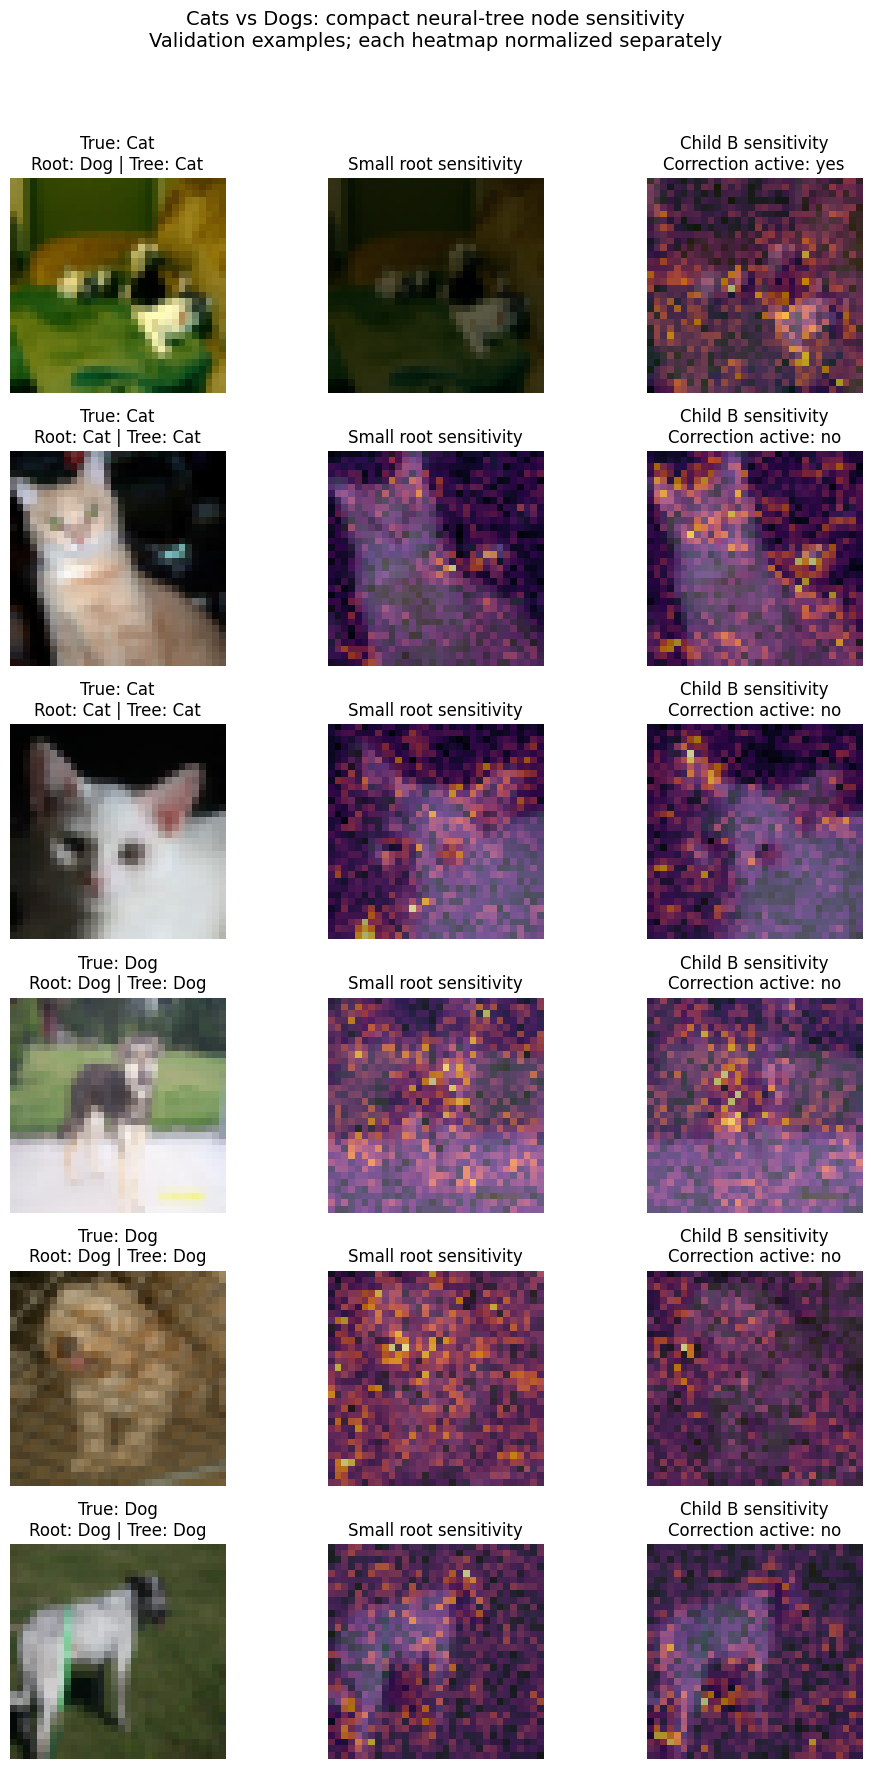

In [58]:
import numpy as np
import matplotlib.pyplot as plt

catsdogs_trunk.eval()
catsdogs_small_root.eval()
catsdogs_small_child_B.eval()


def cd_node_sensitivity(image, node_name):
    image_input = (
        image.unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    features = catsdogs_trunk(image_input)

    normalized = (
        features - catsdogs_feature_mean.to(device)
    ) / catsdogs_feature_std.to(device)

    if node_name == "root":
        score = catsdogs_small_root(normalized).reshape(-1)[0]

    elif node_name == "child":
        # Differentiate the continuous score BEFORE thresholding.
        score = catsdogs_small_child_B(normalized).reshape(-1)[0]

    else:
        raise ValueError("Choose 'root' or 'child'.")

    gradient = torch.autograd.grad(score, image_input)[0]

    heatmap = (
        gradient.abs()
        .amax(dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )

    heatmap /= max(float(heatmap.max()), 1e-12)
    return heatmap


# First three validation examples from each class.
cd_visual_indices = []

for wanted_label in [0, 1]:
    selected = 0

    for index, (_, label) in enumerate(
        catsdogs_val_dataset.samples
    ):
        if label == wanted_label:
            cd_visual_indices.append(index)
            selected += 1

        if selected == 3:
            break


fig, axes = plt.subplots(
    len(cd_visual_indices), 3,
    figsize=(10, 18),
    squeeze=False
)

for row, index in enumerate(cd_visual_indices):
    image, label = catsdogs_val_dataset[index]
    image_rgb = image.permute(1, 2, 0).cpu().numpy()
    image_rgb = np.clip(image_rgb, 0, 1)

    root_map = cd_node_sensitivity(image, "root")
    child_map = cd_node_sensitivity(image, "child")

    # Display the actual root and tree decisions.
    with torch.no_grad():
        features = catsdogs_trunk(
            image.unsqueeze(0).to(device)
        )
        normalized = (
            features - catsdogs_feature_mean.to(device)
        ) / catsdogs_feature_std.to(device)

        root_score = catsdogs_small_root(normalized).item()
        child_active = int(
            catsdogs_small_child_B(normalized).item() >= 0
        )

        tree_score = (
            root_score - catsdogs_compact_b * child_active
        )

    root_label = "Dog" if root_score >= 0 else "Cat"
    tree_label = "Dog" if tree_score >= 0 else "Cat"

    axes[row, 0].imshow(image_rgb)
    axes[row, 0].set_title(
        f"True: {catsdogs_class_names[label]}\n"
        f"Root: {root_label} | Tree: {tree_label}"
    )

    axes[row, 1].imshow(image_rgb)
    axes[row, 1].imshow(
        root_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 1].set_title("Small root sensitivity")

    axes[row, 2].imshow(image_rgb)
    axes[row, 2].imshow(
        child_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 2].set_title(
        f"Child B sensitivity\n"
        f"Correction active: {'yes' if child_active else 'no'}"
    )

for axis in axes.flat:
    axis.axis("off")

fig.suptitle(
    "Cats vs Dogs: compact neural-tree node sensitivity\n"
    "Validation examples; each heatmap normalized separately",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "catsdogs_compact_node_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "catsdogs_compact_node_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

### Compact-Tree Node Visualization

In the first validation example, the root incorrectly predicts
Dog for a Cat image. The downward child activates, and the
corrected tree predicts Cat. For the remaining five displayed
examples, the child remains inactive and the root's correct
predictions are preserved.

Root and child sensitivity maps differ despite sharing the same
CNN features. Responses overlap animal regions and background
areas; they do not demonstrate consistent object-only localization.

The first root map shows no visible gradient signal. Local
gradient maps can be uninformative in flat regions of a ReLU
network and should not be interpreted as complete explanations.

These six examples illustrate node behavior. Aggregate validation
results show only one fewer error overall, so the successful
example does not establish a broad generalization improvement.

## Final Test Evaluation: Compact Cats vs Dogs Tree

In [59]:
import json

# Load our saved model into separate evaluation objects.
cd_final_checkpoint = torch.load(
    "catsdogs_compact_tree.pt",
    map_location="cpu",
    weights_only=True
)

cd_test_trunk = CNNTrunk().to(device)
cd_test_trunk.load_state_dict(
    cd_final_checkpoint["trunk_state"]
)

cd_test_root = BinaryNode(
    input_dim=2048,
    hidden_width=cd_final_checkpoint["root_hidden_width"]
).to(device)
cd_test_root.load_state_dict(
    cd_final_checkpoint["root_state"]
)

cd_test_child = BinaryNode(
    input_dim=2048,
    hidden_width=cd_final_checkpoint["child_hidden_width"]
).to(device)
cd_test_child.load_state_dict(
    cd_final_checkpoint["child_B_state"]
)

cd_test_trunk.eval()
cd_test_root.eval()
cd_test_child.eval()

cd_test_mean = cd_final_checkpoint["feature_mean"].to(device)
cd_test_std = cd_final_checkpoint["feature_std"].to(device)
cd_test_b = float(cd_final_checkpoint["correction_strength"])

cd_test_loader = DataLoader(
    catsdogs_test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

cd_test_scores = []
cd_test_flags = []
cd_test_labels = []

with torch.no_grad():
    for images, labels in cd_test_loader:
        features = cd_test_trunk(images.to(device))
        normalized = (features - cd_test_mean) / cd_test_std

        cd_test_scores.append(cd_test_root(normalized).cpu())
        cd_test_flags.append(
            (cd_test_child(normalized) >= 0).cpu()
        )
        cd_test_labels.append(labels.cpu())

cd_test_scores = torch.cat(cd_test_scores)
cd_test_flags = torch.cat(cd_test_flags)
cd_test_labels = torch.cat(cd_test_labels).bool()

catsdogs_final_test_results = {}

for name, strength in [
    ("Small root", 0.0),
    ("Compact tree", cd_test_b)
]:
    corrected = (
        cd_test_scores.double()
        - strength * cd_test_flags.double()
    )
    predicted = corrected >= 0

    errors = (predicted != cd_test_labels).sum().item()
    missed_dogs = ((~predicted) & cd_test_labels).sum().item()
    false_dogs = (predicted & (~cd_test_labels)).sum().item()

    dog_recall = (
        (predicted & cd_test_labels).sum().item()
        / cd_test_labels.sum().item()
    )
    cat_recall = (
        ((~predicted) & (~cd_test_labels)).sum().item()
        / (~cd_test_labels).sum().item()
    )

    result = {
        "test_images": len(cd_test_labels),
        "accuracy_percent": 100 * (1 - errors / len(cd_test_labels)),
        "balanced_accuracy_percent": 50 * (dog_recall + cat_recall),
        "errors": errors,
        "missed_dogs": missed_dogs,
        "false_dogs": false_dogs
    }

    catsdogs_final_test_results[name] = result

    print(
        f"TEST | {name}: "
        f"accuracy={result['accuracy_percent']:.4f}% | "
        f"balanced={result['balanced_accuracy_percent']:.4f}% | "
        f"errors={errors} | "
        f"missed dogs={missed_dogs} | false dogs={false_dogs}"
    )

with open("catsdogs_final_test_results.json", "w") as file:
    json.dump(catsdogs_final_test_results, file, indent=2)

print("Saved: catsdogs_final_test_results.json")

TEST | Small root: accuracy=77.2582% | balanced=77.2582% | errors=569 | missed dogs=290 | false dogs=279
TEST | Compact tree: accuracy=77.2582% | balanced=77.2582% | errors=569 | missed dogs=290 | false dogs=279
Saved: catsdogs_final_test_results.json


## Final Test Evaluation: CIFAR-10 Neural Tree

In [60]:
import json

cf_checkpoint = torch.load(
    "cifar10_neural_tree_final.pt",
    map_location="cpu",
    weights_only=True
)

# Separate evaluation objects preserve the notebook's current models.
cf_test_trunk = CNNTrunk().to(device)
cf_test_trunk.load_state_dict(cf_checkpoint["trunk_state"])

cf_test_roots = CIFARRoots(
    cf_checkpoint["feature_mean"],
    cf_checkpoint["feature_std"],
    hidden_width=cf_checkpoint["root_hidden_width"]
).to(device)
cf_test_roots.load_state_dict(cf_checkpoint["roots_state"])

cf_test_child = BinaryNode(
    input_dim=2048,
    hidden_width=cf_checkpoint["child_hidden_width"]
).to(device)
cf_test_child.load_state_dict(
    cf_checkpoint["airplane_child_state"]
)

cf_test_trunk.eval()
cf_test_roots.eval()
cf_test_child.eval()

cf_mean = cf_checkpoint["feature_mean"].to(device)
cf_std = cf_checkpoint["feature_std"].to(device)
cf_airplane = int(cf_checkpoint["airplane_index"])
cf_strength = float(cf_checkpoint["correction_strength"])

cf_test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

cf_scores = []
cf_flags = []
cf_labels = []

with torch.no_grad():
    for images, labels in cf_test_loader:
        features = cf_test_trunk(images.to(device))

        cf_scores.append(cf_test_roots(features).cpu())

        normalized = (features - cf_mean) / cf_std
        cf_flags.append(
            (cf_test_child(normalized) >= 0).cpu()
        )
        cf_labels.append(labels.cpu())

cf_scores = torch.cat(cf_scores)
cf_flags = torch.cat(cf_flags)
cf_labels = torch.cat(cf_labels)

cifar10_final_test_results = {}

for name, strength in [
    ("Original roots", 0.0),
    ("Roots + airplane child", cf_strength)
]:
    corrected = cf_scores.clone()
    corrected[:, cf_airplane] -= strength * cf_flags.float()

    predictions = corrected.argmax(dim=1)
    errors = (predictions != cf_labels).sum().item()

    per_class_accuracy = {}

    for class_index, class_name in enumerate(cf_checkpoint["classes"]):
        mask = cf_labels == class_index
        per_class_accuracy[class_name] = (
            100 * (predictions[mask] == cf_labels[mask])
            .float().mean().item()
        )

    result = {
        "test_images": len(cf_labels),
        "accuracy_percent": 100 * (1 - errors / len(cf_labels)),
        "errors": errors,
        "per_class_accuracy_percent": per_class_accuracy
    }

    cifar10_final_test_results[name] = result

    print(
        f"TEST | {name}: "
        f"accuracy={result['accuracy_percent']:.4f}% | "
        f"errors={errors}"
    )

with open("cifar10_final_test_results.json", "w") as file:
    json.dump(cifar10_final_test_results, file, indent=2)

print("Saved: cifar10_final_test_results.json")

TEST | Original roots: accuracy=72.3900% | errors=2761
TEST | Roots + airplane child: accuracy=72.4000% | errors=2760
Saved: cifar10_final_test_results.json


## Innovation 1: Audit identical images across dataset splits

In [64]:
import hashlib
import csv
from collections import defaultdict
from pathlib import Path
from PIL import Image
from torchvision import transforms

audit_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

image_groups = defaultdict(list)

for split_name, samples in catsdogs_splits.items():
    print(f"Checking {split_name}...", flush=True)

    for path, label in samples:
        with Image.open(path) as image:
            pixels = audit_transform(image.convert("RGB"))

        image_hash = hashlib.sha256(
            pixels.contiguous().numpy().tobytes()
        ).hexdigest()

        image_groups[image_hash].append({
            "split": split_name,
            "label": int(label),
            "path": str(path)
        })

duplicate_groups = [
    records for records in image_groups.values()
    if len(records) > 1
]

cross_split_groups = [
    records for records in duplicate_groups
    if len({record["split"] for record in records}) > 1
]

conflicting_groups = [
    records for records in duplicate_groups
    if len({record["label"] for record in records}) > 1
]

print("\nIdentical-image groups:", len(duplicate_groups))
print("Groups appearing across splits:", len(cross_split_groups))
print("Groups with conflicting labels:", len(conflicting_groups))

audit_path = Path("catsdogs_duplicate_audit.csv")

with audit_path.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow([
        "group_id", "split", "label", "path",
        "cross_split", "conflicting_labels"
    ])

    for group_id, records in enumerate(duplicate_groups):
        cross_split = len({r["split"] for r in records}) > 1
        conflicting = len({r["label"] for r in records}) > 1

        for record in records:
            writer.writerow([
                group_id,
                record["split"],
                record["label"],
                record["path"],
                cross_split,
                conflicting
            ])

print("Saved:", audit_path.resolve())

Checking train...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/PIL/TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Checking validation...
Checking test...

Identical-image groups: 28
Groups appearing across splits: 10
Groups with conflicting labels: 2
Saved: /Users/aroma/catsdogs_duplicate_audit.csv


In [65]:
from collections import Counter

overlap_counts = Counter(
    tuple(sorted({record["split"] for record in records}))
    for records in cross_split_groups
)

print("Cross-split duplicate groups:")
for splits, count in sorted(overlap_counts.items()):
    print(" + ".join(splits), ":", count)

print("\nConflicting-label groups:")
for group_number, records in enumerate(conflicting_groups, start=1):
    print(f"\nGroup {group_number}")
    for record in records:
        print(
            record["split"],
            "Cat" if record["label"] == 0 else "Dog",
            record["path"]
        )

Cross-split duplicate groups:
test + train : 6
train + validation : 4

Conflicting-label groups:

Group 1
train Cat /Users/aroma/data/cats_vs_dogs/PetImages/Cat/8456.jpg
train Dog /Users/aroma/data/cats_vs_dogs/PetImages/Dog/8736.jpg

Group 2
train Cat /Users/aroma/data/cats_vs_dogs/PetImages/Cat/11565.jpg
train Dog /Users/aroma/data/cats_vs_dogs/PetImages/Dog/2877.jpg
train Dog /Users/aroma/data/cats_vs_dogs/PetImages/Dog/10797.jpg
train Dog /Users/aroma/data/cats_vs_dogs/PetImages/Dog/10401.jpg


In [66]:
# Keep the original splits unchanged.
# Exclude evaluation inputs that also occur in training.

overlap_paths = {
    record["path"]
    for records in cross_split_groups
    if any(r["split"] == "train" for r in records)
    for record in records
    if record["split"] != "train"
}

catsdogs_clean_splits = {
    "train": list(catsdogs_splits["train"]),
    "validation": [
        (path, label)
        for path, label in catsdogs_splits["validation"]
        if str(path) not in overlap_paths
    ],
    "test": [
        (path, label)
        for path, label in catsdogs_splits["test"]
        if str(path) not in overlap_paths
    ]
}

# Verify that no audited identical-input group crosses clean splits.
clean_path_sets = {
    split: {str(path) for path, _ in samples}
    for split, samples in catsdogs_clean_splits.items()
}

for records in image_groups.values():
    surviving_splits = {
        r["split"]
        for r in records
        if r["path"] in clean_path_sets[r["split"]]
    }
    assert len(surviving_splits) <= 1, (
        "An identical-input group still crosses splits."
    )

for split, samples in catsdogs_clean_splits.items():
    removed = len(catsdogs_splits[split]) - len(samples)
    cats = sum(label == 0 for _, label in samples)
    dogs = sum(label == 1 for _, label in samples)

    print(
        f"{split.upper()}: {len(samples)} images "
        f"| cats={cats} | dogs={dogs} | excluded={removed}"
    )

clean_manifest = Path("catsdogs_clean_split_manifest.csv")

with clean_manifest.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["relative_path", "label", "split"])

    for split, samples in catsdogs_clean_splits.items():
        for path, label in samples:
            writer.writerow([
                str(Path(path).relative_to(catsdogs_images)),
                label,
                split
            ])

print("\nVerified: no identical audited inputs cross splits.")
print("Saved:", clean_manifest.resolve())

TRAIN: 19998 images | cats=9999 | dogs=9999 | excluded=0
VALIDATION: 2494 images | cats=1246 | dogs=1248 | excluded=4
TEST: 2496 images | cats=1245 | dogs=1251 | excluded=6

Verified: no identical audited inputs cross splits.
Saved: /Users/aroma/catsdogs_clean_split_manifest.csv


In [67]:
catsdogs_clean_val_dataset = CatsDogsDataset(
    catsdogs_clean_splits["validation"],
    catsdogs_transform
)

catsdogs_clean_test_dataset = CatsDogsDataset(
    catsdogs_clean_splits["test"],
    catsdogs_transform
)

catsdogs_clean_val_loader = DataLoader(
    catsdogs_clean_val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

catsdogs_clean_test_loader = DataLoader(
    catsdogs_clean_test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(catsdogs_train_dataset))
print("Revised validation images:", len(catsdogs_clean_val_dataset))
print("Revised test images:", len(catsdogs_clean_test_dataset))

Training images: 19998
Revised validation images: 2494
Revised test images: 2496


In [68]:
names_to_check = [
    "catsdogs_trunk",
    "catsdogs_root",
    "catsdogs_X_train",
    "catsdogs_y_train",
    "catsdogs_X_val",
    "catsdogs_Z_train",
    "catsdogs_feature_mean",
    "catsdogs_feature_std"
]

for name in names_to_check:
    value = globals().get(name)

    if value is None:
        print(name, "→ not found")
    elif isinstance(value, torch.Tensor):
        print(name, "→", tuple(value.shape))
    else:
        print(name, "→", type(value).__name__)

catsdogs_trunk → CNNTrunk
catsdogs_root → BinaryNode
catsdogs_X_train → (19998, 2048)
catsdogs_y_train → (19998,)
catsdogs_X_val → (2498, 2048)
catsdogs_Z_train → (19998, 2048)
catsdogs_feature_mean → (2048,)
catsdogs_feature_std → (2048,)


In [69]:
catsdogs_trunk.eval()

clean_features = []
clean_labels = []

with torch.no_grad():
    for images, labels in catsdogs_clean_val_loader:
        features = catsdogs_trunk(images.to(device))

        clean_features.append(features.cpu())
        clean_labels.append(labels.cpu())

catsdogs_clean_X_val = torch.cat(clean_features)
catsdogs_clean_y_val = torch.cat(clean_labels)

# Use only the existing TRAINING mean and standard deviation.
catsdogs_clean_Z_val = (
    catsdogs_clean_X_val - catsdogs_feature_mean.cpu()
) / catsdogs_feature_std.cpu()

assert catsdogs_clean_X_val.shape == (2494, 2048)
assert torch.isfinite(catsdogs_clean_Z_val).all()

print("Training features:", catsdogs_Z_train.shape)
print("Revised validation features:", catsdogs_clean_Z_val.shape)
print("Revised validation labels:", catsdogs_clean_y_val.shape)

torch.save({
    "X_validation": catsdogs_clean_X_val,
    "Z_validation": catsdogs_clean_Z_val,
    "y_validation": catsdogs_clean_y_val,
    "feature_mean": catsdogs_feature_mean.cpu(),
    "feature_std": catsdogs_feature_std.cpu()
}, "catsdogs_clean_validation_features.pt")

print("Saved: catsdogs_clean_validation_features.pt")

Training features: torch.Size([19998, 2048])
Revised validation features: torch.Size([2494, 2048])
Revised validation labels: torch.Size([2494])
Saved: catsdogs_clean_validation_features.pt


In [70]:
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Separate experiment variables.
innovation_X_train = catsdogs_Z_train.detach().cpu().float()
innovation_y_train = catsdogs_y_train.detach().cpu().float()

innovation_X_val = catsdogs_clean_Z_val.detach().cpu().float()
innovation_y_val = catsdogs_clean_y_val.detach().cpu().float()


class InnovationNode(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2048, width),
            nn.ReLU(),
            nn.Linear(width, 1)
        )

    def forward(self, features):
        return self.layers(features).squeeze(-1)


@torch.no_grad()
def innovation_evaluate(network, features, labels):
    network.eval()

    scores = torch.cat([
        network(batch.to(device)).cpu()
        for batch in features.split(512)
    ])

    predicted = scores >= 0
    actual = labels.bool()

    missed = ((~predicted) & actual).sum().item()
    false = (predicted & (~actual)).sum().item()
    errors = missed + false

    return {
        "accuracy": 100 * (1 - errors / len(labels)),
        "errors": errors,
        "missed_dogs": missed,
        "false_dogs": false
    }


innovation_roots = {}
innovation_histories = {}

for width in [16, 8]:
    # Same seed and batch order for each run.
    torch.manual_seed(42)

    network = InnovationNode(width).to(device)
    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)
    criterion = nn.BCEWithLogitsLoss()

    loader = DataLoader(
        TensorDataset(innovation_X_train, innovation_y_train),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    history = []
    start = time.perf_counter()

    print(f"\nTRAINING ROOT WIDTH {width}", flush=True)

    for epoch in range(1, 101):
        if epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()

        for features, targets in loader:
            features = features.to(device)
            targets = targets.to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(network(features), targets)
            loss.backward()
            optimizer.step()

        if epoch % 20 == 0:
            train_result = innovation_evaluate(
                network, innovation_X_train, innovation_y_train
            )
            val_result = innovation_evaluate(
                network, innovation_X_val, innovation_y_val
            )

            history.append({
                "epoch": epoch,
                "train": train_result,
                "validation": val_result
            })

            print(
                f"Epoch {epoch}: "
                f"train={train_result['accuracy']:.4f}% "
                f"| errors={train_result['errors']} "
                f"| missed dogs={train_result['missed_dogs']} "
                f"| false dogs={train_result['false_dogs']} "
                f"| validation={val_result['accuracy']:.2f}%",
                flush=True
            )

    innovation_roots[width] = network
    innovation_histories[width] = history

    torch.save({
        "root_state": {
            key: value.detach().cpu()
            for key, value in network.state_dict().items()
        },
        "width": width,
        "seed": 42,
        "epochs": 100,
        "feature_mean": catsdogs_feature_mean.cpu(),
        "feature_std": catsdogs_feature_std.cpu(),
        "history": history
    }, f"catsdogs_innovation_root_width{width}_seed42.pt")

    print(
        f"Saved width {width} | "
        f"time={time.perf_counter() - start:.1f}s",
        flush=True
    )


TRAINING ROOT WIDTH 16
Epoch 20: train=99.7000% | errors=60 | missed dogs=45 | false dogs=15 | validation=78.79%
Epoch 40: train=99.9500% | errors=10 | missed dogs=0 | false dogs=10 | validation=78.07%
Epoch 60: train=99.9750% | errors=5 | missed dogs=4 | false dogs=1 | validation=78.43%
Epoch 80: train=99.9750% | errors=5 | missed dogs=4 | false dogs=1 | validation=78.27%
Epoch 100: train=99.9800% | errors=4 | missed dogs=2 | false dogs=2 | validation=78.47%
Saved width 16 | time=10.8s

TRAINING ROOT WIDTH 8
Epoch 20: train=97.1197% | errors=576 | missed dogs=326 | false dogs=250 | validation=79.15%
Epoch 40: train=99.5950% | errors=81 | missed dogs=10 | false dogs=71 | validation=78.83%
Epoch 60: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.35%
Epoch 80: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.51%
Epoch 100: train=99.7400% | errors=52 | missed dogs=0 | false dogs=52 | validation=78.55%
Saved width 8 | time=9.4s


In [71]:
parent = innovation_roots[8]
parent.eval()

with torch.no_grad():
    parent_train_scores = torch.cat([
        parent(batch.to(device)).cpu()
        for batch in innovation_X_train.split(512)
    ])

actual_dog = innovation_y_train.bool()
predicted_dog = parent_train_scores >= 0

false_dog = predicted_dog & (~actual_dog)
missed_dog = (~predicted_dog) & actual_dog

print("Missed dogs:", missed_dog.sum().item())
print("False dog predictions:", false_dog.sum().item())

assert false_dog.any(), "No false positives: child B is unnecessary."

# Protect all genuine dogs; correct false dog predictions.
child_B_mask = actual_dog | false_dog
child_B_X = innovation_X_train[child_B_mask]
child_B_y = false_dog[child_B_mask].float()

positive_count = child_B_y.sum()
negative_count = len(child_B_y) - positive_count

torch.manual_seed(42)
innovation_child_B = InnovationNode(width=8).to(device)

child_loader = DataLoader(
    TensorDataset(child_B_X, child_B_y),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

child_loss = nn.BCEWithLogitsLoss(
    pos_weight=(negative_count / positive_count).to(device)
)

child_optimizer = torch.optim.Adam(
    innovation_child_B.parameters(), lr=0.001
)

best_child_state = None
best_child_key = None
best_child_epoch = None

for epoch in range(1, 101):
    innovation_child_B.train()

    for features, targets in child_loader:
        features = features.to(device)
        targets = targets.to(device)

        child_optimizer.zero_grad(set_to_none=True)
        loss = child_loss(innovation_child_B(features), targets)
        loss.backward()
        child_optimizer.step()

    # Select the checkpoint using the assigned training task only.
    result = innovation_evaluate(
        innovation_child_B, child_B_X, child_B_y
    )

    missed_corrections = result["missed_dogs"]
    unwanted_corrections = result["false_dogs"]

    # Balanced error prevents the rare correction class being ignored.
    balanced_error = (
        missed_corrections / positive_count.item()
        + unwanted_corrections / negative_count.item()
    ) / 2

    checkpoint_key = (balanced_error, result["errors"])

    if best_child_key is None or checkpoint_key < best_child_key:
        best_child_key = checkpoint_key
        best_child_epoch = epoch
        best_child_state = {
            key: value.detach().cpu().clone()
            for key, value in innovation_child_B.state_dict().items()
        }

    if epoch % 20 == 0:
        print(
            f"Epoch {epoch}: "
            f"missed corrections={missed_corrections} "
            f"| dogs flagged for unwanted correction="
            f"{unwanted_corrections}",
            flush=True
        )

innovation_child_B.load_state_dict(best_child_state)
innovation_child_B.eval()

torch.save({
    "child_state": best_child_state,
    "width": 8,
    "seed": 42,
    "selected_epoch": best_child_epoch,
    "task": "Suppress false dog predictions"
}, "catsdogs_innovation_childB_seed42.pt")

print("Restored child epoch:", best_child_epoch)
print("Saved: catsdogs_innovation_childB_seed42.pt")

Missed dogs: 0
False dog predictions: 52
Epoch 20: missed corrections=0 | dogs flagged for unwanted correction=13
Epoch 40: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 60: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 80: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 100: missed corrections=0 | dogs flagged for unwanted correction=4
Restored child epoch: 27
Saved: catsdogs_innovation_childB_seed42.pt


In [72]:
import json

@torch.no_grad()
def innovation_scores(network, features):
    network.eval()
    return torch.cat([
        network(batch.to(device)).cpu()
        for batch in features.split(512)
    ]).double()


def innovation_score_metrics(scores, labels):
    actual = labels.cpu().bool()
    predicted = scores >= 0

    missed = ((~predicted) & actual).sum().item()
    false = (predicted & (~actual)).sum().item()
    errors = missed + false

    dog_recall = (predicted & actual).sum().item() / actual.sum().item()
    cat_recall = ((~predicted) & (~actual)).sum().item() / (
        (~actual).sum().item()
    )

    return {
        "accuracy": 100 * (1 - errors / len(actual)),
        "balanced_accuracy": 50 * (dog_recall + cat_recall),
        "errors": errors,
        "missed_dogs": missed,
        "false_dogs": false
    }


root8_train_scores = innovation_scores(
    innovation_roots[8], innovation_X_train
)
child_train_flags = innovation_scores(
    innovation_child_B, innovation_X_train
) >= 0

# Only flagged inputs with nonnegative parent scores can change
# prediction when a nonnegative correction is subtracted.
breakpoints = torch.unique(
    root8_train_scores[
        child_train_flags & (root8_train_scores >= 0)
    ]
).sort().values

# Check each distinct prediction regime, including b = 0.
candidates = [0.0]

if len(breakpoints):
    candidates.extend(breakpoints.tolist())
    candidates.extend(
        ((breakpoints[:-1] + breakpoints[1:]) / 2).tolist()
    )
    candidates.append(
        breakpoints[-1].item()
        + max(1.0, abs(breakpoints[-1].item()) * 0.01)
    )

best_key = None
innovation_b = None

for strength in sorted(set(candidates)):
    corrected = (
        root8_train_scores
        - strength * child_train_flags.double()
    )
    result = innovation_score_metrics(
        corrected, innovation_y_train
    )

    # Minimize training errors; use the smaller strength for ties.
    key = (result["errors"], strength)

    if best_key is None or key < best_key:
        best_key = key
        innovation_b = strength

print(f"Selected correction strength: {innovation_b:.8f}")

innovation_comparison = {}

for split, features, labels in [
    ("TRAIN", innovation_X_train, innovation_y_train),
    ("VALIDATION", innovation_X_val, innovation_y_val)
]:
    root8_scores = innovation_scores(innovation_roots[8], features)
    root16_scores = innovation_scores(innovation_roots[16], features)
    flags = innovation_scores(innovation_child_B, features) >= 0

    tree_scores = root8_scores - innovation_b * flags.double()

    results = {
        "root_width8": innovation_score_metrics(root8_scores, labels),
        "root_width16": innovation_score_metrics(root16_scores, labels),
        "adaptive_tree": innovation_score_metrics(tree_scores, labels)
    }
    innovation_comparison[split.lower()] = results

    print(f"\n{split}")
    for name, result in results.items():
        print(
            f"{name}: accuracy={result['accuracy']:.4f}% "
            f"| balanced={result['balanced_accuracy']:.4f}% "
            f"| errors={result['errors']} "
            f"| missed dogs={result['missed_dogs']} "
            f"| false dogs={result['false_dogs']}"
        )

with open("catsdogs_innovation_comparison_seed42.json", "w") as file:
    json.dump({
        "seed": 42,
        "correction_strength": innovation_b,
        "correction_rule": "root_score - b * (child_score >= 0)",
        "results": innovation_comparison
    }, file, indent=2)

print("\nSaved: catsdogs_innovation_comparison_seed42.json")

Selected correction strength: 1.97952795

TRAIN
root_width8: accuracy=99.7400% | balanced=99.7400% | errors=52 | missed dogs=0 | false dogs=52
root_width16: accuracy=99.9800% | balanced=99.9800% | errors=4 | missed dogs=2 | false dogs=2
adaptive_tree: accuracy=99.9800% | balanced=99.9800% | errors=4 | missed dogs=4 | false dogs=0

VALIDATION
root_width8: accuracy=78.5485% | balanced=78.5496% | errors=535 | missed dogs=285 | false dogs=250
root_width16: accuracy=78.4683% | balanced=78.4684% | errors=537 | missed dogs=270 | false dogs=267
adaptive_tree: accuracy=78.5485% | balanced=78.5496% | errors=535 | missed dogs=285 | false dogs=250

Saved: catsdogs_innovation_comparison_seed42.json


In [73]:
import copy
import json
import time

def fit_innovation_node(features, targets, width, seed, weighted=False):
    torch.manual_seed(seed)
    network = InnovationNode(width).to(device)

    loader = DataLoader(
        TensorDataset(features, targets),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed)
    )

    if weighted:
        positives = targets.sum().item()
        negatives = len(targets) - positives
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(negatives / positives, device=device)
        )
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)
    best_key, best_state = None, None

    for epoch in range(1, 101):
        # Match our earlier root and child training schedules.
        if not weighted and epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()
        for batch, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(
                network(batch.to(device)), labels.to(device)
            )
            loss.backward()
            optimizer.step()

        if weighted:
            result = innovation_evaluate(network, features, targets)
            key = (
                result["missed_dogs"] / positives
                + result["false_dogs"] / negatives
            ) / 2

            if best_key is None or key < best_key:
                best_key = key
                best_state = copy.deepcopy(network.state_dict())

    if weighted:
        network.load_state_dict(best_state)

    network.eval()
    return network


def select_strength(base_scores, flags, direction, labels):
    # Predictions can change only at nonnegative strength breakpoints.
    thresholds = -base_scores[flags] / direction
    thresholds = torch.unique(
        thresholds[thresholds >= 0]
    ).sort().values

    candidates = [0.0]
    if len(thresholds):
        candidates += thresholds.tolist()
        candidates += (
            (thresholds[:-1] + thresholds[1:]) / 2
        ).tolist()
        candidates.append(
            thresholds[-1].item()
            + max(1.0, abs(thresholds[-1].item()) * 0.01)
        )

    best_key, best_strength = None, 0.0
    for strength in sorted(set(candidates)):
        scores = base_scores + direction * strength * flags.double()
        result = innovation_score_metrics(scores, labels)
        key = (result["errors"], strength)

        if best_key is None or key < best_key:
            best_key, best_strength = key, strength

    return best_strength


repeated_results = []

for seed in [43, 44]:
    start = time.perf_counter()
    print(f"\nSEED {seed}: training roots...", flush=True)

    roots = {
        width: fit_innovation_node(
            innovation_X_train, innovation_y_train, width, seed
        )
        for width in [8, 16]
    }

    root_train_scores = innovation_scores(roots[8], innovation_X_train)
    actual = innovation_y_train.bool()
    predicted = root_train_scores >= 0

    missed = (~predicted) & actual
    false = predicted & (~actual)

    active = []
    if missed.any():
        active.append("A")
    if false.any():
        active.append("B")

    child_width = 8 // len(active) if active else 0
    children, strengths = {}, {}

    print(
        f"Root errors: missed dogs={missed.sum().item()}, "
        f"false dogs={false.sum().item()} | "
        f"children={active} | width per child={child_width}",
        flush=True
    )

    # Assign child tasks from the original root's mistakes.
    for name in active:
        error_mask = missed if name == "A" else false
        protected = (~actual) if name == "A" else actual
        task_mask = error_mask | protected

        children[name] = fit_innovation_node(
            innovation_X_train[task_mask],
            error_mask[task_mask].float(),
            child_width,
            seed + (100 if name == "A" else 200),
            weighted=True
        )

    train_flags = {
        name: innovation_scores(child, innovation_X_train) >= 0
        for name, child in children.items()
    }

    # Training-only coordinate search when both children exist.
    strengths = {name: 0.0 for name in active}
    directions = {"A": 1, "B": -1}

    for _ in range(5):
        previous = strengths.copy()
        for name in active:
            base = root_train_scores.clone()
            for other in active:
                if other != name:
                    base += (
                        directions[other] * strengths[other]
                        * train_flags[other].double()
                    )

            strengths[name] = select_strength(
                base, train_flags[name], directions[name],
                innovation_y_train
            )

        if strengths == previous:
            break

    trunk_params = sum(p.numel() for p in catsdogs_trunk.parameters())
    tree_params = (
        trunk_params
        + sum(p.numel() for p in roots[8].parameters())
        + sum(
            p.numel()
            for child in children.values()
            for p in child.parameters()
        )
        + len(active)
    )

    record = {
        "seed": seed,
        "children": active,
        "child_width": child_width,
        "strengths": strengths,
        "tree_parameters": tree_params,
        "root16_parameters": (
            trunk_params + sum(p.numel() for p in roots[16].parameters())
        )
    }

    for split, features, labels in [
        ("train", innovation_X_train, innovation_y_train),
        ("validation", innovation_X_val, innovation_y_val)
    ]:
        parent_scores = innovation_scores(roots[8], features)
        tree_scores = parent_scores.clone()

        for name, child in children.items():
            flags = innovation_scores(child, features) >= 0
            tree_scores += (
                directions[name] * strengths[name] * flags.double()
            )

        record[split] = {
            "root8": innovation_score_metrics(parent_scores, labels),
            "root16": innovation_score_metrics(
                innovation_scores(roots[16], features), labels
            ),
            "tree": innovation_score_metrics(tree_scores, labels),
            "tree_changed_predictions": (
                (tree_scores >= 0) != (parent_scores >= 0)
            ).sum().item()
        }

        print(f"\n{split.upper()}", flush=True)
        for name in ["root8", "root16", "tree"]:
            result = record[split][name]
            print(
                f"{name}: accuracy={result['accuracy']:.4f}% "
                f"| errors={result['errors']} "
                f"| missed={result['missed_dogs']} "
                f"| false={result['false_dogs']}",
                flush=True
            )

        print(
            "Tree changed predictions:",
            record[split]["tree_changed_predictions"],
            flush=True
        )

    record["seconds"] = time.perf_counter() - start
    repeated_results.append(record)

    torch.save({
        "seed": seed,
        "root8_state": roots[8].state_dict(),
        "root16_state": roots[16].state_dict(),
        "child_states": {
            name: child.state_dict()
            for name, child in children.items()
        },
        "child_width": child_width,
        "strengths": strengths,
        "feature_mean": catsdogs_feature_mean.cpu(),
        "feature_std": catsdogs_feature_std.cpu(),
        "results": record
    }, f"catsdogs_adaptive_comparison_seed{seed}.pt")

    # Save progress after each completed seed.
    with open("catsdogs_adaptive_repeated_results.json", "w") as file:
        json.dump(repeated_results, file, indent=2)

    print(
        f"\nSaved seed {seed} | "
        f"tree parameters={tree_params:,} | "
        f"time={record['seconds']:.1f}s",
        flush=True
    )


SEED 43: training roots...
Root errors: missed dogs=30, false dogs=1 | children=['A', 'B'] | width per child=4

TRAIN
root8: accuracy=99.8450% | errors=31 | missed=30 | false=1
root16: accuracy=99.9700% | errors=6 | missed=0 | false=6
tree: accuracy=99.9850% | errors=3 | missed=0 | false=3
Tree changed predictions: 32

VALIDATION
root8: accuracy=77.9872% | errors=549 | missed=282 | false=267
root16: accuracy=79.1099% | errors=521 | missed=286 | false=235
tree: accuracy=77.9471% | errors=550 | missed=282 | false=268
Tree changed predictions: 1

Saved seed 43 | tree parameters=37,893 | time=33.0s

SEED 44: training roots...
Root errors: missed dogs=57, false dogs=2 | children=['A', 'B'] | width per child=4

TRAIN
root8: accuracy=99.7050% | errors=59 | missed=57 | false=2
root16: accuracy=99.9700% | errors=6 | missed=4 | false=2
tree: accuracy=99.9850% | errors=3 | missed=1 | false=2
Tree changed predictions: 58

VALIDATION
root8: accuracy=77.3857% | errors=564 | missed=297 | false=267
r

In [74]:
for name in [
    "X_train", "y_train", "X_val", "y_val",
    "feature_mean", "feature_std", "cifar_roots"
]:
    value = globals().get(name)

    if value is None:
        print(name, "→ not found")
    elif isinstance(value, torch.Tensor):
        print(name, "→", tuple(value.shape))
    else:
        print(name, "→", type(value).__name__)

X_train → (45000, 2048)
y_train → (45000,)
X_val → (5000, 2048)
y_val → (5000,)
feature_mean → (2048,)
feature_std → (2048,)
cifar_roots → CIFARRoots


In [75]:
# Standardize using CIFAR training statistics only.
cifar_innovation_X_train = (
    (X_train.detach().cpu() - feature_mean.detach().cpu())
    / feature_std.detach().cpu()
).float()

cifar_innovation_X_val = (
    (X_val.detach().cpu() - feature_mean.detach().cpu())
    / feature_std.detach().cpu()
).float()

cifar_innovation_y_train = y_train.detach().cpu().long()
cifar_innovation_y_val = y_val.detach().cpu().long()

assert torch.isfinite(cifar_innovation_X_train).all()
assert torch.isfinite(cifar_innovation_X_val).all()


class InnovationCIFARRoots(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.nodes = nn.ModuleList([
            InnovationNode(width) for _ in range(10)
        ])

    def forward(self, features):
        return torch.stack(
            [node(features) for node in self.nodes], dim=1
        )


@torch.no_grad()
def cifar_innovation_scores(network, features):
    network.eval()
    return torch.cat([
        network(batch.to(device)).cpu()
        for batch in features.split(512)
    ])


def cifar_innovation_metrics(scores, labels):
    predicted = scores.argmax(dim=1)
    errors = (predicted != labels).sum().item()

    return {
        "accuracy": 100 * (1 - errors / len(labels)),
        "errors": errors
    }


cifar_innovation_roots = {}
cifar_innovation_histories = {}

one_hot_targets = torch.nn.functional.one_hot(
    cifar_innovation_y_train, num_classes=10
).float()

positive_counts = one_hot_targets.sum(dim=0)
pos_weight = (
    (len(one_hot_targets) - positive_counts) / positive_counts
).to(device)

for width in [16, 8]:
    torch.manual_seed(42)
    network = InnovationCIFARRoots(width).to(device)

    optimizer = torch.optim.Adam(
        network.parameters(), lr=0.001
    )
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    loader = DataLoader(
        TensorDataset(cifar_innovation_X_train, one_hot_targets),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    history = []
    start = time.perf_counter()

    print(f"\nCIFAR ROOT WIDTH {width}", flush=True)

    for epoch in range(1, 101):
        if epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()

        for features, targets in loader:
            optimizer.zero_grad(set_to_none=True)

            loss = criterion(
                network(features.to(device)),
                targets.to(device)
            )
            loss.backward()
            optimizer.step()

        if epoch % 20 == 0:
            train_result = cifar_innovation_metrics(
                cifar_innovation_scores(
                    network, cifar_innovation_X_train
                ),
                cifar_innovation_y_train
            )
            val_result = cifar_innovation_metrics(
                cifar_innovation_scores(
                    network, cifar_innovation_X_val
                ),
                cifar_innovation_y_val
            )

            history.append({
                "epoch": epoch,
                "train": train_result,
                "validation": val_result
            })

            print(
                f"Epoch {epoch}: "
                f"train={train_result['accuracy']:.4f}% "
                f"| errors={train_result['errors']} "
                f"| validation={val_result['accuracy']:.2f}%",
                flush=True
            )

    cifar_innovation_roots[width] = network
    cifar_innovation_histories[width] = history

    torch.save({
        "root_state": {
            key: value.detach().cpu()
            for key, value in network.state_dict().items()
        },
        "width": width,
        "seed": 42,
        "epochs": 100,
        "feature_mean": feature_mean.detach().cpu(),
        "feature_std": feature_std.detach().cpu(),
        "history": history
    }, f"cifar_innovation_roots_width{width}_seed42.pt")

    print(
        f"Saved width {width} | "
        f"time={time.perf_counter() - start:.1f}s",
        flush=True
    )


CIFAR ROOT WIDTH 16
Epoch 20: train=97.1111% | errors=1300 | validation=67.06%
Epoch 40: train=99.5444% | errors=205 | validation=66.48%
Epoch 60: train=99.9800% | errors=9 | validation=66.98%
Epoch 80: train=99.9867% | errors=6 | validation=66.90%
Epoch 100: train=99.9978% | errors=1 | validation=66.78%
Saved width 16 | time=136.9s

CIFAR ROOT WIDTH 8
Epoch 20: train=90.9800% | errors=4059 | validation=65.52%
Epoch 40: train=96.8867% | errors=1401 | validation=63.98%
Epoch 60: train=99.0089% | errors=446 | validation=63.22%
Epoch 80: train=99.2533% | errors=336 | validation=63.00%
Epoch 100: train=99.4689% | errors=239 | validation=62.94%
Saved width 8 | time=107.7s


In [76]:
cifar_parent_train_scores = cifar_innovation_scores(
    cifar_innovation_roots[8],
    cifar_innovation_X_train
)

cifar_class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

cifar_child_tasks = {}

for class_index, class_name in enumerate(cifar_class_names):
    actual = cifar_innovation_y_train == class_index

    # Binary decision of this one-vs-rest root.
    predicted_positive = (
        cifar_parent_train_scores[:, class_index] >= 0
    )

    missed = (~predicted_positive) & actual
    false = predicted_positive & (~actual)

    active = []
    if missed.any():
        active.append("A")
    if false.any():
        active.append("B")

    # Maximum eight child hidden units per class.
    child_width = 8 // len(active) if active else 0

    cifar_child_tasks[class_index] = {
        "actual": actual,
        "missed": missed,
        "false": false,
        "active": active,
        "child_width": child_width
    }

    print(
        f"{class_name:10s}: "
        f"missed positives={missed.sum().item():4d} "
        f"| false positives={false.sum().item():4d} "
        f"| children={active} "
        f"| width each={child_width}"
    )

print(
    "\nTen-class training errors:",
    cifar_innovation_metrics(
        cifar_parent_train_scores,
        cifar_innovation_y_train
    )["errors"]
)

airplane  : missed positives=  30 | false positives= 171 | children=['A', 'B'] | width each=4
automobile: missed positives=  11 | false positives=   0 | children=['A'] | width each=8
bird      : missed positives=  12 | false positives= 627 | children=['A', 'B'] | width each=4
cat       : missed positives=  34 | false positives= 596 | children=['A', 'B'] | width each=4
deer      : missed positives=   4 | false positives= 460 | children=['A', 'B'] | width each=4
dog       : missed positives=  11 | false positives= 340 | children=['A', 'B'] | width each=4
frog      : missed positives=  15 | false positives=  45 | children=['A', 'B'] | width each=4
horse     : missed positives=  14 | false positives=  11 | children=['A', 'B'] | width each=4
ship      : missed positives=   5 | false positives=  14 | children=['A', 'B'] | width each=4
truck     : missed positives=  16 | false positives=   1 | children=['A', 'B'] | width each=4

Ten-class training errors: 239


In [77]:
cifar_innovation_children = {}
cifar_child_training_results = []

start = time.perf_counter()

for class_index, task in cifar_child_tasks.items():
    class_name = cifar_class_names[class_index]
    actual = task["actual"]

    for child_name in task["active"]:
        error_mask = (
            task["missed"] if child_name == "A"
            else task["false"]
        )

        # A protects non-class images while recovering missed positives.
        # B protects class images while suppressing false positives.
        protected = (~actual) if child_name == "A" else actual
        task_mask = error_mask | protected

        features = cifar_innovation_X_train[task_mask]
        targets = error_mask[task_mask].float()

        print(
            f"\n{class_name}: child {child_name} "
            f"| width={task['child_width']} "
            f"| corrections={int(targets.sum().item())} "
            f"| task images={len(targets)}",
            flush=True
        )

        child = fit_innovation_node(
            features,
            targets,
            width=task["child_width"],
            seed=42 + 100 * (class_index + 1)
                 + (0 if child_name == "A" else 1),
            weighted=True
        )

        result = innovation_evaluate(child, features, targets)

        key = (class_index, child_name)
        cifar_innovation_children[key] = child

        cifar_child_training_results.append({
            "class_index": class_index,
            "class_name": class_name,
            "child": child_name,
            "width": task["child_width"],
            "missed_corrections": result["missed_dogs"],
            "unwanted_corrections": result["false_dogs"]
        })

        print(
            f"Missed corrections={result['missed_dogs']} "
            f"| unwanted corrections={result['false_dogs']}",
            flush=True
        )

        # Save each child immediately.
        torch.save({
            "state": {
                name: value.detach().cpu()
                for name, value in child.state_dict().items()
            },
            "class_index": class_index,
            "child": child_name,
            "width": task["child_width"],
            "result": cifar_child_training_results[-1]
        }, f"cifar_innovation_class{class_index}_child{child_name}.pt")

with open("cifar_innovation_child_training.json", "w") as file:
    json.dump(cifar_child_training_results, file, indent=2)

print(
    f"\nFinished {len(cifar_innovation_children)} children "
    f"in {time.perf_counter() - start:.1f}s",
    flush=True
)


airplane: child A | width=4 | corrections=30 | task images=40518
Missed corrections=0 | unwanted corrections=29

airplane: child B | width=4 | corrections=171 | task images=4683
Missed corrections=0 | unwanted corrections=40

automobile: child A | width=8 | corrections=11 | task images=40523
Missed corrections=0 | unwanted corrections=1

bird: child A | width=4 | corrections=12 | task images=40544
Missed corrections=0 | unwanted corrections=4

bird: child B | width=4 | corrections=627 | task images=5095
Missed corrections=23 | unwanted corrections=71

cat: child A | width=4 | corrections=34 | task images=40505
Missed corrections=0 | unwanted corrections=8

cat: child B | width=4 | corrections=596 | task images=5125
Missed corrections=11 | unwanted corrections=132

deer: child A | width=4 | corrections=4 | task images=40475
Missed corrections=0 | unwanted corrections=55

deer: child B | width=4 | corrections=460 | task images=4989
Missed corrections=7 | unwanted corrections=37

dog: ch

In [78]:
# Use float64 on CPU for consistent correction arithmetic.
cifar_base_train = cifar_parent_train_scores.double()
cifar_base_val = cifar_innovation_scores(
    cifar_innovation_roots[8], cifar_innovation_X_val
).double()

cifar_train_flags = {}
cifar_val_flags = {}

for key, child in cifar_innovation_children.items():
    cifar_train_flags[key] = (
        innovation_scores(child, cifar_innovation_X_train) >= 0
    )
    cifar_val_flags[key] = (
        innovation_scores(child, cifar_innovation_X_val) >= 0
    )


def choose_multiclass_strength(base, flags, class_index, direction, labels):
    """Search intervals between prediction-change thresholds."""
    initial_prediction = base.argmax(dim=1)
    initial_errors = (initial_prediction != labels).sum().item()

    # Best competing class, using the usual first-index tie convention.
    competitors = base.clone()
    competitors[:, class_index] = -torch.inf
    other_score, other_class = competitors.max(dim=1)

    thresholds = (
        other_score - base[:, class_index]
    ) / direction

    affected = flags & (thresholds >= 0)

    if not affected.any():
        return 0.0

    rows = affected.nonzero(as_tuple=True)[0]
    crossing = thresholds[rows]

    # After crossing: A makes this class win; B makes its competitor win.
    after_prediction = (
        torch.full_like(rows, class_index)
        if direction == 1 else other_class[rows]
    )

    delta_errors = (
        (after_prediction != labels[rows]).long()
        - (initial_prediction[rows] != labels[rows]).long()
    )

    order = crossing.argsort()
    crossing = crossing[order]
    delta_errors = delta_errors[order]

    unique_thresholds, counts = torch.unique_consecutive(
        crossing, return_counts=True
    )

    group_ends = counts.cumsum(0) - 1
    errors_after = (
        initial_errors + delta_errors.cumsum(0)[group_ends]
    )

    # Interior points avoid ambiguous decisions exactly at a tie.
    candidates = torch.empty_like(unique_thresholds)
    if len(unique_thresholds) > 1:
        candidates[:-1] = (
            unique_thresholds[:-1] + unique_thresholds[1:]
        ) / 2

    last = unique_thresholds[-1].item()
    candidates[-1] = last + max(1.0, abs(last) * 0.01)

    best_errors = errors_after.min().item()

    # Keep zero strength unless the child strictly improves fitting.
    if best_errors >= initial_errors:
        return 0.0

    first_best = (
        errors_after == best_errors
    ).nonzero(as_tuple=True)[0][0].item()

    return candidates[first_best].item()


cifar_strengths = {
    key: 0.0 for key in cifar_innovation_children
}
cifar_corrected_train = cifar_base_train.clone()

# Coordinate search: revisit children because their effects interact.
# This is a local search, not a guarantee of the global optimum.
for pass_number in range(1, 6):
    previous_strengths = cifar_strengths.copy()

    for key in cifar_innovation_children:
        class_index, child_name = key
        direction = 1 if child_name == "A" else -1
        flags = cifar_train_flags[key].double()

        # Remove this child's previous contribution.
        base = cifar_corrected_train.clone()
        base[:, class_index] -= (
            direction * cifar_strengths[key] * flags
        )

        strength = choose_multiclass_strength(
            base,
            cifar_train_flags[key],
            class_index,
            direction,
            cifar_innovation_y_train
        )

        cifar_strengths[key] = strength
        cifar_corrected_train = base
        cifar_corrected_train[:, class_index] += (
            direction * strength * flags
        )

    result = cifar_innovation_metrics(
        cifar_corrected_train, cifar_innovation_y_train
    )
    print(
        f"Pass {pass_number}: train errors={result['errors']} "
        f"| accuracy={result['accuracy']:.4f}%",
        flush=True
    )

    if cifar_strengths == previous_strengths:
        break


cifar_corrected_val = cifar_base_val.clone()

for key, strength in cifar_strengths.items():
    class_index, child_name = key
    direction = 1 if child_name == "A" else -1

    cifar_corrected_val[:, class_index] += (
        direction * strength * cifar_val_flags[key].double()
    )

print("\nSELECTED STRENGTHS")
for (class_index, child_name), strength in cifar_strengths.items():
    print(
        f"{cifar_class_names[class_index]:10s} "
        f"{child_name}: {strength:.6f}"
    )


cifar_budget_comparison = {}

for split, features, labels, base, corrected in [
    (
        "train", cifar_innovation_X_train,
        cifar_innovation_y_train,
        cifar_base_train, cifar_corrected_train
    ),
    (
        "validation", cifar_innovation_X_val,
        cifar_innovation_y_val,
        cifar_base_val, cifar_corrected_val
    )
]:
    wider_scores = cifar_innovation_scores(
        cifar_innovation_roots[16], features
    )

    results = {
        "root8": cifar_innovation_metrics(base, labels),
        "root16": cifar_innovation_metrics(wider_scores, labels),
        "tree": cifar_innovation_metrics(corrected, labels),
        "changed_predictions": (
            base.argmax(1) != corrected.argmax(1)
        ).sum().item()
    }
    cifar_budget_comparison[split] = results

    print(f"\n{split.upper()}")
    for name in ["root8", "root16", "tree"]:
        result = results[name]
        print(
            f"{name}: accuracy={result['accuracy']:.4f}% "
            f"| errors={result['errors']}"
        )
    print("Changed predictions:", results["changed_predictions"])


torch.save({
    "root_state": cifar_innovation_roots[8].state_dict(),
    "child_states": {
        key: child.state_dict()
        for key, child in cifar_innovation_children.items()
    },
    "child_widths": {
        key: cifar_child_tasks[key[0]]["child_width"]
        for key in cifar_innovation_children
    },
    "strengths": cifar_strengths,
    "feature_mean": feature_mean.detach().cpu(),
    "feature_std": feature_std.detach().cpu(),
    "seed": 42,
    "results": cifar_budget_comparison
}, "cifar_adaptive_tree_seed42.pt")

with open("cifar_adaptive_comparison_seed42.json", "w") as file:
    json.dump({
        "seed": 42,
        "strengths": {
            f"{class_index}_{child_name}": strength
            for (class_index, child_name), strength
            in cifar_strengths.items()
        },
        "results": cifar_budget_comparison
    }, file, indent=2)

print("\nSaved: cifar_adaptive_tree_seed42.pt")
print("Saved: cifar_adaptive_comparison_seed42.json")

Pass 1: train errors=61 | accuracy=99.8644%
Pass 2: train errors=55 | accuracy=99.8778%
Pass 3: train errors=55 | accuracy=99.8778%
Pass 4: train errors=55 | accuracy=99.8778%
Pass 5: train errors=55 | accuracy=99.8778%

SELECTED STRENGTHS
airplane   A: 8.540521
airplane   B: 3.189308
automobile A: 0.000000
bird       A: 7.843716
bird       B: 1.921886
cat        A: 5.955486
cat        B: 2.663111
deer       A: 4.568856
deer       B: 4.093369
dog        A: 5.587479
dog        B: 1.518548
frog       A: 1.075892
frog       B: 3.799536
horse      A: 1.848122
horse      B: 0.000000
ship       A: 0.000000
ship       B: 0.000000
truck      A: 4.033343
truck      B: 0.000000

TRAIN
root8: accuracy=99.4689% | errors=239
root16: accuracy=99.9978% | errors=1
tree: accuracy=99.8778% | errors=55
Changed predictions: 206

VALIDATION
root8: accuracy=62.9400% | errors=1853
root16: accuracy=66.7800% | errors=1661
tree: accuracy=62.8800% | errors=1856
Changed predictions: 97

Saved: cifar_adaptive_tree

In [79]:
cifar_pruned_children = {
    key: child
    for key, child in cifar_innovation_children.items()
    if cifar_strengths[key] != 0.0
}

cifar_pruned_strengths = {
    key: cifar_strengths[key]
    for key in cifar_pruned_children
}

# Reconstruct predictions using only retained children.
for split, base, flags, reference in [
    ("TRAIN", cifar_base_train,
     cifar_train_flags, cifar_corrected_train),
    ("VALIDATION", cifar_base_val,
     cifar_val_flags, cifar_corrected_val)
]:
    pruned_scores = base.clone()

    for key, strength in cifar_pruned_strengths.items():
        class_index, child_name = key
        direction = 1 if child_name == "A" else -1

        pruned_scores[:, class_index] += (
            direction * strength * flags[key].double()
        )

    assert torch.equal(
        pruned_scores.argmax(1), reference.argmax(1)
    ), f"{split}: pruning changed predictions"

    print(f"{split}: predictions preserved")


# This CNN architecture has 5,088 parameters.
cifar_trunk_parameters = 5088

root8_parameters = sum(
    p.numel() for p in cifar_innovation_roots[8].parameters()
)
root16_parameters = sum(
    p.numel() for p in cifar_innovation_roots[16].parameters()
)

def child_parameter_count(children):
    return sum(
        p.numel()
        for child in children.values()
        for p in child.parameters()
    )

full_tree_parameters = (
    cifar_trunk_parameters
    + root8_parameters
    + child_parameter_count(cifar_innovation_children)
    + len(cifar_innovation_children)
)

pruned_tree_parameters = (
    cifar_trunk_parameters
    + root8_parameters
    + child_parameter_count(cifar_pruned_children)
    + len(cifar_pruned_children)
)

print("\nChildren before pruning:", len(cifar_innovation_children))
print("Children after pruning:", len(cifar_pruned_children))
print("Width-16 roots + CNN:", cifar_trunk_parameters + root16_parameters)
print("Full tree + CNN:", full_tree_parameters)
print("Pruned tree + CNN:", pruned_tree_parameters)
print(
    "Reduction from full tree:",
    f"{100 * (1 - pruned_tree_parameters / full_tree_parameters):.2f}%"
)

torch.save({
    "root_state": cifar_innovation_roots[8].state_dict(),
    "child_states": {
        key: child.state_dict()
        for key, child in cifar_pruned_children.items()
    },
    "child_widths": {
        key: cifar_child_tasks[key[0]]["child_width"]
        for key in cifar_pruned_children
    },
    "strengths": cifar_pruned_strengths,
    "feature_mean": feature_mean.detach().cpu(),
    "feature_std": feature_std.detach().cpu(),
    "results": cifar_budget_comparison,
    "total_parameters": pruned_tree_parameters
}, "cifar_pruned_adaptive_tree_seed42.pt")

print("Saved: cifar_pruned_adaptive_tree_seed42.pt")

TRAIN: predictions preserved
VALIDATION: predictions preserved

Children before pruning: 19
Children after pruning: 14
Width-16 roots + CNN: 333098
Full tree + CNN: 333136
Pruned tree + CNN: 283926
Reduction from full tree: 14.77%
Saved: cifar_pruned_adaptive_tree_seed42.pt


In [80]:
from pathlib import Path

print("Possible CIFAR capacity checkpoints:")
matches = sorted({
    path
    for pattern in ["*capacity*.pt", "*width*.pt"]
    for path in Path(".").glob(pattern)
    if "cifar" in path.name.lower()
})

for path in matches:
    print(path.name)

if not matches:
    print("No matching checkpoints found.")

Possible CIFAR capacity checkpoints:
cifar10_capacity_width_128.pt
cifar10_capacity_width_256.pt
cifar10_capacity_width_32.pt
cifar10_capacity_width_512.pt
cifar10_capacity_width_64.pt
cifar10_capacity_width_8.pt
cifar_innovation_roots_width16_seed42.pt
cifar_innovation_roots_width8_seed42.pt


In [81]:
from pathlib import Path

for width in [8, 32, 64, 128, 256, 512]:
    path = Path(f"cifar10_capacity_width_{width}.pt")

    # These are checkpoints you created yourself.
    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )

    print(f"\nWIDTH {width}")

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys()))

        for key in [
            "epoch", "epochs", "hidden_width", "width",
            "train_accuracy", "val_accuracy"
        ]:
            if key in checkpoint:
                print(f"{key}: {checkpoint[key]}")

        # Show parameter names and shapes, not tensor contents.
        for state_key in ["state", "state_dict", "model_state",
                          "root_state", "roots_state"]:
            state = checkpoint.get(state_key)

            if isinstance(state, dict):
                print("Weights stored under:", state_key)
                for name, tensor in list(state.items())[:4]:
                    if isinstance(tensor, torch.Tensor):
                        print(" ", name, tuple(tensor.shape))
                break
    else:
        print("Checkpoint type:", type(checkpoint).__name__)


WIDTH 8
Checkpoint keys: ['state', 'hidden_width', 'history', 'result']
hidden_width: 8
Weights stored under: state
  feature_mean (2048,)
  feature_std (2048,)
  nodes.0.layers.0.weight (8, 2048)
  nodes.0.layers.0.bias (8,)

WIDTH 32
Checkpoint keys: ['state', 'hidden_width', 'history', 'result']
hidden_width: 32
Weights stored under: state
  feature_mean (2048,)
  feature_std (2048,)
  nodes.0.layers.0.weight (32, 2048)
  nodes.0.layers.0.bias (32,)

WIDTH 64
Checkpoint keys: ['state', 'hidden_width', 'history', 'result']
hidden_width: 64
Weights stored under: state
  feature_mean (2048,)
  feature_std (2048,)
  nodes.0.layers.0.weight (64, 2048)
  nodes.0.layers.0.bias (64,)

WIDTH 128
Checkpoint keys: ['state', 'hidden_width', 'history', 'result']
hidden_width: 128
Weights stored under: state
  feature_mean (2048,)
  feature_std (2048,)
  nodes.0.layers.0.weight (128, 2048)
  nodes.0.layers.0.bias (128,)

WIDTH 256
Checkpoint keys: ['state', 'hidden_width', 'history', 'result']
h

In [82]:
import csv

extended_capacity_results = []

for width in [8, 32, 64, 128, 256, 512]:
    checkpoint = torch.load(
        f"cifar10_capacity_width_{width}.pt",
        map_location="cpu",
        weights_only=False
    )

    state = checkpoint["state"]

    # This experiment standardizes features outside the network.
    mean = state["feature_mean"].cpu()
    std = state["feature_std"].cpu()

    train_features = (
        (X_train.detach().cpu() - mean) / std
    ).float()
    val_features = (
        (X_val.detach().cpu() - mean) / std
    ).float()

    network = InnovationCIFARRoots(width).to(device)

    # Load node weights; normalization buffers are handled above.
    node_state = {
        name: tensor
        for name, tensor in state.items()
        if name.startswith("nodes.")
    }
    network.load_state_dict(node_state, strict=True)

    torch.manual_seed(42)

    loader = DataLoader(
        TensorDataset(train_features, one_hot_targets),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    optimizer = torch.optim.Adam(
        network.parameters(), lr=0.0001
    )
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    # Scores are evaluated on CPU using the same weighted BCE objective.
    evaluation_loss = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight.detach().cpu()
    )

    val_targets = torch.nn.functional.one_hot(
        cifar_innovation_y_val, num_classes=10
    ).float()

    history = []

    def record_capacity_result(extra_epoch):
        train_scores = cifar_innovation_scores(network, train_features)
        val_scores = cifar_innovation_scores(network, val_features)

        train_result = cifar_innovation_metrics(
            train_scores, cifar_innovation_y_train
        )
        val_result = cifar_innovation_metrics(
            val_scores, cifar_innovation_y_val
        )

        row = {
            "width": width,
            "extra_epoch": extra_epoch,
            "train_errors": train_result["errors"],
            "train_accuracy": train_result["accuracy"],
            "validation_errors": val_result["errors"],
            "validation_accuracy": val_result["accuracy"],
            "train_loss": evaluation_loss(
                train_scores, one_hot_targets
            ).item(),
            "validation_loss": evaluation_loss(
                val_scores, val_targets
            ).item()
        }
        history.append(row)

        print(
            f"Extra epoch {extra_epoch}: "
            f"train errors={row['train_errors']} "
            f"| val={row['validation_accuracy']:.2f}% "
            f"| val loss={row['validation_loss']:.4f}",
            flush=True
        )

    print(f"\nEXTENDING WIDTH {width}", flush=True)
    record_capacity_result(0)

    for extra_epoch in range(1, 101):
        network.train()

        for features, targets in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(
                network(features.to(device)),
                targets.to(device)
            )
            loss.backward()
            optimizer.step()

        if extra_epoch % 10 == 0:
            record_capacity_result(extra_epoch)

            torch.save({
                "node_state": {
                    name: tensor.detach().cpu()
                    for name, tensor in network.state_dict().items()
                },
                "optimizer_state": optimizer.state_dict(),
                "feature_mean": mean,
                "feature_std": std,
                "hidden_width": width,
                "extra_epochs": extra_epoch,
                "history": history,
                "original_history": checkpoint["history"]
            }, f"cifar_capacity_extended_width_{width}.pt")

    extended_capacity_results.extend(history)

    with open("cifar_capacity_extended_results.csv", "w", newline="") as file:
        writer = csv.DictWriter(
            file, fieldnames=extended_capacity_results[0].keys()
        )
        writer.writeheader()
        writer.writerows(extended_capacity_results)

    zero_error_epochs = [
        row["extra_epoch"] for row in history
        if row["train_errors"] == 0
    ]

    print(
        "First measured zero-error epoch:",
        min(zero_error_epochs) if zero_error_epochs else "not reached",
        flush=True
    )

print("\nSaved: cifar_capacity_extended_results.csv")


EXTENDING WIDTH 8
Extra epoch 0: train errors=1856 | val=64.84% | val loss=1.3764
Extra epoch 10: train errors=1658 | val=64.82% | val loss=1.4704
Extra epoch 20: train errors=1449 | val=64.66% | val loss=1.5577
Extra epoch 30: train errors=1268 | val=64.50% | val loss=1.6482
Extra epoch 40: train errors=1127 | val=64.36% | val loss=1.7377
Extra epoch 50: train errors=992 | val=63.94% | val loss=1.8247
Extra epoch 60: train errors=877 | val=63.76% | val loss=1.9237
Extra epoch 70: train errors=769 | val=63.82% | val loss=2.0223
Extra epoch 80: train errors=671 | val=63.70% | val loss=2.1242
Extra epoch 90: train errors=599 | val=63.68% | val loss=2.2207
Extra epoch 100: train errors=500 | val=63.22% | val loss=2.3259
First measured zero-error epoch: not reached

EXTENDING WIDTH 32
Extra epoch 0: train errors=10 | val=69.22% | val loss=2.1732
Extra epoch 10: train errors=2 | val=68.96% | val loss=2.4360
Extra epoch 20: train errors=3 | val=69.16% | val loss=2.6718
Extra epoch 30: train

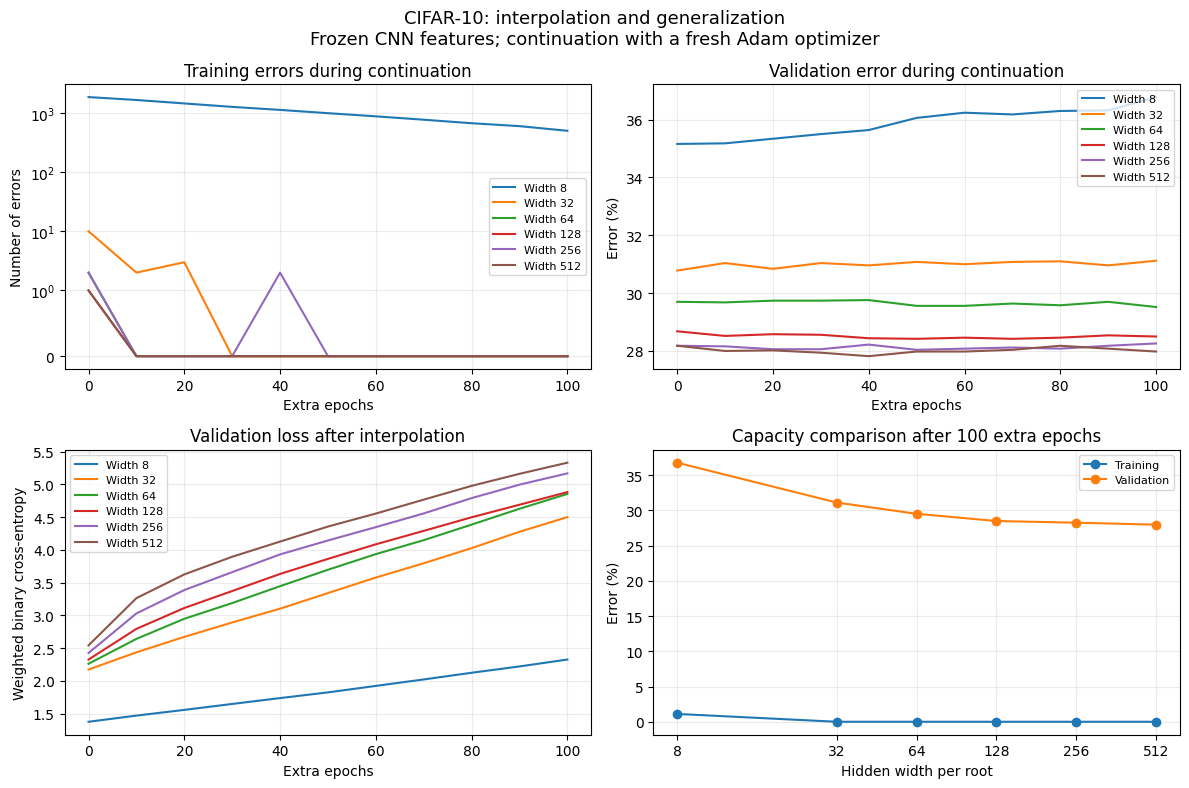

Saved PNG and PDF.


In [83]:
import csv
import matplotlib.pyplot as plt

with open("cifar_capacity_extended_results.csv", newline="") as file:
    rows = list(csv.DictReader(file))

widths = [8, 32, 64, 128, 256, 512]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for width in widths:
    data = sorted(
        [r for r in rows if int(r["width"]) == width],
        key=lambda r: int(r["extra_epoch"])
    )

    epochs = [int(r["extra_epoch"]) for r in data]
    errors = [int(r["train_errors"]) for r in data]
    val_errors = [
        100 - float(r["validation_accuracy"]) for r in data
    ]
    val_loss = [float(r["validation_loss"]) for r in data]

    axes[0, 0].plot(epochs, errors, label=f"Width {width}")
    axes[0, 1].plot(epochs, val_errors, label=f"Width {width}")
    axes[1, 0].plot(epochs, val_loss, label=f"Width {width}")

final_rows = [
    next(
        r for r in rows
        if int(r["width"]) == width
        and int(r["extra_epoch"]) == 100
    )
    for width in widths
]

axes[1, 1].plot(
    widths,
    [100 - float(r["train_accuracy"]) for r in final_rows],
    "o-", label="Training"
)
axes[1, 1].plot(
    widths,
    [100 - float(r["validation_accuracy"]) for r in final_rows],
    "o-", label="Validation"
)
axes[1, 1].set_xscale("log", base=2)
axes[1, 1].set_xticks(widths, labels=widths)

axes[0, 0].set(
    title="Training errors during continuation",
    xlabel="Extra epochs", ylabel="Number of errors"
)
axes[0, 0].set_yscale("symlog", linthresh=1)

axes[0, 1].set(
    title="Validation error during continuation",
    xlabel="Extra epochs", ylabel="Error (%)"
)
axes[1, 0].set(
    title="Validation loss after interpolation",
    xlabel="Extra epochs", ylabel="Weighted binary cross-entropy"
)
axes[1, 1].set(
    title="Capacity comparison after 100 extra epochs",
    xlabel="Hidden width per root", ylabel="Error (%)"
)

for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "CIFAR-10: interpolation and generalization\n"
    "Frozen CNN features; continuation with a fresh Adam optimizer",
    fontsize=13
)
fig.tight_layout()

fig.savefig("cifar_interpolation_analysis.png", dpi=300)
fig.savefig("cifar_interpolation_analysis.pdf")
plt.show()

print("Saved PNG and PDF.")

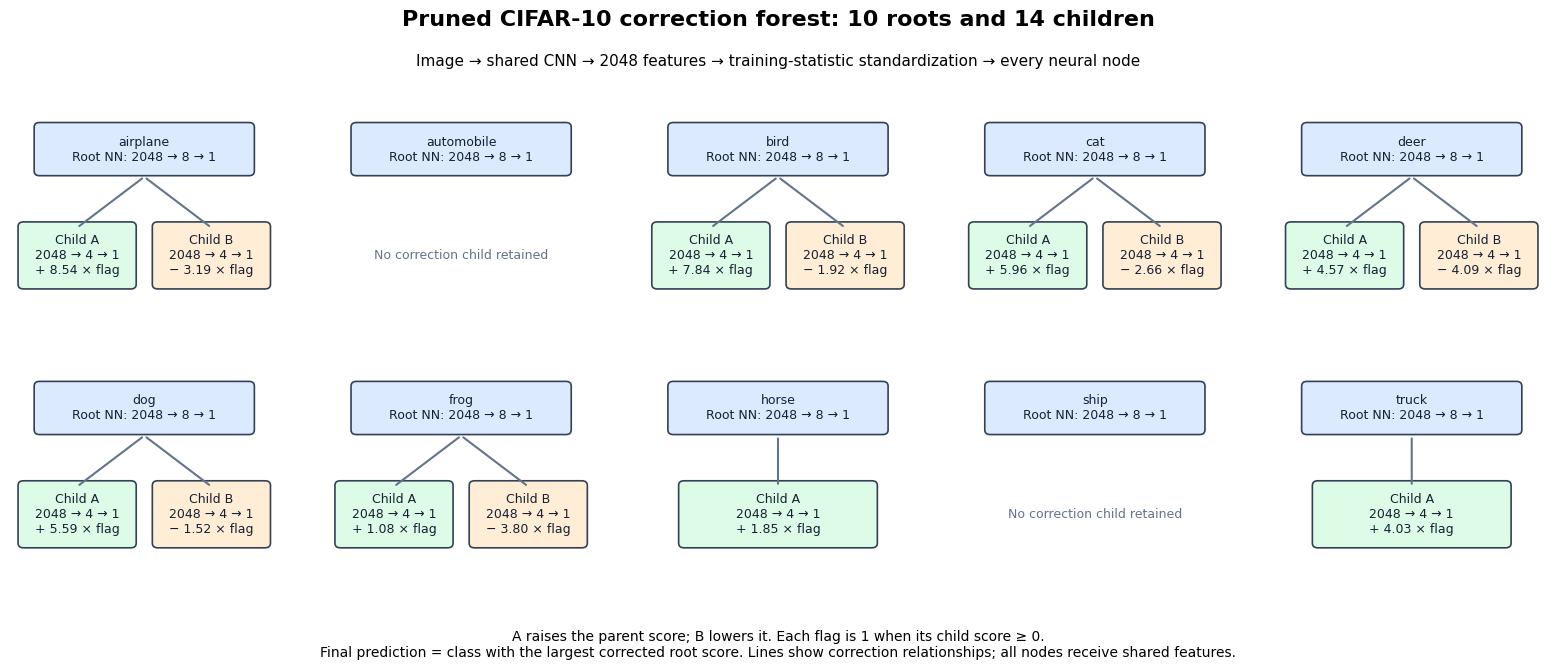

Saved architecture diagram as PNG and PDF.


In [84]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

def draw_node(ax, x, y, text, color, width=0.78, height=0.19):
    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width, height,
        boxstyle="round,pad=0.02",
        facecolor=color,
        edgecolor="#334155",
        linewidth=1.2
    )
    ax.add_patch(box)
    ax.text(
        x, y, text,
        ha="center", va="center",
        fontsize=9, color="#172033"
    )

for class_index, ax in enumerate(axes.flat):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    draw_node(
        ax, 0.5, 0.82,
        f"{cifar_class_names[class_index]}\nRoot NN: 2048 → 8 → 1",
        "#DBEAFE"
    )

    retained = [
        name for name in ["A", "B"]
        if (class_index, name) in cifar_pruned_children
    ]

    positions = (
        [0.5] if len(retained) == 1
        else [0.25, 0.75]
    )

    for name, x in zip(retained, positions):
        key = (class_index, name)
        width = cifar_child_tasks[class_index]["child_width"]
        strength = cifar_pruned_strengths[key]

        ax.annotate(
            "",
            xy=(x, 0.48),
            xytext=(0.5, 0.70),
            arrowprops=dict(
                arrowstyle="-",
                color="#64748B",
                linewidth=1.5
            )
        )

        sign = "+" if name == "A" else "−"
        draw_node(
            ax, x, 0.36,
            f"Child {name}\n2048 → {width} → 1\n"
            f"{sign} {strength:.2f} × flag",
            "#DCFCE7" if name == "A" else "#FFEDD5",
            width=0.40 if len(retained) == 2 else 0.70,
            height=0.25
        )

    if not retained:
        ax.text(
            0.5, 0.36,
            "No correction child retained",
            ha="center", va="center",
            fontsize=9, color="#64748B"
        )

fig.suptitle(
    "Pruned CIFAR-10 correction forest: 10 roots and 14 children",
    fontsize=16, fontweight="bold", y=0.98
)

fig.text(
    0.5, 0.90,
    "Image → shared CNN → 2048 features → training-statistic "
    "standardization → every neural node",
    ha="center", fontsize=11
)

fig.text(
    0.5, 0.055,
    "A raises the parent score; B lowers it. "
    "Each flag is 1 when its child score ≥ 0.\n"
    "Final prediction = class with the largest corrected root score. "
    "Lines show correction relationships; all nodes receive shared features.",
    ha="center", fontsize=10
)

fig.subplots_adjust(
    left=0.02, right=0.98, top=0.84,
    bottom=0.14, wspace=0.18, hspace=0.12
)

fig.savefig("cifar_pruned_tree_architecture.png", dpi=300,
            bbox_inches="tight")
fig.savefig("cifar_pruned_tree_architecture.pdf",
            bbox_inches="tight")
plt.show()

print("Saved architecture diagram as PNG and PDF.")

In [85]:
for name in [
    "trunk", "cnn_trunk", "cifar_trunk",
    "model", "val_dataset", "val_subset",
    "train_dataset", "full_train_dataset"
]:
    value = globals().get(name)
    if value is not None:
        print(name, "→", type(value).__name__)

trunk → CNNTrunk
model → Sequential
val_dataset → Subset
train_dataset → Subset
full_train_dataset → CIFAR10


Validation predictions fixed: 30
Validation predictions damaged: 33


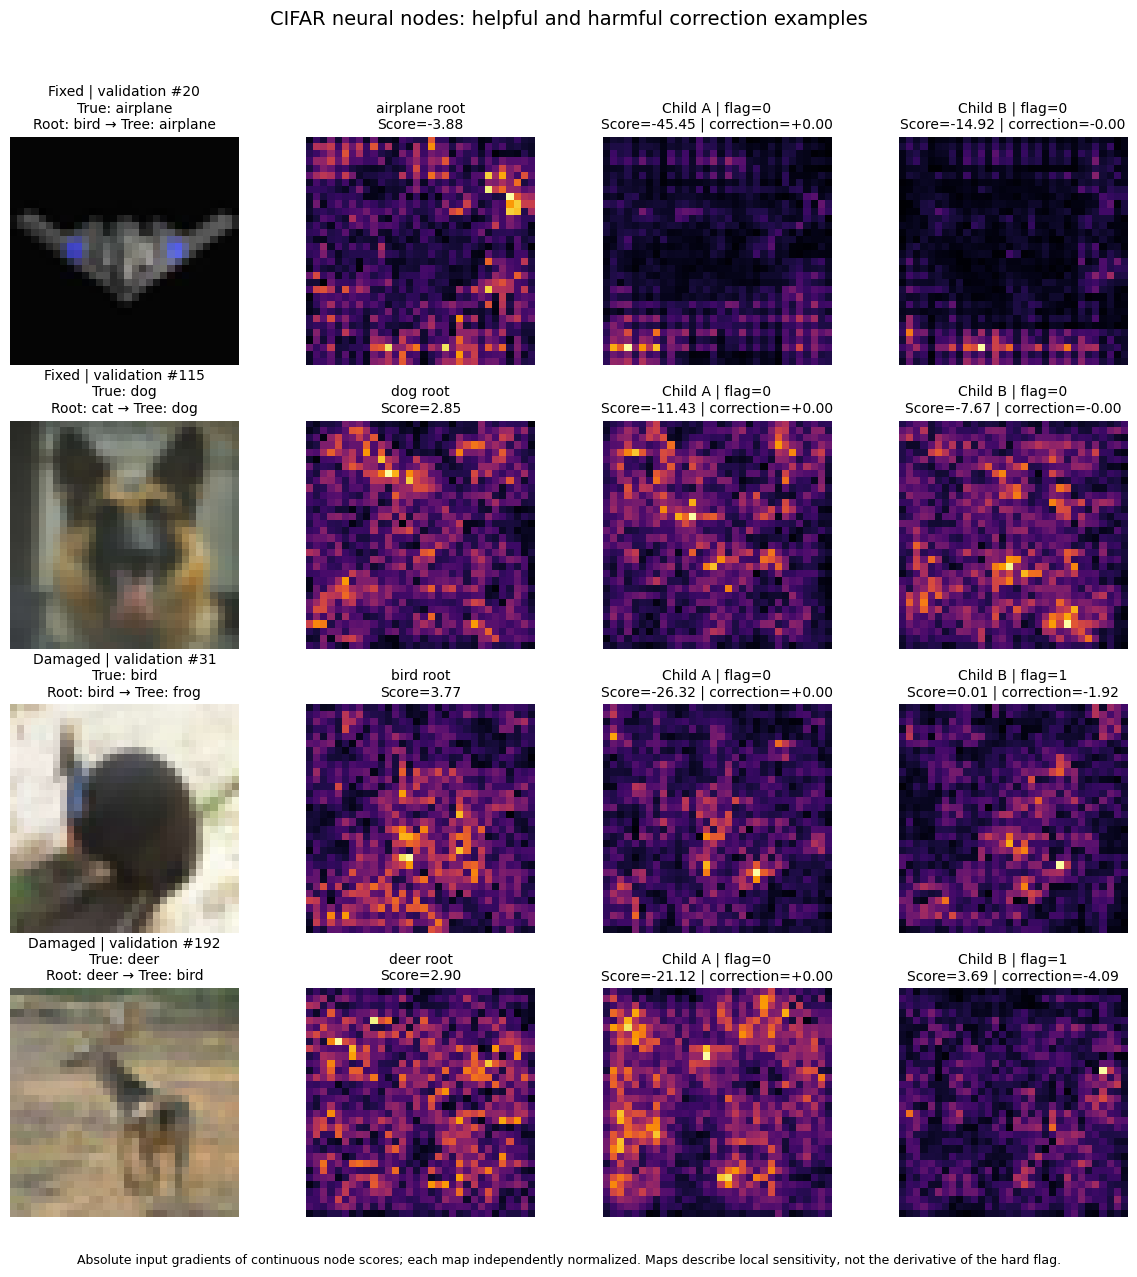

In [86]:
import matplotlib.pyplot as plt

trunk.eval()
cifar_innovation_roots[8].eval()

# Verify the dataset order and trunk against cached validation features.
sample_image, sample_label = val_dataset[0]

with torch.no_grad():
    reproduced = trunk(sample_image.unsqueeze(0).to(device)).cpu()[0]

assert sample_label == int(cifar_innovation_y_val[0])
assert torch.allclose(
    reproduced, X_val[0].detach().cpu(),
    atol=1e-4, rtol=1e-4
), "The trunk or validation dataset does not match cached features."

parent_predictions = cifar_base_val.argmax(1)
tree_predictions = cifar_corrected_val.argmax(1)
truth = cifar_innovation_y_val

helped = (
    (parent_predictions != truth) & (tree_predictions == truth)
).nonzero(as_tuple=True)[0]

harmed = (
    (parent_predictions == truth) & (tree_predictions != truth)
).nonzero(as_tuple=True)[0]

print("Validation predictions fixed:", len(helped))
print("Validation predictions damaged:", len(harmed))

examples = (
    [("Fixed", int(i)) for i in helped[:2]]
    + [("Damaged", int(i)) for i in harmed[:2]]
)

assert examples, "No helpful or harmful examples found."

mean = feature_mean.detach().to(device)
std = feature_std.detach().to(device)


def node_sensitivity(image, node):
    node.eval()
    x = image.unsqueeze(0).to(device).detach().requires_grad_(True)

    with torch.enable_grad():
        features = (trunk(x) - mean) / std
        score = node(features).reshape(-1)[0]
        gradient = torch.autograd.grad(score, x)[0]

    sensitivity = gradient.abs().amax(dim=1)[0].detach().cpu()
    peak = sensitivity.max().item()

    normalized = sensitivity / peak if peak > 0 else sensitivity
    return normalized.numpy(), score.detach().item()


fig, axes = plt.subplots(
    len(examples), 4,
    figsize=(12, 3.2 * len(examples)),
    squeeze=False
)

for row, (outcome, index) in enumerate(examples):
    image, label = val_dataset[index]
    assert int(label) == int(truth[index])

    # Explain the true-class root and its retained children.
    class_index = int(label)
    class_name = cifar_class_names[class_index]

    axes[row, 0].imshow(image.permute(1, 2, 0).cpu().clamp(0, 1))
    axes[row, 0].set_title(
        f"{outcome} | validation #{index}\n"
        f"True: {class_name}\n"
        f"Root: {cifar_class_names[int(parent_predictions[index])]}"
        f" → Tree: {cifar_class_names[int(tree_predictions[index])]}",
        fontsize=10
    )

    root = cifar_innovation_roots[8].nodes[class_index]
    sensitivity, score = node_sensitivity(image, root)

    axes[row, 1].imshow(
        sensitivity, cmap="inferno", vmin=0, vmax=1
    )
    axes[row, 1].set_title(
        f"{class_name} root\nScore={score:.2f}", fontsize=10
    )

    for column, child_name in [(2, "A"), (3, "B")]:
        key = (class_index, child_name)
        ax = axes[row, column]

        if key not in cifar_pruned_children:
            ax.text(
                0.5, 0.5, f"Child {child_name}\nNot retained",
                ha="center", va="center", transform=ax.transAxes
            )
        else:
            sensitivity, score = node_sensitivity(
                image, cifar_pruned_children[key]
            )
            ax.imshow(sensitivity, cmap="inferno", vmin=0, vmax=1)

            # Use the cached flag used in the actual correction.
            flag = int(cifar_val_flags[key][index])
            sign = 1 if child_name == "A" else -1
            contribution = (
                sign * cifar_pruned_strengths[key] * flag
            )

            ax.set_title(
                f"Child {child_name} | flag={flag}\n"
                f"Score={score:.2f} | correction={contribution:+.2f}",
                fontsize=10
            )

    for ax in axes[row]:
        ax.axis("off")

fig.suptitle(
    "CIFAR neural nodes: helpful and harmful correction examples",
    fontsize=14, y=0.995
)
fig.tight_layout(rect=[0, 0.04, 1, 0.97])

fig.text(
    0.5, 0.015,
    "Absolute input gradients of continuous node scores; "
    "each map independently normalized. "
    "Maps describe local sensitivity, not the derivative of the hard flag.",
    ha="center", fontsize=9
)

fig.savefig("cifar_helpful_harmful_sensitivity.png",
            dpi=300, bbox_inches="tight")
fig.savefig("cifar_helpful_harmful_sensitivity.pdf",
            bbox_inches="tight")
plt.show()

In [87]:
for outcome, index in examples:
    print(
        f"\n{outcome} | validation #{index} "
        f"| true={cifar_class_names[int(truth[index])]}"
    )

    changes = (
        cifar_corrected_val[index] - cifar_base_val[index]
    )

    for class_index in range(10):
        contributions = []

        for child_name in ["A", "B"]:
            key = (class_index, child_name)

            if key in cifar_pruned_children:
                flag = int(cifar_val_flags[key][index])
                direction = 1 if child_name == "A" else -1
                amount = (
                    direction * cifar_pruned_strengths[key] * flag
                )

                if flag:
                    contributions.append(
                        f"{child_name}: {amount:+.3f}"
                    )

        if contributions:
            print(
                f"{cifar_class_names[class_index]:10s}: "
                f"root={cifar_base_val[index, class_index]:.3f} "
                f"→ corrected="
                f"{cifar_corrected_val[index, class_index]:.3f} "
                f"| {', '.join(contributions)}"
            )


Fixed | validation #20 | true=airplane
bird      : root=-2.627 → corrected=-4.549 | B: -1.922

Fixed | validation #115 | true=dog
bird      : root=1.687 → corrected=-0.235 | B: -1.922
cat       : root=2.948 → corrected=0.285 | B: -2.663

Damaged | validation #31 | true=bird
bird      : root=3.769 → corrected=1.847 | B: -1.922

Damaged | validation #192 | true=deer
deer      : root=2.901 → corrected=-1.192 | B: -4.093
dog       : root=-10.924 → corrected=-12.443 | B: -1.519


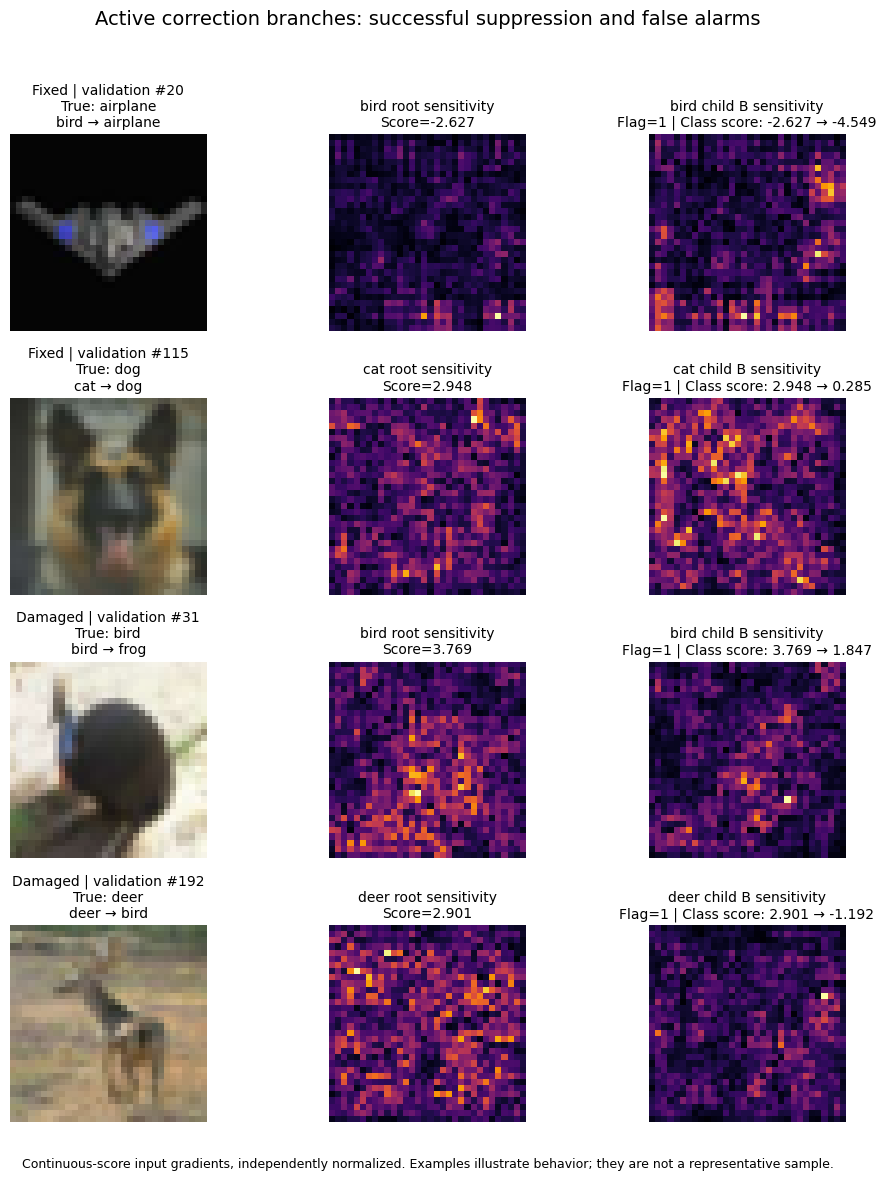

In [88]:
# Active branches explaining these four examples.
explanatory_branches = [
    ("Fixed", 20, 2, "B"),     # Bird B suppresses competing bird.
    ("Fixed", 115, 3, "B"),    # Cat B suppresses competing cat.
    ("Damaged", 31, 2, "B"),   # Bird B suppresses genuine bird.
    ("Damaged", 192, 4, "B")   # Deer B suppresses genuine deer.
]

fig, axes = plt.subplots(4, 3, figsize=(10, 12))

for row, (outcome, index, class_index, child_name) in enumerate(
    explanatory_branches
):
    image, label = val_dataset[index]
    key = (class_index, child_name)
    branch_name = cifar_class_names[class_index]

    axes[row, 0].imshow(
        image.permute(1, 2, 0).cpu().clamp(0, 1)
    )
    axes[row, 0].set_title(
        f"{outcome} | validation #{index}\n"
        f"True: {cifar_class_names[int(label)]}\n"
        f"{cifar_class_names[int(parent_predictions[index])]} → "
        f"{cifar_class_names[int(tree_predictions[index])]}",
        fontsize=10
    )

    root_map, root_score = node_sensitivity(
        image, cifar_innovation_roots[8].nodes[class_index]
    )
    child_map, child_score = node_sensitivity(
        image, cifar_pruned_children[key]
    )

    axes[row, 1].imshow(root_map, cmap="inferno", vmin=0, vmax=1)
    axes[row, 1].set_title(
        f"{branch_name} root sensitivity\n"
        f"Score={root_score:.3f}",
        fontsize=10
    )

    axes[row, 2].imshow(child_map, cmap="inferno", vmin=0, vmax=1)
    axes[row, 2].set_title(
        f"{branch_name} child {child_name} sensitivity\n"
        f"Flag={int(cifar_val_flags[key][index])} | "
        f"Class score: "
        f"{cifar_base_val[index, class_index]:.3f} → "
        f"{cifar_corrected_val[index, class_index]:.3f}",
        fontsize=10
    )

    for ax in axes[row]:
        ax.axis("off")

fig.suptitle(
    "Active correction branches: successful suppression and false alarms",
    fontsize=14
)
fig.tight_layout(rect=[0, 0.04, 1, 0.96])
fig.text(
    0.5, 0.015,
    "Continuous-score input gradients, independently normalized. "
    "Examples illustrate behavior; they are not a representative sample.",
    ha="center", fontsize=9
)

fig.savefig("cifar_active_branch_sensitivity.png",
            dpi=300, bbox_inches="tight")
fig.savefig("cifar_active_branch_sensitivity.pdf",
            bbox_inches="tight")
plt.show()

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

for name in [
    "device", "trunk", "full_train_dataset",
    "train_dataset", "val_dataset",
    "X_train", "y_train"
]:
    value = globals().get(name)

    if value is None:
        print(name, "→ not loaded")
    elif isinstance(value, torch.Tensor):
        print(name, "→", tuple(value.shape))
    else:
        print(name, "→", type(value).__name__)
        

PyTorch: 2.13.0
MPS available: True
device → not loaded
trunk → not loaded
full_train_dataset → not loaded
train_dataset → not loaded
val_dataset → not loaded
X_train → not loaded
y_train → not loaded


In [2]:
from pathlib import Path
import torch

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print("Device:", device)
print("Notebook working folder:", Path.cwd())

search_folders = [Path.cwd(), Path.home()]
found = set()

for folder in search_folders:
    for pattern in ["cifar*.pt", "*cifar*.pth"]:
        for path in folder.glob(pattern):
            found.add(path.resolve())

print("\nSaved CIFAR checkpoints:")
for path in sorted(found):
    print(path)

if not found:
    print("No checkpoints found in these two folders.")

print("\nPossible dataset folders:")
for folder in {
    Path.cwd() / "data",
    Path.home() / "data"
}:
    print(folder, "→", "exists" if folder.exists() else "not found")

Device: mps
Notebook working folder: /Users/aroma

Saved CIFAR checkpoints:
/Users/aroma/cifar10_capacity_width_128.pt
/Users/aroma/cifar10_capacity_width_256.pt
/Users/aroma/cifar10_capacity_width_32.pt
/Users/aroma/cifar10_capacity_width_512.pt
/Users/aroma/cifar10_capacity_width_64.pt
/Users/aroma/cifar10_capacity_width_8.pt
/Users/aroma/cifar10_neural_tree_final.pt
/Users/aroma/cifar_adaptive_tree_seed42.pt
/Users/aroma/cifar_airplane_correction_child.pt
/Users/aroma/cifar_all_binary_roots.pt
/Users/aroma/cifar_baseline_before_tree.pt
/Users/aroma/cifar_capacity_extended_width_128.pt
/Users/aroma/cifar_capacity_extended_width_256.pt
/Users/aroma/cifar_capacity_extended_width_32.pt
/Users/aroma/cifar_capacity_extended_width_512.pt
/Users/aroma/cifar_capacity_extended_width_64.pt
/Users/aroma/cifar_capacity_extended_width_8.pt
/Users/aroma/cifar_cat_binary_root.pt
/Users/aroma/cifar_cat_correction_tree.pt
/Users/aroma/cifar_innovation_class0_childA.pt
/Users/aroma/cifar_innovation_cl

In [3]:
checkpoint_path = Path.home() / "cifar10_neural_tree_final.pt"

# Load only your own trusted checkpoint.
cifar_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(cifar_checkpoint.keys()))

for key, value in cifar_checkpoint.items():
    if isinstance(value, dict):
        print(f"\n{key}: dictionary with {len(value)} entries")

        for name, item in list(value.items())[:5]:
            if isinstance(item, torch.Tensor):
                print(" ", name, "→", tuple(item.shape))
            else:
                print(" ", name, "→", type(item).__name__)

    elif isinstance(value, torch.Tensor):
        print(key, "→ tensor", tuple(value.shape))

    elif isinstance(value, (str, int, float, list, tuple)):
        print(key, "→", value)

Checkpoint keys: ['trunk_state', 'roots_state', 'airplane_child_state', 'root_hidden_width', 'child_hidden_width', 'feature_mean', 'feature_std', 'airplane_index', 'correction_strength', 'child_threshold', 'classes', 'results']

trunk_state: dictionary with 4 entries
  layers.0.weight → (16, 3, 3, 3)
  layers.0.bias → (16,)
  layers.3.weight → (32, 16, 3, 3)
  layers.3.bias → (32,)

roots_state: dictionary with 42 entries
  feature_mean → (2048,)
  feature_std → (2048,)
  nodes.0.layers.0.weight → (256, 2048)
  nodes.0.layers.0.bias → (256,)
  nodes.0.layers.2.weight → (1, 256)

airplane_child_state: dictionary with 4 entries
  layers.0.weight → (128, 2048)
  layers.0.bias → (128,)
  layers.2.weight → (1, 128)
  layers.2.bias → (1,)
root_hidden_width → 256
child_hidden_width → 128
feature_mean → tensor (2048,)
feature_std → tensor (2048,)
airplane_index → 0
correction_strength → 3.625056505203247
child_threshold → 0.0
classes → ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', '

In [4]:
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Separate outputs for the new assignment.
experiment_folder = Path.home() / "tree_augmentation_ensemble"
experiment_folder.mkdir(exist_ok=True)


class CNNTrunk(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten()
        )

    def forward(self, images):
        return self.layers(images)


# Restore the original CNN.
original_trunk = CNNTrunk().to(device)
original_trunk.load_state_dict(
    cifar_checkpoint["trunk_state"], strict=True
)
original_trunk.eval()

clean_transform = transforms.ToTensor()

augmentation_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

dataset_folder = Path.home() / "data"

clean_cifar = datasets.CIFAR10(
    root=dataset_folder,
    train=True,
    download=False,
    transform=clean_transform
)

augmented_cifar = datasets.CIFAR10(
    root=dataset_folder,
    train=True,
    download=False,
    transform=augmentation_transform
)

# Recreate the earlier seed-42 random_split ordering.
split_order = torch.randperm(
    len(clean_cifar),
    generator=torch.Generator().manual_seed(42)
)

train_indices = split_order[:45000]
val_indices = split_order[45000:]

clean_train_dataset = Subset(
    clean_cifar, train_indices.tolist()
)
augmented_train_dataset = Subset(
    augmented_cifar, train_indices.tolist()
)
clean_val_dataset = Subset(
    clean_cifar, val_indices.tolist()
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

clean_train_loader = DataLoader(
    clean_train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

clean_val_loader = DataLoader(
    clean_val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

torch.save({
    "train_indices": train_indices,
    "validation_indices": val_indices,
    "split_seed": 42
}, experiment_folder / "split_indices.pt")

sample_images, sample_labels = next(iter(augmented_train_loader))

with torch.no_grad():
    sample_features = original_trunk(sample_images.to(device))

print("Clean training images:", len(clean_train_dataset))
print("Augmented training images:", len(augmented_train_dataset))
print("Validation images:", len(clean_val_dataset))
print("Augmented batch:", sample_images.shape)
print("CNN features:", sample_features.shape)
print("Outputs folder:", experiment_folder)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Clean training images: 45000
Augmented training images: 45000
Validation images: 5000
Augmented batch: torch.Size([128, 3, 32, 32])
CNN features: torch.Size([128, 2048])
Outputs folder: /Users/aroma/tree_augmentation_ensemble


In [5]:
import copy
import time
import csv

class FeatureTrainingModel(nn.Module):
    def __init__(self, trunk):
        super().__init__()
        self.trunk = trunk
        self.head = nn.Sequential(
            nn.Linear(2048, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, images):
        return self.head(self.trunk(images))


@torch.no_grad()
def evaluate_feature_model(network, loader):
    network.eval()
    total_loss = 0.0
    errors = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        scores = network(images)
        total_loss += nn.functional.cross_entropy(
            scores, labels, reduction="sum"
        ).item()
        errors += (scores.argmax(1) != labels).sum().item()
        total += len(labels)

    return {
        "loss": total_loss / total,
        "accuracy": 100 * (1 - errors / total),
        "errors": errors
    }


# Identical starting weights for both conditions.
torch.manual_seed(123)
starting_model = FeatureTrainingModel(
    copy.deepcopy(original_trunk)
).cpu()

feature_models = {}
feature_training_history = []
feature_epochs = 20

for condition, dataset in [
    ("clean", clean_train_dataset),
    ("augmented", augmented_train_dataset)
]:
    torch.manual_seed(123)

    network = copy.deepcopy(starting_model).to(device)
    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(123)
    )

    print(f"\nTRAINING: {condition.upper()}", flush=True)

    for epoch in range(1, feature_epochs + 1):
        start = time.perf_counter()

        if epoch == 16:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()
        online_loss_sum = 0.0
        samples_seen = 0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)
            scores = network(images)
            loss = nn.functional.cross_entropy(scores, labels)
            loss.backward()
            optimizer.step()

            online_loss_sum += loss.item() * len(labels)
            samples_seen += len(labels)

        # Both conditions are measured on ORIGINAL training images.
        train_result = evaluate_feature_model(
            network, clean_train_loader
        )
        val_result = evaluate_feature_model(
            network, clean_val_loader
        )

        row = {
            "condition": condition,
            "epoch": epoch,
            "online_training_loss": online_loss_sum / samples_seen,
            "clean_train_loss": train_result["loss"],
            "clean_train_accuracy": train_result["accuracy"],
            "clean_train_errors": train_result["errors"],
            "validation_loss": val_result["loss"],
            "validation_accuracy": val_result["accuracy"],
            "validation_errors": val_result["errors"]
        }
        feature_training_history.append(row)

        torch.save({
            "trunk_state": {
                key: value.detach().cpu()
                for key, value in network.trunk.state_dict().items()
            },
            "head_state": {
                key: value.detach().cpu()
                for key, value in network.head.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "condition": condition,
            "epoch": epoch,
            "history": [
                record for record in feature_training_history
                if record["condition"] == condition
            ]
        }, experiment_folder / f"feature_model_{condition}.pt")

        with (
            experiment_folder / "feature_training_history.csv"
        ).open("w", newline="") as file:
            writer = csv.DictWriter(
                file, fieldnames=feature_training_history[0].keys()
            )
            writer.writeheader()
            writer.writerows(feature_training_history)

        print(
            f"Epoch {epoch}: "
            f"clean train={train_result['accuracy']:.2f}% "
            f"| validation={val_result['accuracy']:.2f}% "
            f"| time={time.perf_counter() - start:.1f}s",
            flush=True
        )

    feature_models[condition] = network

print("\nBoth feature extractors saved.")


TRAINING: CLEAN
Epoch 1: clean train=65.33% | validation=63.14% | time=3.7s
Epoch 2: clean train=68.77% | validation=63.90% | time=3.2s
Epoch 3: clean train=70.79% | validation=64.84% | time=3.1s
Epoch 4: clean train=72.74% | validation=65.50% | time=3.3s
Epoch 5: clean train=73.10% | validation=65.20% | time=3.2s
Epoch 6: clean train=75.28% | validation=65.84% | time=3.1s
Epoch 7: clean train=76.90% | validation=66.60% | time=3.2s
Epoch 8: clean train=77.92% | validation=66.52% | time=3.1s
Epoch 9: clean train=80.11% | validation=66.22% | time=3.1s
Epoch 10: clean train=81.30% | validation=66.20% | time=3.2s
Epoch 11: clean train=81.67% | validation=66.52% | time=3.2s
Epoch 12: clean train=80.09% | validation=63.32% | time=3.1s
Epoch 13: clean train=83.45% | validation=65.08% | time=3.3s
Epoch 14: clean train=84.96% | validation=65.20% | time=3.1s
Epoch 15: clean train=84.70% | validation=64.80% | time=3.1s
Epoch 16: clean train=89.49% | validation=66.34% | time=3.2s
Epoch 17: clean 

In [6]:
feature_cache = {}

@torch.no_grad()
def extract_feature_cache(trunk, dataset):
    trunk.eval()

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0
    )

    features_list = []
    labels_list = []

    for images, labels in loader:
        features_list.append(
            trunk(images.to(device)).cpu()
        )
        labels_list.append(labels.cpu())

    return torch.cat(features_list), torch.cat(labels_list)


for condition in ["clean", "augmented"]:
    trunk_for_cache = feature_models[condition].trunk

    train_features, train_labels = extract_feature_cache(
        trunk_for_cache, clean_train_dataset
    )
    val_features, val_labels = extract_feature_cache(
        trunk_for_cache, clean_val_dataset
    )

    # Fit normalization on original training images only.
    mean = train_features.mean(dim=0)
    std = train_features.std(dim=0).clamp_min(1e-6)

    cache = {
        "train_features": train_features,
        "train_labels": train_labels,
        "validation_features": val_features,
        "validation_labels": val_labels,
        "feature_mean": mean,
        "feature_std": std,
        "train_indices": train_indices,
        "validation_indices": val_indices,
        "augmented_views": []
    }

    if condition == "augmented":
        for view_number in range(2):
            torch.manual_seed(1000 + view_number)

            view_features, view_labels = extract_feature_cache(
                trunk_for_cache, augmented_train_dataset
            )

            assert torch.equal(view_labels, train_labels)

            cache["augmented_views"].append(view_features)
            print(
                f"Augmented view {view_number + 1}:",
                view_features.shape,
                flush=True
            )

    feature_cache[condition] = cache

    torch.save(
        cache,
        experiment_folder / f"features_{condition}.pt"
    )

    print(
        f"\n{condition.upper()}: "
        f"train={tuple(train_features.shape)}, "
        f"validation={tuple(val_features.shape)}",
        flush=True
    )

print("\nFeature caches saved.")


CLEAN: train=(45000, 2048), validation=(5000, 2048)
Augmented view 1: torch.Size([45000, 2048])
Augmented view 2: torch.Size([45000, 2048])

AUGMENTED: train=(45000, 2048), validation=(5000, 2048)

Feature caches saved.


In [7]:
import torch.nn.functional as F
from torch.utils.data import TensorDataset

class AssignmentRoots(nn.Module):
    def __init__(self, mean, std, width=128):
        super().__init__()
        self.register_buffer("feature_mean", mean.clone())
        self.register_buffer("feature_std", std.clone())

        self.nodes = nn.ModuleList([
            nn.Sequential(
                nn.Linear(2048, width),
                nn.ReLU(),
                nn.Linear(width, 1)
            )
            for _ in range(10)
        ])

    def forward(self, features):
        z = (features - self.feature_mean) / self.feature_std
        return torch.cat([node(z) for node in self.nodes], dim=1)


@torch.no_grad()
def evaluate_assignment_roots(network, features, labels):
    network.eval()

    scores = torch.cat([
        network(batch.to(device)).cpu()
        for batch in features.split(512)
    ])

    predictions = scores.argmax(1)
    errors = (predictions != labels).sum().item()

    return {
        "accuracy": 100 * (1 - errors / len(labels)),
        "errors": errors,
        # Common multiclass diagnostic, separate from training BCE.
        "cross_entropy": F.cross_entropy(scores, labels).item(),
        "predictions": predictions
    }


assignment_roots = {}
root_history = []
root_width = 128
root_seed = 42
saved_epochs = {1, 5, 10, 20, 40, 60, 80, 100}

for condition in ["clean", "augmented"]:
    cache = feature_cache[condition]
    labels = cache["train_labels"].long()
    targets = F.one_hot(labels, num_classes=10).float()

    positive_counts = targets.sum(0)
    positive_weights = (
        (len(labels) - positive_counts) / positive_counts
    ).to(device)

    torch.manual_seed(root_seed)

    roots = AssignmentRoots(
        cache["feature_mean"],
        cache["feature_std"],
        width=root_width
    ).to(device)

    optimizer = torch.optim.Adam(roots.parameters(), lr=0.001)
    criterion = nn.BCEWithLogitsLoss(pos_weight=positive_weights)

    # Shuffle original-image IDs, keeping their views associated.
    index_loader = DataLoader(
        TensorDataset(torch.arange(len(labels))),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(root_seed)
    )

    views = [
        cache["train_features"],
        *cache["augmented_views"]
    ]
    view_rng = torch.Generator().manual_seed(2026)

    print(f"\nTRAINING ROOTS: {condition.upper()}", flush=True)

    for epoch in range(1, 101):
        if epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        roots.train()
        start = time.perf_counter()

        for (indices,) in index_loader:
            view_index = (
                int(torch.randint(
                    len(views), (1,), generator=view_rng
                ).item())
                if len(views) > 1 else 0
            )

            features = views[view_index][indices].to(device)
            batch_targets = targets[indices].to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(roots(features), batch_targets)
            loss.backward()
            optimizer.step()

        if epoch in saved_epochs:
            train_result = evaluate_assignment_roots(
                roots, cache["train_features"], labels
            )
            val_result = evaluate_assignment_roots(
                roots,
                cache["validation_features"],
                cache["validation_labels"].long()
            )

            row = {
                "condition": condition,
                "seed": root_seed,
                "width": root_width,
                "epoch": epoch,
                "training_images": len(labels),
                "train_accuracy": train_result["accuracy"],
                "train_errors": train_result["errors"],
                "train_cross_entropy": train_result["cross_entropy"],
                "validation_accuracy": val_result["accuracy"],
                "validation_errors": val_result["errors"],
                "validation_cross_entropy": val_result["cross_entropy"]
            }
            root_history.append(row)

            torch.save({
                "state": {
                    name: value.detach().cpu().clone()
                    for name, value in roots.state_dict().items()
                },
                "optimizer_state": optimizer.state_dict(),
                "width": root_width,
                "seed": root_seed,
                "epoch": epoch,
                "condition": condition,
                "validation_predictions": val_result["predictions"],
                "metrics": row
            }, experiment_folder / (
                f"roots_{condition}_seed{root_seed}_epoch{epoch}.pt"
            ))

            with (
                experiment_folder / "root_training_history.csv"
            ).open("w", newline="") as file:
                writer = csv.DictWriter(
                    file, fieldnames=root_history[0].keys()
                )
                writer.writeheader()
                writer.writerows(root_history)

            print(
                f"Epoch {epoch}: "
                f"clean train={train_result['accuracy']:.4f}% "
                f"| train errors={train_result['errors']} "
                f"| validation={val_result['accuracy']:.2f}% "
                f"| val CE={val_result['cross_entropy']:.3f}",
                flush=True
            )

    assignment_roots[condition] = roots

print("\nRoot training complete; checkpoints and predictions saved.")


TRAINING ROOTS: CLEAN
Epoch 1: clean train=73.2511% | train errors=12037 | validation=66.48% | val CE=0.975
Epoch 5: clean train=93.1311% | train errors=3091 | validation=70.08% | val CE=1.259
Epoch 10: clean train=99.2378% | train errors=343 | validation=71.26% | val CE=1.775
Epoch 20: clean train=99.9689% | train errors=14 | validation=71.90% | val CE=2.320
Epoch 40: clean train=99.9978% | train errors=1 | validation=71.88% | val CE=2.930
Epoch 60: clean train=100.0000% | train errors=0 | validation=71.90% | val CE=3.231
Epoch 80: clean train=100.0000% | train errors=0 | validation=71.76% | val CE=3.433
Epoch 100: clean train=100.0000% | train errors=0 | validation=71.88% | val CE=3.822

TRAINING ROOTS: AUGMENTED
Epoch 1: clean train=69.0156% | train errors=13943 | validation=65.80% | val CE=0.992
Epoch 5: clean train=79.1067% | train errors=9402 | validation=71.28% | val CE=0.956
Epoch 10: clean train=87.0511% | train errors=5827 | validation=72.10% | val CE=1.077
Epoch 20: clean t

In [8]:
import copy

@torch.no_grad()
def assignment_scores(network, features):
    network.eval()
    return torch.cat([
        network(batch.to(device)).cpu()
        for batch in features.split(512)
    ])


class AssignmentChild(nn.Module):
    def __init__(self, width=16):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2048, width),
            nn.ReLU(),
            nn.Linear(width, 1)
        )

    def forward(self, features):
        return self.layers(features).squeeze(-1)


cache = feature_cache["augmented"]
parent = assignment_roots["augmented"]

labels = cache["train_labels"].long()
parent_scores = assignment_scores(parent, cache["train_features"])
parent_predictions = parent_scores.argmax(1)
wrong = parent_predictions != labels

mean = cache["feature_mean"]
std = cache["feature_std"]

clean_Z = (cache["train_features"] - mean) / std

augmentation_children = {}
child_task_results = []

print("Multiclass mistakes:", wrong.sum().item())

for class_index in range(10):
    actual_class = labels == class_index

    for child_name in ["A", "B"]:
        if child_name == "A":
            # Raise the true-class score on misclassified examples.
            correction_targets = wrong & actual_class
            protected = ~actual_class
        else:
            # Lower the incorrectly winning class score.
            correction_targets = wrong & (
                parent_predictions == class_index
            )
            protected = actual_class

        positives = int(correction_targets.sum().item())
        if positives == 0:
            continue

        task_mask = correction_targets | protected
        task_X = clean_Z[task_mask]
        task_y = correction_targets[task_mask].float()
        negatives = len(task_y) - positives

        seed = 4200 + 2 * class_index + (child_name == "B")
        torch.manual_seed(seed)

        child = AssignmentChild(width=16).to(device)
        optimizer = torch.optim.Adam(child.parameters(), lr=0.001)
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                negatives / positives,
                dtype=torch.float32,
                device=device
            )
        )

        loader = DataLoader(
            TensorDataset(task_X, task_y),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=torch.Generator().manual_seed(seed)
        )

        best_key = None
        best_state = None
        best_result = None

        print(
            f"\n{clean_cifar.classes[class_index]} child {child_name}: "
            f"{positives} correction targets",
            flush=True
        )

        for epoch in range(1, 101):
            child.train()

            for features, targets in loader:
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(
                    child(features.to(device)),
                    targets.to(device)
                )
                loss.backward()
                optimizer.step()

            with torch.no_grad():
                child.eval()
                scores = torch.cat([
                    child(batch.to(device)).cpu()
                    for batch in task_X.split(512)
                ])

            flags = scores >= 0
            actual = task_y.bool()

            missed = int(((~flags) & actual).sum().item())
            unwanted = int((flags & (~actual)).sum().item())

            balanced_error = 0.5 * (
                missed / positives + unwanted / negatives
            )
            key = (balanced_error, missed + unwanted)

            if best_key is None or key < best_key:
                best_key = key
                best_state = {
                    name: value.detach().cpu().clone()
                    for name, value in child.state_dict().items()
                }
                best_result = {
                    "epoch": epoch,
                    "missed_corrections": missed,
                    "unwanted_flags": unwanted
                }

            if missed == 0 and unwanted == 0:
                break

        child.load_state_dict(best_state)
        child.eval()
        augmentation_children[(class_index, child_name)] = child

        record = {
            "class_index": class_index,
            "child": child_name,
            "width": 16,
            "positive_targets": positives,
            **best_result
        }
        child_task_results.append(record)

        torch.save({
            "state": best_state,
            "task": record,
            "feature_mean": mean,
            "feature_std": std
        }, experiment_folder / (
            f"augmented_child_class{class_index}_{child_name}.pt"
        ))

        print(
            f"Selected epoch {best_result['epoch']}: "
            f"missed={best_result['missed_corrections']} "
            f"| unwanted={best_result['unwanted_flags']}",
            flush=True
        )

print("\nTrained children:", len(augmentation_children))

Multiclass mistakes: 4

airplane child B: 3 correction targets
Selected epoch 87: missed=0 | unwanted=6

bird child A: 4 correction targets
Selected epoch 52: missed=0 | unwanted=0

deer child B: 1 correction targets
Selected epoch 96: missed=0 | unwanted=3

Trained children: 3


In [9]:
import json

cache = feature_cache["augmented"]

aug_base_train = assignment_scores(
    parent, cache["train_features"]
).double()

aug_base_val = assignment_scores(
    parent, cache["validation_features"]
).double()

aug_train_y = cache["train_labels"].long()
aug_val_y = cache["validation_labels"].long()

aug_val_Z = (
    cache["validation_features"] - mean
) / std

train_flags = {
    key: assignment_scores(child, clean_Z) >= 0
    for key, child in augmentation_children.items()
}
val_flags = {
    key: assignment_scores(child, aug_val_Z) >= 0
    for key, child in augmentation_children.items()
}


def multiclass_errors(scores, labels):
    return int((scores.argmax(1) != labels).sum().item())


def proposed_strength(base, flags, class_index, direction, labels):
    """Find the best interval between class-score crossings."""
    initial_pred = base.argmax(1)
    initial_errors = multiclass_errors(base, labels)

    competitors = base.clone()
    competitors[:, class_index] = -torch.inf
    other_scores, other_classes = competitors.max(1)

    crossings = (
        other_scores - base[:, class_index]
    ) / direction

    rows = (
        flags & (crossings >= 0)
    ).nonzero(as_tuple=True)[0]

    if len(rows) == 0:
        return 0.0

    thresholds = crossings[rows]
    after_pred = (
        torch.full_like(rows, class_index)
        if direction == 1 else other_classes[rows]
    )

    changes = (
        (after_pred != labels[rows]).long()
        - (initial_pred[rows] != labels[rows]).long()
    )

    order = thresholds.argsort()
    thresholds = thresholds[order]
    changes = changes[order]

    unique, counts = torch.unique_consecutive(
        thresholds, return_counts=True
    )
    group_ends = counts.cumsum(0) - 1
    errors = initial_errors + changes.cumsum(0)[group_ends]

    strengths = torch.empty_like(unique)
    if len(unique) > 1:
        strengths[:-1] = (unique[:-1] + unique[1:]) / 2

    last = unique[-1].item()
    strengths[-1] = last + max(1.0, abs(last) * 0.01)

    if errors.min().item() >= initial_errors:
        return 0.0

    best_index = int(
        (errors == errors.min()).nonzero(as_tuple=True)[0][0]
    )
    return strengths[best_index].item()


aug_strengths = {
    key: 0.0 for key in augmentation_children
}
aug_tree_train = aug_base_train.clone()

for pass_number in range(1, 6):
    previous = aug_strengths.copy()

    for key in augmentation_children:
        class_index, child_name = key
        direction = 1 if child_name == "A" else -1
        flags = train_flags[key].double()
        old_strength = aug_strengths[key]

        base = aug_tree_train.clone()
        base[:, class_index] -= direction * old_strength * flags

        proposal = proposed_strength(
            base, train_flags[key], class_index,
            direction, aug_train_y
        )

        # Explicitly include the current setting:
        # a coordinate update cannot increase training errors.
        best_scores = aug_tree_train
        best_strength = old_strength
        best_key = (
            multiclass_errors(best_scores, aug_train_y),
            old_strength
        )

        for strength in sorted({0.0, old_strength, proposal}):
            trial = base.clone()
            trial[:, class_index] += direction * strength * flags

            trial_key = (
                multiclass_errors(trial, aug_train_y),
                strength
            )
            if trial_key < best_key:
                best_key = trial_key
                best_strength = strength
                best_scores = trial

        aug_strengths[key] = best_strength
        aug_tree_train = best_scores

    print(
        f"Pass {pass_number}: "
        f"training errors={multiclass_errors(aug_tree_train, aug_train_y)}"
    )

    if aug_strengths == previous:
        break


aug_tree_val = aug_base_val.clone()

for key, strength in aug_strengths.items():
    class_index, child_name = key
    direction = 1 if child_name == "A" else -1
    aug_tree_val[:, class_index] += (
        direction * strength * val_flags[key].double()
    )

print("\nSTRENGTHS")
for (class_index, child_name), strength in aug_strengths.items():
    print(
        clean_cifar.classes[class_index],
        child_name, f"= {strength:.6f}"
    )

aug_tree_results = {}

for split, base, corrected, labels in [
    ("train", aug_base_train, aug_tree_train, aug_train_y),
    ("validation", aug_base_val, aug_tree_val, aug_val_y)
]:
    base_errors = multiclass_errors(base, labels)
    tree_errors = multiclass_errors(corrected, labels)

    aug_tree_results[split] = {
        "root_errors": base_errors,
        "tree_errors": tree_errors,
        "root_accuracy": 100 * (1 - base_errors / len(labels)),
        "tree_accuracy": 100 * (1 - tree_errors / len(labels))
    }

    print(
        f"\n{split.upper()}: "
        f"roots={aug_tree_results[split]['root_accuracy']:.4f}% "
        f"({base_errors} errors) | "
        f"tree={aug_tree_results[split]['tree_accuracy']:.4f}% "
        f"({tree_errors} errors)"
    )


torch.save({
    "trunk_state": {
        key: value.detach().cpu()
        for key, value in feature_models["augmented"].trunk.state_dict().items()
    },
    "roots_state": {
        key: value.detach().cpu()
        for key, value in parent.state_dict().items()
    },
    "root_width": root_width,
    "children": {
        key: {
            "width": 16,
            "state": {
                name: value.detach().cpu()
                for name, value in child.state_dict().items()
            },
            "strength": aug_strengths[key]
        }
        for key, child in augmentation_children.items()
    },
    "classes": clean_cifar.classes,
    "train_indices": train_indices,
    "validation_indices": val_indices,
    "results": aug_tree_results
}, experiment_folder / "augmented_tree_seed42.pt")

print("\nSaved: augmented_tree_seed42.pt")

Pass 1: training errors=0
Pass 2: training errors=0
Pass 3: training errors=0

STRENGTHS
airplane B = 0.000000
bird A = 3.521489
deer B = 0.000000

TRAIN: roots=99.9911% (4 errors) | tree=100.0000% (0 errors)

VALIDATION: roots=74.3800% (1281 errors) | tree=74.3800% (1281 errors)

Saved: augmented_tree_seed42.pt


In [10]:
ensemble_seeds = [101, 102, 103, 104, 105]
ensemble_resamples = {}

number_of_images = len(
    feature_cache["augmented"]["train_labels"]
)

for seed in ensemble_seeds:
    generator = torch.Generator().manual_seed(seed)

    # Bootstrap ORIGINAL image IDs, not individual augmented views.
    indices = torch.randint(
        number_of_images,
        (number_of_images,),
        generator=generator
    )

    ensemble_resamples[seed] = indices

    print(
        f"Seed {seed}: {len(indices)} sampled IDs "
        f"| unique images={indices.unique().numel()}"
    )

torch.save({
    "seeds": ensemble_seeds,
    "resamples": ensemble_resamples,
    "sampling": "bootstrap original training-image IDs",
    "shared_trunk": "augmented feature extractor",
    "vote_tie_break": "smallest class index"
}, experiment_folder / "ensemble_resamples.pt")

print("\nSaved: ensemble_resamples.pt")

Seed 101: 45000 sampled IDs | unique images=28483
Seed 102: 45000 sampled IDs | unique images=28463
Seed 103: 45000 sampled IDs | unique images=28468
Seed 104: 45000 sampled IDs | unique images=28575
Seed 105: 45000 sampled IDs | unique images=28479

Saved: ensemble_resamples.pt


In [11]:
ensemble_root_history = []
ensemble_root_models = {}
ensemble_width = 128
ensemble_epochs = 100
ensemble_saved_epochs = {1, 5, 10, 20, 40, 60, 80, 100}

cache = feature_cache["augmented"]
ensemble_labels = cache["train_labels"].long()

ensemble_targets = F.one_hot(
    ensemble_labels, num_classes=10
).float()

ensemble_views = [
    cache["train_features"],
    *cache["augmented_views"]
]

for seed in ensemble_seeds:
    sampled_ids = ensemble_resamples[seed]

    torch.manual_seed(seed)

    roots = AssignmentRoots(
        cache["feature_mean"],
        cache["feature_std"],
        width=ensemble_width
    ).to(device)

    optimizer = torch.optim.Adam(
        roots.parameters(), lr=0.001
    )

    # Class weights fitted to this member's bootstrap sample.
    positive_counts = ensemble_targets[sampled_ids].sum(0)
    assert (positive_counts > 0).all()

    positive_weights = (
        (len(sampled_ids) - positive_counts) / positive_counts
    ).to(device)

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=positive_weights
    )

    loader = DataLoader(
        TensorDataset(sampled_ids),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed)
    )

    view_rng = torch.Generator().manual_seed(seed + 10000)
    member_start = time.perf_counter()

    print(f"\nENSEMBLE MEMBER: SEED {seed}", flush=True)

    for epoch in range(1, ensemble_epochs + 1):
        if epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        roots.train()

        for (image_ids,) in loader:
            view_index = int(torch.randint(
                len(ensemble_views), (1,), generator=view_rng
            ).item())

            features = ensemble_views[view_index][image_ids].to(device)
            targets = ensemble_targets[image_ids].to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(roots(features), targets)
            loss.backward()
            optimizer.step()

        if epoch in ensemble_saved_epochs:
            train_scores = assignment_scores(
                roots, cache["train_features"]
            )
            validation_scores = assignment_scores(
                roots, cache["validation_features"]
            )

            train_predictions = train_scores.argmax(1)
            validation_predictions = validation_scores.argmax(1)

            # Training fit is measured on this member's sampled IDs.
            sampled_errors = int((
                train_predictions[sampled_ids]
                != ensemble_labels[sampled_ids]
            ).sum().item())

            all_train_errors = int((
                train_predictions != ensemble_labels
            ).sum().item())

            validation_errors = int((
                validation_predictions
                != cache["validation_labels"]
            ).sum().item())

            row = {
                "seed": seed,
                "epoch": epoch,
                "sampled_train_accuracy": (
                    100 * (1 - sampled_errors / len(sampled_ids))
                ),
                "sampled_train_errors": sampled_errors,
                "all_train_accuracy": (
                    100 * (1 - all_train_errors / len(ensemble_labels))
                ),
                "validation_accuracy": (
                    100 * (
                        1 - validation_errors
                        / len(cache["validation_labels"])
                    )
                ),
                "validation_errors": validation_errors,
                "validation_cross_entropy": F.cross_entropy(
                    validation_scores,
                    cache["validation_labels"].long()
                ).item()
            }
            ensemble_root_history.append(row)

            # Intermediate predictions support across-epoch analysis.
            saved = {
                "seed": seed,
                "epoch": epoch,
                "width": ensemble_width,
                "sampled_ids": sampled_ids,
                "validation_scores": validation_scores,
                "validation_predictions": validation_predictions,
                "metrics": row
            }

            # Save final weights for correction-child training.
            if epoch == ensemble_epochs:
                saved["state"] = {
                    name: value.detach().cpu().clone()
                    for name, value in roots.state_dict().items()
                }
                saved["optimizer_state"] = optimizer.state_dict()
                saved["all_train_scores"] = train_scores

            torch.save(
                saved,
                experiment_folder / (
                    f"ensemble_root_seed{seed}_epoch{epoch}.pt"
                )
            )

            with (
                experiment_folder / "ensemble_root_history.csv"
            ).open("w", newline="") as file:
                writer = csv.DictWriter(
                    file, fieldnames=ensemble_root_history[0].keys()
                )
                writer.writeheader()
                writer.writerows(ensemble_root_history)

            print(
                f"Epoch {epoch}: "
                f"sampled train={row['sampled_train_accuracy']:.4f}% "
                f"| all train={row['all_train_accuracy']:.2f}% "
                f"| validation={row['validation_accuracy']:.2f}%",
                flush=True
            )

    # Keep completed members on CPU to conserve GPU memory.
    ensemble_root_models[seed] = roots.cpu()

    print(
        f"Saved member {seed} "
        f"| time={time.perf_counter() - member_start:.1f}s",
        flush=True
    )

print("\nFive ensemble root models completed.")


ENSEMBLE MEMBER: SEED 101
Epoch 1: sampled train=71.6556% | all train=68.51% | validation=65.88%
Epoch 5: sampled train=85.4844% | all train=78.13% | validation=69.08%
Epoch 10: sampled train=94.3289% | all train=84.77% | validation=70.42%
Epoch 20: sampled train=98.3178% | all train=87.99% | validation=70.16%
Epoch 40: sampled train=99.5556% | all train=88.94% | validation=70.88%
Epoch 60: sampled train=99.9800% | all train=89.76% | validation=72.02%
Epoch 80: sampled train=99.9978% | all train=89.84% | validation=72.26%
Epoch 100: sampled train=100.0000% | all train=89.95% | validation=72.28%
Saved member 101 | time=113.4s

ENSEMBLE MEMBER: SEED 102
Epoch 1: sampled train=71.2422% | all train=68.47% | validation=64.82%
Epoch 5: sampled train=85.3489% | all train=78.52% | validation=69.56%
Epoch 10: sampled train=93.5378% | all train=84.40% | validation=70.78%
Epoch 20: sampled train=98.4356% | all train=88.32% | validation=70.82%
Epoch 40: sampled train=99.5911% | all train=89.30% |

In [12]:
import itertools
import json

validation_labels = feature_cache["augmented"][
    "validation_labels"
].long()

member_predictions = []

for seed in ensemble_seeds:
    saved = torch.load(
        experiment_folder / f"ensemble_root_seed{seed}_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )
    member_predictions.append(
        saved["validation_predictions"].long()
    )

# Shape: [5 models, 5000 validation images].
member_predictions = torch.stack(member_predictions)


def majority_vote(predictions):
    # Each model contributes one vote per image.
    counts = F.one_hot(
        predictions, num_classes=10
    ).sum(dim=0)

    # argmax selects the smallest class index if counts tie.
    predicted = counts.argmax(dim=1)
    highest_count = counts.max(dim=1).values

    tied = (
        counts == highest_count.unsqueeze(1)
    ).sum(dim=1) > 1

    return predicted, tied


ensemble_vote_results = []

for number_of_members in [1, 3, 5]:
    group_results = []

    for group in itertools.combinations(
        range(len(ensemble_seeds)), number_of_members
    ):
        selected = member_predictions[list(group)]
        predictions, tied = majority_vote(selected)

        errors = int((
            predictions != validation_labels
        ).sum().item())

        record = {
            "members": [ensemble_seeds[i] for i in group],
            "number_of_members": number_of_members,
            "accuracy": 100 * (1 - errors / len(validation_labels)),
            "errors": errors,
            "ties": int(tied.sum().item())
        }
        group_results.append(record)
        ensemble_vote_results.append(record)

    accuracies = torch.tensor(
        [r["accuracy"] for r in group_results],
        dtype=torch.float64
    )

    print(
        f"{number_of_members} member(s): "
        f"mean validation={accuracies.mean().item():.2f}% "
        f"| range={accuracies.min().item():.2f}%"
        f"–{accuracies.max().item():.2f}% "
        f"| groups={len(group_results)}"
    )

# Measure diversity through pairwise prediction disagreement.
pairwise_disagreement = []

for first, second in itertools.combinations(range(5), 2):
    disagreement = (
        member_predictions[first] != member_predictions[second]
    ).float().mean().item()

    pairwise_disagreement.append(disagreement)

print(
    "\nMean pairwise disagreement:",
    f"{100 * sum(pairwise_disagreement) / len(pairwise_disagreement):.2f}%"
)

five_predictions, five_ties = majority_vote(member_predictions)

print("Five-member voting ties:", int(five_ties.sum().item()))
print("Full-data single-tree validation: 74.38%")

with (
    experiment_folder / "ensemble_validation_voting.json"
).open("w") as file:
    json.dump({
        "results": ensemble_vote_results,
        "mean_pairwise_disagreement": (
            sum(pairwise_disagreement) / len(pairwise_disagreement)
        ),
        "tie_break": "smallest class index",
        "shared_augmented_CNN": True
    }, file, indent=2)

torch.save({
    "member_predictions": member_predictions,
    "five_member_predictions": five_predictions,
    "validation_labels": validation_labels,
    "seeds": ensemble_seeds
}, experiment_folder / "ensemble_validation_predictions.pt")

print("\nVoting results saved.")

1 member(s): mean validation=72.46% | range=72.18%–72.68% | groups=5
3 member(s): mean validation=73.97% | range=73.64%–74.22% | groups=10
5 member(s): mean validation=74.76% | range=74.76%–74.76% | groups=1

Mean pairwise disagreement: 20.93%
Five-member voting ties: 179
Full-data single-tree validation: 74.38%

Voting results saved.


In [13]:
bias_variance_history = []
epochs_to_analyze = [1, 5, 10, 20, 40, 60, 80, 100]

labels = feature_cache["augmented"]["validation_labels"].long()
label_vectors = F.one_hot(labels, num_classes=10).double()

for epoch in epochs_to_analyze:
    predictions = []

    for seed in ensemble_seeds:
        checkpoint = torch.load(
            experiment_folder / (
                f"ensemble_root_seed{seed}_epoch{epoch}.pt"
            ),
            map_location="cpu",
            weights_only=False
        )
        predictions.append(checkpoint["validation_predictions"].long())

    predictions = torch.stack(predictions)

    # [models, images, classes]
    prediction_vectors = F.one_hot(
        predictions, num_classes=10
    ).double()

    mean_prediction = prediction_vectors.mean(dim=0)

    bias_proxy = (
        0.5 * (mean_prediction - label_vectors).square().sum(-1)
    ).mean().item()

    prediction_variance = (
        0.5
        * (prediction_vectors - mean_prediction.unsqueeze(0))
          .square().sum(-1)
    ).mean().item()

    mean_member_error = (
        predictions != labels.unsqueeze(0)
    ).double().mean().item()

    voted, tied = majority_vote(predictions)
    vote_error = (
        voted != labels
    ).double().mean().item()

    residual = abs(
        mean_member_error - bias_proxy - prediction_variance
    )
    assert residual < 1e-10

    row = {
        "epoch": epoch,
        "mean_member_error": mean_member_error,
        "squared_bias_proxy": bias_proxy,
        "prediction_variance": prediction_variance,
        "majority_vote_error": vote_error,
        "voting_ties": int(tied.sum().item()),
        "decomposition_residual": residual
    }
    bias_variance_history.append(row)

    print(
        f"Epoch {epoch:3d}: "
        f"member error={100 * mean_member_error:.2f}% "
        f"| bias proxy={bias_proxy:.4f} "
        f"| variance={prediction_variance:.4f} "
        f"| vote accuracy={100 * (1 - vote_error):.2f}%"
    )

with (
    experiment_folder / "bias_variance_across_epochs.csv"
).open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=bias_variance_history[0].keys()
    )
    writer.writeheader()
    writer.writerows(bias_variance_history)

print("\nSaved: bias_variance_across_epochs.csv")

Epoch   1: member error=34.59% | bias proxy=0.2572 | variance=0.0886 | vote accuracy=67.30%
Epoch   5: member error=30.38% | bias proxy=0.2186 | variance=0.0852 | vote accuracy=72.66%
Epoch  10: member error=29.28% | bias proxy=0.2040 | variance=0.0888 | vote accuracy=73.08%
Epoch  20: member error=28.94% | bias proxy=0.1954 | variance=0.0940 | vote accuracy=74.00%
Epoch  40: member error=28.79% | bias proxy=0.1892 | variance=0.0987 | vote accuracy=74.94%
Epoch  60: member error=27.78% | bias proxy=0.1905 | variance=0.0873 | vote accuracy=75.18%
Epoch  80: member error=27.65% | bias proxy=0.1915 | variance=0.0850 | vote accuracy=74.88%
Epoch 100: member error=27.54% | bias proxy=0.1917 | variance=0.0837 | vote accuracy=74.76%

Saved: bias_variance_across_epochs.csv


In [14]:
sample_size_records = []

for sample_size in [5000, 15000]:
    for seed in ensemble_seeds:
        torch.manual_seed(seed)

        # Draw from the same 45,000-image training pool.
        sampled_ids = torch.randint(
            len(ensemble_labels),
            (sample_size,),
            generator=torch.Generator().manual_seed(seed)
        )

        roots = AssignmentRoots(
            cache["feature_mean"],
            cache["feature_std"],
            width=ensemble_width
        ).to(device)

        optimizer = torch.optim.Adam(roots.parameters(), lr=0.001)

        positive_counts = ensemble_targets[sampled_ids].sum(0)
        assert (positive_counts > 0).all()

        weights = (
            (sample_size - positive_counts) / positive_counts
        ).to(device)

        criterion = nn.BCEWithLogitsLoss(pos_weight=weights)

        loader = DataLoader(
            TensorDataset(sampled_ids),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=torch.Generator().manual_seed(seed)
        )

        view_rng = torch.Generator().manual_seed(seed + 10000)

        print(
            f"\nSAMPLE DRAWS={sample_size}, SEED={seed} "
            f"| unique images={sampled_ids.unique().numel()}",
            flush=True
        )

        for epoch in range(1, 101):
            if epoch == 51:
                for group in optimizer.param_groups:
                    group["lr"] = 0.0001

            roots.train()

            for (image_ids,) in loader:
                view_index = int(torch.randint(
                    len(ensemble_views), (1,), generator=view_rng
                ).item())

                optimizer.zero_grad(set_to_none=True)
                loss = criterion(
                    roots(ensemble_views[view_index][image_ids].to(device)),
                    ensemble_targets[image_ids].to(device)
                )
                loss.backward()
                optimizer.step()

            if epoch in ensemble_saved_epochs:
                validation_scores = assignment_scores(
                    roots, cache["validation_features"]
                )
                predictions = validation_scores.argmax(1)

                result = {
                    "sample_draws": sample_size,
                    "unique_images": sampled_ids.unique().numel(),
                    "seed": seed,
                    "epoch": epoch,
                    "optimizer_steps": epoch * len(loader),
                    "validation_accuracy": 100 * (
                        predictions == cache["validation_labels"]
                    ).float().mean().item()
                }

                saved = {
                    **result,
                    "sampled_ids": sampled_ids,
                    "validation_predictions": predictions
                }

                if epoch == 100:
                    # Measure fit on this member's actual training sample.
                    unique_ids = sampled_ids.unique()
                    sampled_scores = assignment_scores(
                        roots, cache["train_features"][unique_ids]
                    )
                    unique_predictions = sampled_scores.argmax(1)

                    unique_errors = int((
                        unique_predictions != ensemble_labels[unique_ids]
                    ).sum().item())

                    result["unique_clean_training_errors"] = unique_errors
                    saved["unique_clean_training_errors"] = unique_errors
                    saved["state"] = {
                        name: value.detach().cpu().clone()
                        for name, value in roots.state_dict().items()
                    }

                    print(
                        f"Epoch 100: validation="
                        f"{result['validation_accuracy']:.2f}% "
                        f"| unique clean training errors={unique_errors}",
                        flush=True
                    )

                sample_size_records.append(result)

                torch.save(
                    saved,
                    experiment_folder / (
                        f"sample_size_{sample_size}_seed{seed}"
                        f"_epoch{epoch}.pt"
                    )
                )

        roots.cpu()

print("\nSmaller-sample experiments complete.")


SAMPLE DRAWS=5000, SEED=101 | unique images=4751
Epoch 100: validation=64.02% | unique clean training errors=0

SAMPLE DRAWS=5000, SEED=102 | unique images=4732
Epoch 100: validation=63.36% | unique clean training errors=0

SAMPLE DRAWS=5000, SEED=103 | unique images=4736
Epoch 100: validation=63.84% | unique clean training errors=0

SAMPLE DRAWS=5000, SEED=104 | unique images=4740
Epoch 100: validation=63.64% | unique clean training errors=0

SAMPLE DRAWS=5000, SEED=105 | unique images=4737
Epoch 100: validation=64.36% | unique clean training errors=0

SAMPLE DRAWS=15000, SEED=101 | unique images=12806
Epoch 100: validation=68.92% | unique clean training errors=0

SAMPLE DRAWS=15000, SEED=102 | unique images=12803
Epoch 100: validation=68.60% | unique clean training errors=0

SAMPLE DRAWS=15000, SEED=103 | unique images=12734
Epoch 100: validation=68.56% | unique clean training errors=0

SAMPLE DRAWS=15000, SEED=104 | unique images=12819
Epoch 100: validation=68.42% | unique clean tr

In [15]:
sample_size_bias_variance = []

labels = feature_cache["augmented"]["validation_labels"].long()
label_vectors = F.one_hot(labels, num_classes=10).double()

for sample_size in [5000, 15000, 45000]:
    for epoch in epochs_to_analyze:
        predictions = []
        unique_counts = []

        for seed in ensemble_seeds:
            filename = (
                f"ensemble_root_seed{seed}_epoch{epoch}.pt"
                if sample_size == 45000
                else f"sample_size_{sample_size}_seed{seed}_epoch{epoch}.pt"
            )

            saved = torch.load(
                experiment_folder / filename,
                map_location="cpu",
                weights_only=False
            )

            predictions.append(
                saved["validation_predictions"].long()
            )
            unique_counts.append(
                saved["sampled_ids"].unique().numel()
            )

        predictions = torch.stack(predictions)
        vectors = F.one_hot(predictions, num_classes=10).double()
        mean_vector = vectors.mean(0)

        bias_proxy = (
            0.5 * (mean_vector - label_vectors).square().sum(-1)
        ).mean().item()

        variance = (
            0.5 * (vectors - mean_vector.unsqueeze(0))
            .square().sum(-1)
        ).mean().item()

        member_error = (
            predictions != labels.unsqueeze(0)
        ).double().mean().item()

        voted, ties = majority_vote(predictions)
        vote_error = (
            voted != labels
        ).double().mean().item()

        assert abs(member_error - bias_proxy - variance) < 1e-10

        row = {
            "sample_draws": sample_size,
            "mean_unique_images": sum(unique_counts) / len(unique_counts),
            "epoch": epoch,
            "squared_bias_proxy": bias_proxy,
            "prediction_variance": variance,
            "mean_member_accuracy": 100 * (1 - member_error),
            "vote_accuracy": 100 * (1 - vote_error),
            "voting_ties": int(ties.sum().item())
        }
        sample_size_bias_variance.append(row)

        if epoch == 100:
            print(
                f"Draws={sample_size:5d}: "
                f"bias proxy={bias_proxy:.4f} "
                f"| variance={variance:.4f} "
                f"| member accuracy={row['mean_member_accuracy']:.2f}% "
                f"| vote accuracy={row['vote_accuracy']:.2f}% "
                f"| ties={row['voting_ties']}"
            )

with (
    experiment_folder / "sample_size_bias_variance.csv"
).open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=sample_size_bias_variance[0].keys()
    )
    writer.writeheader()
    writer.writerows(sample_size_bias_variance)

print("\nSaved: sample_size_bias_variance.csv")

Draws= 5000: bias proxy=0.2285 | variance=0.1330 | member accuracy=63.84% | vote accuracy=68.48% | ties=377
Draws=15000: bias proxy=0.2053 | variance=0.1070 | member accuracy=68.78% | vote accuracy=72.48% | ties=295
Draws=45000: bias proxy=0.1917 | variance=0.0837 | member accuracy=72.46% | vote accuracy=74.76% | ties=179

Saved: sample_size_bias_variance.csv


Landscape rows: 4/17
Landscape rows: 8/17
Landscape rows: 12/17
Landscape rows: 16/17

Center training BCE: 0.0015233703888952732
Center validation BCE: 3.9903156757354736
Minimum sampled training BCE: 0.0015233703888952732
Minimum sampled validation BCE: 3.052271842956543


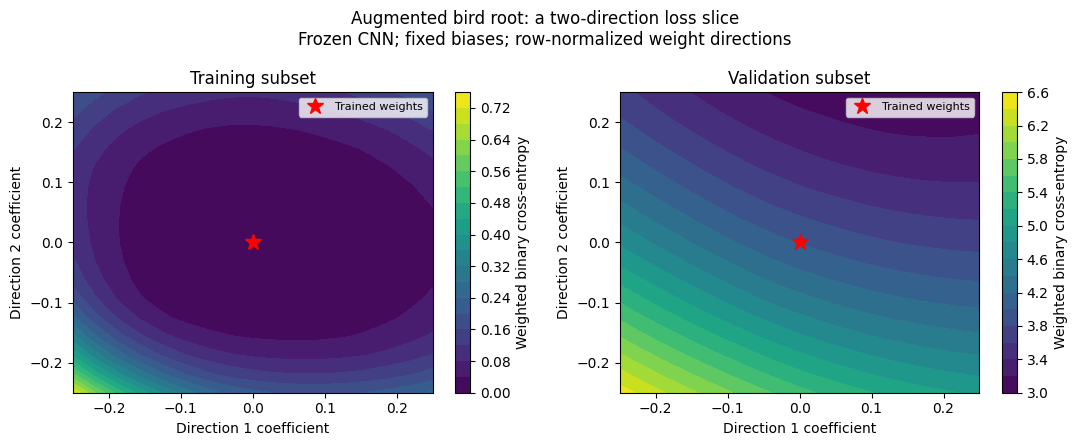

Saved landscape results | time=0.9s


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Work on a COPY of the augmented bird root.
landscape_class = 2  # bird
landscape_node = copy.deepcopy(
    assignment_roots["augmented"].nodes[landscape_class]
).to(device)
landscape_node.eval()

cache = feature_cache["augmented"]

landscape_mean = cache["feature_mean"]
landscape_std = cache["feature_std"]

# Fixed subsets sampled independently of predictions.
landscape_rng = torch.Generator().manual_seed(777)

landscape_train_ids = torch.randperm(
    len(cache["train_labels"]), generator=landscape_rng
)[:2048]

landscape_val_ids = torch.randperm(
    len(cache["validation_labels"]), generator=landscape_rng
)[:2048]

landscape_train_X = (
    (cache["train_features"][landscape_train_ids] - landscape_mean)
    / landscape_std
).to(device)

landscape_val_X = (
    (cache["validation_features"][landscape_val_ids] - landscape_mean)
    / landscape_std
).to(device)

landscape_train_y = (
    cache["train_labels"][landscape_train_ids] == landscape_class
).float().to(device)

landscape_val_y = (
    cache["validation_labels"][landscape_val_ids] == landscape_class
).float().to(device)

# Same positive-class weighting as the full-data root training.
positive_count = (
    cache["train_labels"] == landscape_class
).sum().item()

landscape_pos_weight = (
    len(cache["train_labels"]) - positive_count
) / positive_count

landscape_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        landscape_pos_weight, dtype=torch.float32, device=device
    )
)

center_parameters = {
    name: parameter.detach().clone()
    for name, parameter in landscape_node.named_parameters()
}

direction_rng = torch.Generator().manual_seed(888)


def make_landscape_direction():
    direction = {}

    for name, parameter in center_parameters.items():
        if parameter.ndim < 2:
            # Hold biases fixed.
            direction[name] = torch.zeros_like(parameter)
            continue

        noise = torch.randn(
            parameter.shape, generator=direction_rng
        ).to(device)

        # Normalize each output neuron's perturbation to its weight norm.
        weight_norm = parameter.norm(dim=1, keepdim=True)
        noise_norm = noise.norm(dim=1, keepdim=True).clamp_min(1e-12)

        direction[name] = noise * weight_norm / noise_norm

    return direction


direction_1 = make_landscape_direction()
direction_2 = make_landscape_direction()

coordinates = np.linspace(-0.25, 0.25, 17)
train_surface = np.zeros((17, 17))
val_surface = np.zeros((17, 17))

start = time.perf_counter()

try:
    with torch.no_grad():
        for row, beta in enumerate(coordinates):
            for column, alpha in enumerate(coordinates):
                for name, parameter in landscape_node.named_parameters():
                    parameter.copy_(
                        center_parameters[name]
                        + float(alpha) * direction_1[name]
                        + float(beta) * direction_2[name]
                    )

                train_scores = landscape_node(
                    landscape_train_X
                ).squeeze(-1)

                val_scores = landscape_node(
                    landscape_val_X
                ).squeeze(-1)

                train_surface[row, column] = landscape_criterion(
                    train_scores, landscape_train_y
                ).item()

                val_surface[row, column] = landscape_criterion(
                    val_scores, landscape_val_y
                ).item()

            if (row + 1) % 4 == 0:
                print(f"Landscape rows: {row + 1}/17", flush=True)

finally:
    # Restore the copied node even if evaluation is interrupted.
    with torch.no_grad():
        for name, parameter in landscape_node.named_parameters():
            parameter.copy_(center_parameters[name])

middle = len(coordinates) // 2

print("\nCenter training BCE:", train_surface[middle, middle])
print("Center validation BCE:", val_surface[middle, middle])
print("Minimum sampled training BCE:", train_surface.min())
print("Minimum sampled validation BCE:", val_surface.min())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, surface, title in [
    (axes[0], train_surface, "Training subset"),
    (axes[1], val_surface, "Validation subset")
]:
    contour = ax.contourf(
        coordinates, coordinates, surface,
        levels=20, cmap="viridis"
    )
    ax.plot(0, 0, "r*", markersize=12, label="Trained weights")
    ax.set(
        xlabel="Direction 1 coefficient",
        ylabel="Direction 2 coefficient",
        title=title
    )
    ax.legend(fontsize=8)
    fig.colorbar(contour, ax=ax, label="Weighted binary cross-entropy")

fig.suptitle(
    "Augmented bird root: a two-direction loss slice\n"
    "Frozen CNN; fixed biases; row-normalized weight directions",
    fontsize=12
)
fig.tight_layout()

fig.savefig(
    experiment_folder / "bird_root_loss_landscape.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    experiment_folder / "bird_root_loss_landscape.pdf",
    bbox_inches="tight"
)
plt.show()

np.savez(
    experiment_folder / "bird_root_loss_landscape.npz",
    coordinates=coordinates,
    train_loss=train_surface,
    validation_loss=val_surface,
    train_indices=landscape_train_ids.numpy(),
    validation_indices=landscape_val_ids.numpy()
)

torch.save({
    "center_parameters": {
        name: value.cpu() for name, value in center_parameters.items()
    },
    "direction_1": {
        name: value.cpu() for name, value in direction_1.items()
    },
    "direction_2": {
        name: value.cpu() for name, value in direction_2.items()
    },
    "class_index": landscape_class,
    "positive_weight": landscape_pos_weight
}, experiment_folder / "bird_root_landscape_directions.pt")

print(f"Saved landscape results | time={time.perf_counter() - start:.1f}s")

In [17]:
# Original test images only: no random augmentation.
assignment_test_dataset = datasets.CIFAR10(
    root=dataset_folder,
    train=False,
    download=False,
    transform=clean_transform
)

test_features = {}
test_labels = None

# Each condition must use its own CNN.
for condition in ["clean", "augmented"]:
    features, labels = extract_feature_cache(
        feature_models[condition].trunk.to(device),
        assignment_test_dataset
    )

    test_features[condition] = features

    if test_labels is None:
        test_labels = labels.long()
    else:
        assert torch.equal(test_labels, labels.long())

print("Test images:", len(test_labels))

test_predictions = {}

# Full-data single models.
for condition in ["clean", "augmented"]:
    network = assignment_roots[condition].to(device)

    scores = assignment_scores(
        network, test_features[condition]
    ).double()

    test_predictions[f"{condition}_roots"] = scores.argmax(1)

    if condition == "augmented":
        corrected_scores = scores.clone()

        test_Z = (
            test_features["augmented"]
            - feature_cache["augmented"]["feature_mean"]
        ) / feature_cache["augmented"]["feature_std"]

        for key, strength in aug_strengths.items():
            if strength == 0:
                continue

            class_index, child_name = key
            direction = 1 if child_name == "A" else -1

            child = augmentation_children[key].to(device)
            flags = assignment_scores(child, test_Z) >= 0

            corrected_scores[:, class_index] += (
                direction * strength * flags.double()
            )

        test_predictions["augmented_tree"] = (
            corrected_scores.argmax(1)
        )

# Bootstrap ensemble members.
ensemble_test_predictions = []

for seed in ensemble_seeds:
    saved = torch.load(
        experiment_folder / f"ensemble_root_seed{seed}_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )

    network = AssignmentRoots(
        feature_cache["augmented"]["feature_mean"],
        feature_cache["augmented"]["feature_std"],
        width=saved["width"]
    )
    network.load_state_dict(saved["state"], strict=True)
    network = network.to(device)

    predictions = assignment_scores(
        network, test_features["augmented"]
    ).argmax(1)

    ensemble_test_predictions.append(predictions)
    network.cpu()

ensemble_test_predictions = torch.stack(
    ensemble_test_predictions
)

test_vote_ties = {}

for size in [1, 3, 5]:
    predictions, tied = majority_vote(
        ensemble_test_predictions[:size]
    )

    name = f"ensemble_{size}"
    test_predictions[name] = predictions
    test_vote_ties[name] = int(tied.sum().item())

final_test_results = {}

print("\nFINAL TEST RESULTS")

for name, predictions in test_predictions.items():
    errors = int((predictions != test_labels).sum().item())
    accuracy = 100 * (1 - errors / len(test_labels))

    result = {
        "accuracy": accuracy,
        "errors": errors,
        "images": len(test_labels)
    }

    if name in test_vote_ties:
        result["voting_ties"] = test_vote_ties[name]

    final_test_results[name] = result

    print(
        f"{name:20s}: accuracy={accuracy:.2f}% "
        f"| errors={errors}"
        + (
            f" | ties={test_vote_ties[name]}"
            if name in test_vote_ties else ""
        )
    )

with (
    experiment_folder / "final_test_results.json"
).open("w") as file:
    json.dump({
        "epoch": 100,
        "ensemble_seed_order": ensemble_seeds,
        "tie_break": "smallest class index",
        "results": final_test_results
    }, file, indent=2)

torch.save({
    "labels": test_labels,
    "predictions": test_predictions,
    "member_predictions": ensemble_test_predictions
}, experiment_folder / "final_test_predictions.pt")

print("\nSaved: final_test_results.json")
print("Saved: final_test_predictions.pt")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Test images: 10000

FINAL TEST RESULTS
clean_roots         : accuracy=72.37% | errors=2763
augmented_roots     : accuracy=74.45% | errors=2555
augmented_tree      : accuracy=74.45% | errors=2555
ensemble_1          : accuracy=71.93% | errors=2807 | ties=0
ensemble_3          : accuracy=74.25% | errors=2575 | ties=410
ensemble_5          : accuracy=74.99% | errors=2501 | ties=351

Saved: final_test_results.json
Saved: final_test_predictions.pt


In [18]:
from pathlib import Path
import torch

dd_folder = experiment_folder / "double_descent"
dd_folder.mkdir(exist_ok=True)

dd_cache = feature_cache["augmented"]
dd_all_labels = dd_cache["train_labels"].long().cpu()

dd_widths = [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128, 512]
dd_seeds = [201, 202, 203]

# Select 500 original images per class.
subset_rng = torch.Generator().manual_seed(31415)
selected_ids = []

for class_index in range(10):
    class_ids = (
        dd_all_labels == class_index
    ).nonzero(as_tuple=True)[0]

    order = torch.randperm(
        len(class_ids), generator=subset_rng
    )

    selected_ids.append(class_ids[order[:500]])

dd_ids = torch.cat(selected_ids)
dd_ids = dd_ids[
    torch.randperm(len(dd_ids), generator=subset_rng)
]

dd_clean_labels = dd_all_labels[dd_ids].clone()

# Change exactly 750 labels to a DIFFERENT class.
noise_rng = torch.Generator().manual_seed(27182)
dd_noise_mask = torch.zeros(len(dd_ids), dtype=torch.bool)

noise_positions = torch.randperm(
    len(dd_ids), generator=noise_rng
)[:750]

dd_noise_mask[noise_positions] = True
dd_noisy_labels = dd_clean_labels.clone()

offsets = torch.randint(
    1, 10, (len(noise_positions),), generator=noise_rng
)

dd_noisy_labels[noise_positions] = (
    dd_clean_labels[noise_positions] + offsets
) % 10

assert int((dd_noisy_labels != dd_clean_labels).sum()) == 750

# All views of an image share its assigned training label.
dd_views = [
    dd_cache["train_features"][dd_ids].float().cpu(),
    *[
        view[dd_ids].float().cpu()
        for view in dd_cache["augmented_views"]
    ]
]

# Fit normalization on this subset's ORIGINAL features only.
dd_mean = dd_views[0].mean(0)
dd_std = dd_views[0].std(0).clamp_min(1e-6)

dd_validation_features = (
    dd_cache["validation_features"].float().cpu()
)
dd_validation_labels = (
    dd_cache["validation_labels"].long().cpu()
)

torch.save({
    "subset_ids_in_training_pool": dd_ids,
    "original_cifar_indices": dd_cache["train_indices"][dd_ids],
    "clean_labels": dd_clean_labels,
    "noisy_labels": dd_noisy_labels,
    "noise_mask": dd_noise_mask,
    "feature_mean": dd_mean,
    "feature_std": dd_std,
    "widths": dd_widths,
    "training_seeds": dd_seeds,
    "subset_seed": 31415,
    "noise_seed": 27182,
    "noise_fraction": 0.15
}, dd_folder / "experiment_definition.pt")

print("Original training images:", len(dd_ids))
print("Feature views per image:", len(dd_views))
print("Changed labels:", int(dd_noise_mask.sum()))
print("Clean class counts:", torch.bincount(dd_clean_labels).tolist())
print("Noisy class counts:", torch.bincount(dd_noisy_labels).tolist())
print("Widths:", dd_widths)
print("Saved:", dd_folder / "experiment_definition.pt")

Original training images: 5000
Feature views per image: 3
Changed labels: 750
Clean class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
Noisy class counts: [491, 494, 509, 516, 501, 488, 500, 499, 507, 495]
Widths: [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128, 512]
Saved: /Users/aroma/tree_augmentation_ensemble/double_descent/experiment_definition.pt


In [21]:
import time
import csv
import torch.nn.functional as F

dd_seed = 201
dd_epochs = 300
dd_learning_rate = 0.001
dd_results = []


@torch.no_grad()
def dd_scores(network, features):
    network.eval()
    return torch.cat([
        network(batch.to(device)).cpu()
        for batch in features.split(512)
    ])


for label_condition, assigned_labels in [
    ("clean", dd_clean_labels),
    ("noise15", dd_noisy_labels)
]:
    targets = F.one_hot(
        assigned_labels, num_classes=10
    ).float()

    positives = targets.sum(0)
    pos_weight_cpu = (len(targets) - positives) / positives

    for width in dd_widths:
        checkpoint_path = dd_folder / (
            f"{label_condition}_width{width}_seed{dd_seed}.pt"
        )

        # Skip completed runs if this cell is run again.
        if checkpoint_path.exists():
            existing = torch.load(
                checkpoint_path, map_location="cpu",
                weights_only=False
            )
            if existing["epoch"] >= dd_epochs:
                dd_results.append(existing["history"][-1])
                print(
                    f"Already completed: {label_condition}, width {width}",
                    flush=True
                )
                continue

        torch.manual_seed(dd_seed)

        network = AssignmentRoots(
            dd_mean, dd_std, width=width
        ).to(device)

        optimizer = torch.optim.Adam(
            network.parameters(), lr=dd_learning_rate
        )
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=pos_weight_cpu.to(device)
        )
        cpu_criterion = nn.BCEWithLogitsLoss(
            pos_weight=pos_weight_cpu
        )

        loader_generator = torch.Generator().manual_seed(dd_seed)
        view_generator = torch.Generator().manual_seed(dd_seed + 10000)

        loader = DataLoader(
            TensorDataset(torch.arange(len(assigned_labels))),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=loader_generator
        )

        history = []
        start_epoch = 0

        # Resume interrupted runs.
        if checkpoint_path.exists():
            saved = torch.load(
                checkpoint_path, map_location="cpu",
                weights_only=False
            )
            network.load_state_dict(saved["state"])
            optimizer.load_state_dict(saved["optimizer_state"])

            # Move restored optimizer tensors to their parameter devices.
            for parameter, state in optimizer.state.items():
                for name, value in state.items():
                    if isinstance(value, torch.Tensor) and name != "step":
                        state[name] = value.to(parameter.device)

            loader_generator.set_state(saved["loader_rng"])
            view_generator.set_state(saved["view_rng"])
            history = saved["history"]
            start_epoch = saved["epoch"]

        print(
            f"\n{label_condition.upper()} | WIDTH {width} "
            f"| starting epoch {start_epoch}",
            flush=True
        )

        run_start = time.perf_counter()

        for epoch in range(start_epoch + 1, dd_epochs + 1):
            network.train()
            online_loss_sum = 0.0
            count = 0

            for (indices,) in loader:
                view = int(torch.randint(
                    len(dd_views), (1,), generator=view_generator
                ).item())

                optimizer.zero_grad(set_to_none=True)
                loss = criterion(
                    network(dd_views[view][indices].to(device)),
                    targets[indices].to(device)
                )
                loss.backward()
                optimizer.step()

                online_loss_sum += loss.item() * len(indices)
                count += len(indices)

            if epoch % 25 == 0:
                original_scores = dd_scores(network, dd_views[0])
                original_predictions = original_scores.argmax(1)

                assigned_errors = int((
                    original_predictions != assigned_labels
                ).sum().item())

                original_label_errors = int((
                    original_predictions != dd_clean_labels
                ).sum().item())

                view_errors = []
                view_losses = []

                for view_number, features in enumerate(dd_views):
                    scores = (
                        original_scores if view_number == 0
                        else dd_scores(network, features)
                    )
                    view_errors.append(int((
                        scores.argmax(1) != assigned_labels
                    ).sum().item()))
                    view_losses.append(
                        cpu_criterion(scores, targets).item()
                    )

                validation_scores = dd_scores(
                    network, dd_validation_features
                )
                validation_errors = int((
                    validation_scores.argmax(1)
                    != dd_validation_labels
                ).sum().item())

                row = {
                    "condition": label_condition,
                    "seed": dd_seed,
                    "width": width,
                    "epoch": epoch,
                    "head_parameters": sum(
                        p.numel() for p in network.parameters()
                    ),
                    "assigned_errors_original_inputs": assigned_errors,
                    "original_label_errors_original_inputs": (
                        original_label_errors
                    ),
                    "assigned_errors_all_cached_views": sum(view_errors),
                    "cached_view_count": len(dd_views),
                    "online_weighted_BCE": online_loss_sum / count,
                    "mean_cached_view_weighted_BCE": (
                        sum(view_losses) / len(view_losses)
                    ),
                    "validation_errors": validation_errors,
                    "validation_accuracy": 100 * (
                        1 - validation_errors / len(dd_validation_labels)
                    ),
                    "validation_cross_entropy": F.cross_entropy(
                        validation_scores, dd_validation_labels
                    ).item()
                }
                history.append(row)

                torch.save({
                    "state": {
                        name: value.detach().cpu().clone()
                        for name, value in network.state_dict().items()
                    },
                    "optimizer_state": optimizer.state_dict(),
                    "loader_rng": loader_generator.get_state(),
                    "view_rng": view_generator.get_state(),
                    "epoch": epoch,
                    "learning_rate": dd_learning_rate,
                    "history": history
                }, checkpoint_path)

                # Save the complete trajectory after each measurement.
                with checkpoint_path.with_suffix(".csv").open(
                    "w", newline=""
                ) as file:
                    writer = csv.DictWriter(
                        file, fieldnames=history[0].keys()
                    )
                    writer.writeheader()
                    writer.writerows(history)

                if epoch % 100 == 0:
                    print(
                        f"Epoch {epoch}: assigned train errors="
                        f"{assigned_errors} "
                        f"| all-view errors={sum(view_errors)} "
                        f"| validation={row['validation_accuracy']:.2f}%",
                        flush=True
                    )

        dd_results.append(history[-1])

        first_zero = next(
            (
                row["epoch"] for row in history
                if row["assigned_errors_original_inputs"] == 0
            ),
            None
        )

        print(
            f"Finished width {width} | "
            f"first measured original-input interpolation={first_zero} "
            f"| time={time.perf_counter() - run_start:.1f}s",
            flush=True
        )

        network.cpu()

with (dd_folder / "capacity_results_seed201.csv").open(
    "w", newline=""
) as file:
    writer = csv.DictWriter(file, fieldnames=dd_results[0].keys())
    writer.writeheader()
    writer.writerows(dd_results)

print("\nSaved: capacity_results_seed201.csv")

Already completed: clean, width 1
Already completed: clean, width 2
Already completed: clean, width 3
Already completed: clean, width 4
Already completed: clean, width 6
Already completed: clean, width 8
Already completed: clean, width 12
Already completed: clean, width 16
Already completed: clean, width 32
Already completed: clean, width 64
Already completed: clean, width 128
Already completed: clean, width 512
Already completed: noise15, width 1
Already completed: noise15, width 2
Already completed: noise15, width 3
Already completed: noise15, width 4
Already completed: noise15, width 6
Already completed: noise15, width 8
Already completed: noise15, width 12
Already completed: noise15, width 16
Already completed: noise15, width 32
Already completed: noise15, width 64
Already completed: noise15, width 128
Already completed: noise15, width 512

Saved: capacity_results_seed201.csv


In [22]:
import csv

results_path = dd_folder / "capacity_results_seed201.csv"

with results_path.open(newline="") as file:
    saved_results = list(csv.DictReader(file))

for condition in ["clean", "noise15"]:
    print(f"\n{condition.upper()}")
    print("Width | Assigned train errors | All-view errors | Validation")

    for row in saved_results:
        if row["condition"] == condition:
            print(
                f"{int(row['width']):5d} | "
                f"{int(row['assigned_errors_original_inputs']):21d} | "
                f"{int(row['assigned_errors_all_cached_views']):15d} | "
                f"{float(row['validation_accuracy']):.2f}%"
            )


CLEAN
Width | Assigned train errors | All-view errors | Validation
    1 |                  1230 |            3049 | 48.06%
    2 |                   294 |             804 | 51.80%
    3 |                    47 |             198 | 53.24%
    4 |                    29 |              68 | 54.92%
    6 |                     2 |               6 | 57.26%
    8 |                    34 |              72 | 56.94%
   12 |                    54 |              93 | 59.32%
   16 |                     0 |               0 | 61.18%
   32 |                     0 |               0 | 61.96%
   64 |                     0 |               0 | 63.22%
  128 |                     0 |               0 | 63.76%
  512 |                     0 |               0 | 64.56%

NOISE15
Width | Assigned train errors | All-view errors | Validation
    1 |                  1656 |            4546 | 43.34%
    2 |                   523 |            1448 | 47.24%
    3 |                   156 |             483 | 46.42%
    4 |

In [23]:
import csv

with (dd_folder / "capacity_results_seed201.csv").open() as file:
    results = list(csv.DictReader(file))

for condition in ["clean", "noise15"]:
    print(f"\n{condition.upper()}")
    print("Width | Train errors | All-view errors | Validation")

    for row in results:
        if row["condition"] == condition:
            print(
                f"{int(row['width']):5d} | "
                f"{int(row['assigned_errors_original_inputs']):12d} | "
                f"{int(row['assigned_errors_all_cached_views']):15d} | "
                f"{float(row['validation_accuracy']):.2f}%"
            )


CLEAN
Width | Train errors | All-view errors | Validation
    1 |         1230 |            3049 | 48.06%
    2 |          294 |             804 | 51.80%
    3 |           47 |             198 | 53.24%
    4 |           29 |              68 | 54.92%
    6 |            2 |               6 | 57.26%
    8 |           34 |              72 | 56.94%
   12 |           54 |              93 | 59.32%
   16 |            0 |               0 | 61.18%
   32 |            0 |               0 | 61.96%
   64 |            0 |               0 | 63.22%
  128 |            0 |               0 | 63.76%
  512 |            0 |               0 | 64.56%

NOISE15
Width | Train errors | All-view errors | Validation
    1 |         1656 |            4546 | 43.34%
    2 |          523 |            1448 | 47.24%
    3 |          156 |             483 | 46.42%
    4 |           68 |             172 | 46.56%
    6 |           48 |             260 | 49.00%
    8 |           48 |             154 | 50.04%
   12 |         

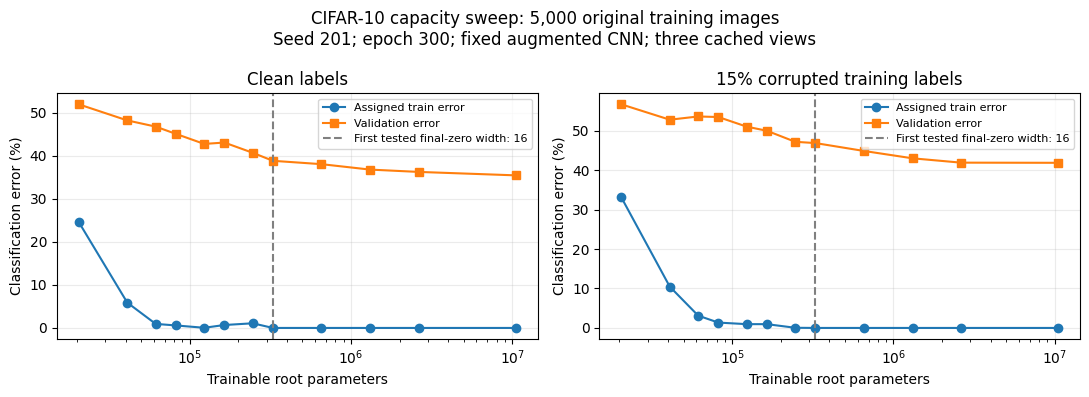

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, condition, title in [
    (axes[0], "clean", "Clean labels"),
    (axes[1], "noise15", "15% corrupted training labels")
]:
    data = sorted(
        [r for r in results if r["condition"] == condition],
        key=lambda r: int(r["width"])
    )

    parameters = [int(r["head_parameters"]) for r in data]

    train_error = [
        100 * int(r["assigned_errors_original_inputs"]) / 5000
        for r in data
    ]
    validation_error = [
        100 - float(r["validation_accuracy"])
        for r in data
    ]

    ax.plot(parameters, train_error, "o-", label="Assigned train error")
    ax.plot(parameters, validation_error, "s-", label="Validation error")

    # Final-epoch interpolation on ALL cached training views.
    interpolating = [
        r for r in data
        if int(r["assigned_errors_all_cached_views"]) == 0
    ]

    if interpolating:
        boundary = interpolating[0]
        ax.axvline(
            int(boundary["head_parameters"]),
            color="gray", linestyle="--",
            label=f"First tested final-zero width: {boundary['width']}"
        )

    ax.set_xscale("log")
    ax.set(
        title=title,
        xlabel="Trainable root parameters",
        ylabel="Classification error (%)"
    )
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "CIFAR-10 capacity sweep: 5,000 original training images\n"
    "Seed 201; epoch 300; fixed augmented CNN; three cached views"
)
fig.tight_layout()

fig.savefig(dd_folder / "capacity_sweep_seed201.pdf",
            bbox_inches="tight")
fig.savefig(dd_folder / "capacity_sweep_seed201.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [25]:
for condition in ["clean", "noise15"]:
    print(f"\n{condition.upper()}")
    print("Width | BCE at 200 → 300 | Original-input errors at 300")

    for width in dd_widths:
        saved = torch.load(
            dd_folder / f"{condition}_width{width}_seed201.pt",
            map_location="cpu",
            weights_only=False
        )

        history = saved["history"]
        earlier = next(r for r in history if r["epoch"] == 200)
        final = history[-1]

        print(
            f"{width:5d} | "
            f"{earlier['mean_cached_view_weighted_BCE']:.5f} → "
            f"{final['mean_cached_view_weighted_BCE']:.5f} | "
            f"{final['assigned_errors_original_inputs']}"
        )


CLEAN
Width | BCE at 200 → 300 | Original-input errors at 300
    1 | 0.38602 → 0.33133 | 1230
    2 | 0.18253 → 0.15034 | 294
    3 | 0.11894 → 0.08689 | 47
    4 | 0.05202 → 0.04609 | 29
    6 | 0.01593 → 0.01118 | 2
    8 | 0.00680 → 0.03075 | 34
   12 | 0.00242 → 0.04100 | 54
   16 | 0.00160 → 0.00396 | 0
   32 | 0.00043 → 0.00011 | 0
   64 | 0.00022 → 0.00006 | 0
  128 | 0.00013 → 0.00003 | 0
  512 | 0.00006 → 0.00002 | 0

NOISE15
Width | BCE at 200 → 300 | Original-input errors at 300
    1 | 0.52694 → 0.48086 | 1656
    2 | 0.29259 → 0.23952 | 523
    3 | 0.20531 → 0.15141 | 156
    4 | 0.08456 → 0.07122 | 68
    6 | 0.03125 → 0.07552 | 48
    8 | 0.01495 → 0.05450 | 48
   12 | 0.00694 → 0.00908 | 2
   16 | 0.00376 → 0.00256 | 0
   32 | 0.00089 → 0.00033 | 0
   64 | 0.00035 → 0.00009 | 0
  128 | 0.00020 → 0.00005 | 0
  512 | 0.00010 → 0.00003 | 0


In [26]:
dd_stable_results = []

for condition, assigned_labels in [
    ("clean", dd_clean_labels),
    ("noise15", dd_noisy_labels)
]:
    targets = F.one_hot(assigned_labels, num_classes=10).float()
    positives = targets.sum(0)
    weights = (len(targets) - positives) / positives

    for width in dd_widths:
        original_path = dd_folder / (
            f"{condition}_width{width}_seed201.pt"
        )
        stable_path = dd_folder / (
            f"{condition}_width{width}_seed201_stabilized.pt"
        )

        source_path = (
            stable_path if stable_path.exists() else original_path
        )
        saved = torch.load(
            source_path, map_location="cpu", weights_only=False
        )

        if saved["epoch"] >= 600:
            dd_stable_results.append(saved["history"][-1])
            print(f"Already completed: {condition}, width {width}")
            continue

        network = AssignmentRoots(dd_mean, dd_std, width).to(device)
        network.load_state_dict(saved["state"])

        optimizer = torch.optim.Adam(network.parameters(), lr=0.0001)
        optimizer.load_state_dict(saved["optimizer_state"])

        for parameter, state in optimizer.state.items():
            for name, value in state.items():
                if isinstance(value, torch.Tensor) and name != "step":
                    state[name] = value.to(parameter.device)

        for group in optimizer.param_groups:
            group["lr"] = 0.0001

        criterion = nn.BCEWithLogitsLoss(
            pos_weight=weights.to(device)
        )
        evaluation_loss = nn.BCEWithLogitsLoss(pos_weight=weights)

        order_rng = torch.Generator()
        order_rng.set_state(saved["loader_rng"])
        view_rng = torch.Generator()
        view_rng.set_state(saved["view_rng"])

        loader = DataLoader(
            TensorDataset(torch.arange(len(assigned_labels))),
            batch_size=256, shuffle=True, num_workers=0,
            generator=order_rng
        )

        history = saved["history"].copy()
        print(f"\n{condition.upper()} | width {width}", flush=True)

        for epoch in range(saved["epoch"] + 1, 601):
            network.train()
            online_sum = 0.0
            count = 0

            for (indices,) in loader:
                view = int(torch.randint(
                    len(dd_views), (1,), generator=view_rng
                ).item())

                optimizer.zero_grad(set_to_none=True)
                loss = criterion(
                    network(dd_views[view][indices].to(device)),
                    targets[indices].to(device)
                )
                loss.backward()
                optimizer.step()

                online_sum += loss.item() * len(indices)
                count += len(indices)

            if epoch % 25 == 0:
                scores_by_view = [
                    dd_scores(network, features)
                    for features in dd_views
                ]
                original_predictions = scores_by_view[0].argmax(1)
                validation_scores = dd_scores(
                    network, dd_validation_features
                )

                row = {
                    "condition": condition,
                    "seed": 201,
                    "width": width,
                    "epoch": epoch,
                    "head_parameters": sum(
                        p.numel() for p in network.parameters()
                    ),
                    "assigned_errors_original_inputs": int((
                        original_predictions != assigned_labels
                    ).sum().item()),
                    "original_label_errors_original_inputs": int((
                        original_predictions != dd_clean_labels
                    ).sum().item()),
                    "assigned_errors_all_cached_views": sum(
                        int((scores.argmax(1) != assigned_labels)
                            .sum().item())
                        for scores in scores_by_view
                    ),
                    "cached_view_count": len(dd_views),
                    "online_weighted_BCE": online_sum / count,
                    "mean_cached_view_weighted_BCE": sum(
                        evaluation_loss(scores, targets).item()
                        for scores in scores_by_view
                    ) / len(scores_by_view),
                    "validation_errors": int((
                        validation_scores.argmax(1)
                        != dd_validation_labels
                    ).sum().item()),
                    "validation_accuracy": 100 * (
                        validation_scores.argmax(1)
                        == dd_validation_labels
                    ).double().mean().item(),
                    "validation_cross_entropy": F.cross_entropy(
                        validation_scores, dd_validation_labels
                    ).item()
                }
                history.append(row)

                torch.save({
                    "state": {
                        name: value.detach().cpu().clone()
                        for name, value in network.state_dict().items()
                    },
                    "optimizer_state": optimizer.state_dict(),
                    "loader_rng": order_rng.get_state(),
                    "view_rng": view_rng.get_state(),
                    "epoch": epoch,
                    "learning_rate": 0.0001,
                    "history": history,
                    "protocol": "300 epochs at .001; 300 at .0001"
                }, stable_path)

                if epoch % 100 == 0:
                    print(
                        f"Epoch {epoch}: "
                        f"train errors={row['assigned_errors_original_inputs']} "
                        f"| all-view={row['assigned_errors_all_cached_views']} "
                        f"| BCE={row['mean_cached_view_weighted_BCE']:.5f} "
                        f"| val={row['validation_accuracy']:.2f}%",
                        flush=True
                    )

        dd_stable_results.append(history[-1])
        network.cpu()

with (dd_folder / "capacity_stabilized_seed201.csv").open(
    "w", newline=""
) as file:
    writer = csv.DictWriter(
        file, fieldnames=dd_stable_results[0].keys()
    )
    writer.writeheader()
    writer.writerows(dd_stable_results)

print("\nSaved: capacity_stabilized_seed201.csv")


CLEAN | width 1
Epoch 400: train errors=1156 | all-view=2802 | BCE=0.30947 | val=48.24%
Epoch 500: train errors=1115 | all-view=2652 | BCE=0.30263 | val=48.10%
Epoch 600: train errors=1089 | all-view=2606 | BCE=0.29650 | val=48.28%

CLEAN | width 2
Epoch 400: train errors=258 | all-view=629 | BCE=0.12429 | val=52.26%
Epoch 500: train errors=240 | all-view=591 | BCE=0.12002 | val=52.22%
Epoch 600: train errors=231 | all-view=567 | BCE=0.11606 | val=52.02%

CLEAN | width 3
Epoch 400: train errors=35 | all-view=142 | BCE=0.06662 | val=53.68%
Epoch 500: train errors=35 | all-view=135 | BCE=0.06273 | val=53.68%
Epoch 600: train errors=31 | all-view=123 | BCE=0.05971 | val=53.42%

CLEAN | width 4
Epoch 400: train errors=13 | all-view=25 | BCE=0.02668 | val=54.96%
Epoch 500: train errors=10 | all-view=19 | BCE=0.02546 | val=54.84%
Epoch 600: train errors=10 | all-view=19 | BCE=0.02454 | val=54.74%

CLEAN | width 6
Epoch 400: train errors=2 | all-view=5 | BCE=0.00961 | val=57.36%
Epoch 500: t

## Double-Descent Capacity Sweep: Three-Seed Repeats with a Two-Stage Learning Rate

In [27]:
dd_repeat_results = []

for repeat_seed in [202, 203]:
    for condition, assigned_labels in [
        ("clean", dd_clean_labels),
        ("noise15", dd_noisy_labels)
    ]:
        targets = F.one_hot(
            assigned_labels, num_classes=10
        ).float()

        positives = targets.sum(0)
        weights = (len(targets) - positives) / positives

        for width in dd_widths:
            path = dd_folder / (
                f"{condition}_width{width}"
                f"_seed{repeat_seed}_twostage.pt"
            )

            saved = (
                torch.load(path, map_location="cpu", weights_only=False)
                if path.exists() else None
            )

            if saved is not None and saved["epoch"] >= 600:
                dd_repeat_results.append(saved["history"][-1])
                print(
                    f"Already completed: seed {repeat_seed}, "
                    f"{condition}, width {width}",
                    flush=True
                )
                continue

            torch.manual_seed(repeat_seed)

            network = AssignmentRoots(
                dd_mean, dd_std, width
            ).to(device)

            optimizer = torch.optim.Adam(
                network.parameters(), lr=0.001
            )

            order_rng = torch.Generator().manual_seed(repeat_seed)
            view_rng = torch.Generator().manual_seed(
                repeat_seed + 10000
            )

            history = []
            starting_epoch = 0

            if saved is not None:
                network.load_state_dict(saved["state"])
                optimizer.load_state_dict(saved["optimizer_state"])

                for parameter, state in optimizer.state.items():
                    for name, value in state.items():
                        if (
                            isinstance(value, torch.Tensor)
                            and name != "step"
                        ):
                            state[name] = value.to(parameter.device)

                order_rng.set_state(saved["loader_rng"])
                view_rng.set_state(saved["view_rng"])
                history = saved["history"]
                starting_epoch = saved["epoch"]

            loader = DataLoader(
                TensorDataset(torch.arange(len(assigned_labels))),
                batch_size=256,
                shuffle=True,
                num_workers=0,
                generator=order_rng
            )

            criterion = nn.BCEWithLogitsLoss(
                pos_weight=weights.to(device)
            )
            evaluation_loss = nn.BCEWithLogitsLoss(
                pos_weight=weights
            )

            print(
                f"\nSEED {repeat_seed} | {condition.upper()} "
                f"| width {width} | resume at {starting_epoch}",
                flush=True
            )

            run_start = time.perf_counter()

            for epoch in range(starting_epoch + 1, 601):
                learning_rate = 0.001 if epoch <= 300 else 0.0001
                for group in optimizer.param_groups:
                    group["lr"] = learning_rate

                network.train()
                online_sum = 0.0
                sample_count = 0

                for (indices,) in loader:
                    view = int(torch.randint(
                        len(dd_views), (1,), generator=view_rng
                    ).item())

                    optimizer.zero_grad(set_to_none=True)
                    loss = criterion(
                        network(dd_views[view][indices].to(device)),
                        targets[indices].to(device)
                    )
                    loss.backward()
                    optimizer.step()

                    online_sum += loss.item() * len(indices)
                    sample_count += len(indices)

                if epoch % 25 == 0:
                    view_scores = [
                        dd_scores(network, features)
                        for features in dd_views
                    ]
                    original_predictions = view_scores[0].argmax(1)

                    val_scores = dd_scores(
                        network, dd_validation_features
                    )
                    val_errors = int((
                        val_scores.argmax(1) != dd_validation_labels
                    ).sum().item())

                    row = {
                        "condition": condition,
                        "seed": repeat_seed,
                        "width": width,
                        "epoch": epoch,
                        "learning_rate": learning_rate,
                        "head_parameters": sum(
                            p.numel() for p in network.parameters()
                        ),
                        "assigned_errors_original_inputs": int((
                            original_predictions != assigned_labels
                        ).sum().item()),
                        "original_label_errors_original_inputs": int((
                            original_predictions != dd_clean_labels
                        ).sum().item()),
                        "assigned_errors_all_cached_views": sum(
                            int((scores.argmax(1) != assigned_labels)
                                .sum().item())
                            for scores in view_scores
                        ),
                        "cached_view_count": len(dd_views),
                        "online_weighted_BCE": (
                            online_sum / sample_count
                        ),
                        "mean_cached_view_weighted_BCE": sum(
                            evaluation_loss(scores, targets).item()
                            for scores in view_scores
                        ) / len(view_scores),
                        "validation_errors": val_errors,
                        "validation_accuracy": 100 * (
                            1 - val_errors / len(dd_validation_labels)
                        ),
                        "validation_cross_entropy": F.cross_entropy(
                            val_scores, dd_validation_labels
                        ).item()
                    }
                    history.append(row)

                    torch.save({
                        "state": {
                            name: value.detach().cpu().clone()
                            for name, value in network.state_dict().items()
                        },
                        "optimizer_state": optimizer.state_dict(),
                        "loader_rng": order_rng.get_state(),
                        "view_rng": view_rng.get_state(),
                        "epoch": epoch,
                        "history": history,
                        "protocol": "300 epochs .001; 300 epochs .0001"
                    }, path)

                    if epoch % 100 == 0:
                        print(
                            f"Epoch {epoch}: "
                            f"train errors="
                            f"{row['assigned_errors_original_inputs']} "
                            f"| all-view="
                            f"{row['assigned_errors_all_cached_views']} "
                            f"| validation="
                            f"{row['validation_accuracy']:.2f}%",
                            flush=True
                        )

            dd_repeat_results.append(history[-1])

            # Update summary after every completed model.
            summary_rows = [
                {
                    **row,
                    "learning_rate": row.get("learning_rate", 0.0001)
                }
                for row in dd_stable_results
            ] + dd_repeat_results

            with (
                dd_folder / "capacity_twostage_all_seeds.csv"
            ).open("w", newline="") as file:
                writer = csv.DictWriter(
                    file, fieldnames=summary_rows[0].keys()
                )
                writer.writeheader()
                writer.writerows(summary_rows)

            network.cpu()

            print(
                f"Saved | time={time.perf_counter() - run_start:.1f}s",
                flush=True
            )

print("\nCompleted seeds 202 and 203.")
print("Saved: capacity_twostage_all_seeds.csv")


SEED 202 | CLEAN | width 1 | resume at 0
Epoch 100: train errors=1714 | all-view=4636 | validation=46.38%
Epoch 200: train errors=1386 | all-view=3542 | validation=47.62%
Epoch 300: train errors=1156 | all-view=2905 | validation=48.30%
Epoch 400: train errors=1092 | all-view=2632 | validation=48.44%
Epoch 500: train errors=1053 | all-view=2547 | validation=48.28%
Epoch 600: train errors=1013 | all-view=2515 | validation=48.72%
Saved | time=88.1s

SEED 202 | CLEAN | width 2 | resume at 0
Epoch 100: train errors=563 | all-view=1882 | validation=57.22%
Epoch 200: train errors=320 | all-view=975 | validation=54.64%
Epoch 300: train errors=241 | all-view=718 | validation=53.72%
Epoch 400: train errors=198 | all-view=569 | validation=53.00%
Epoch 500: train errors=181 | all-view=544 | validation=52.98%
Epoch 600: train errors=167 | all-view=514 | validation=52.54%
Saved | time=89.8s

SEED 202 | CLEAN | width 3 | resume at 0
Epoch 100: train errors=317 | all-view=1069 | validation=55.64%
Epo

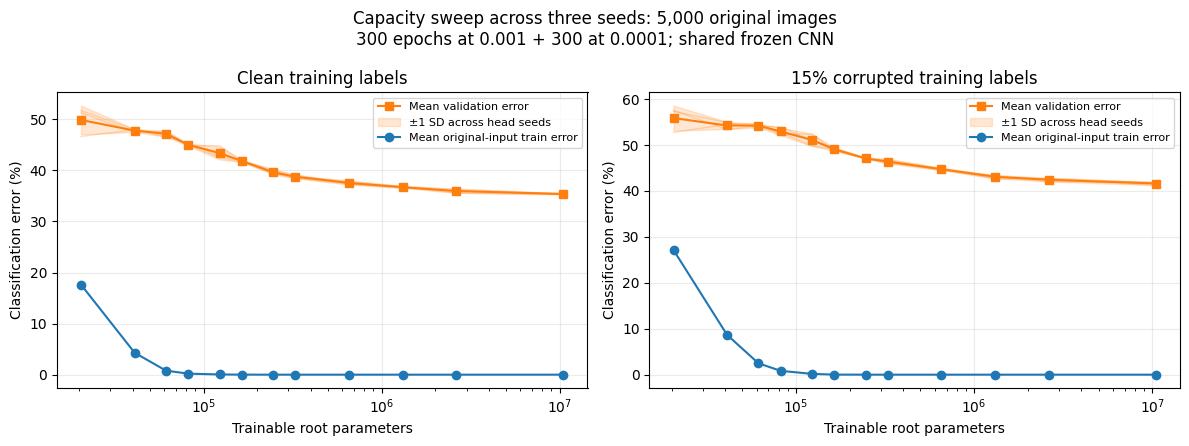

Saved: capacity_three_seeds.pdf and PNG


In [28]:
import csv
import numpy as np
import matplotlib.pyplot as plt

with (dd_folder / "capacity_twostage_all_seeds.csv").open() as file:
    dd_summary = list(csv.DictReader(file))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, condition, title in [
    (axes[0], "clean", "Clean training labels"),
    (axes[1], "noise15", "15% corrupted training labels")
]:
    parameters = []
    validation_errors = []
    train_errors = []

    for width in dd_widths:
        rows = [
            r for r in dd_summary
            if r["condition"] == condition
            and int(r["width"]) == width
        ]

        assert len(rows) == 3
        assert {int(r["seed"]) for r in rows} == {201, 202, 203}
        assert all(int(r["epoch"]) == 600 for r in rows)

        rows.sort(key=lambda r: int(r["seed"]))

        parameters.append(int(rows[0]["head_parameters"]))
        validation_errors.append([
            100 - float(r["validation_accuracy"]) for r in rows
        ])
        train_errors.append([
            100 * int(r["assigned_errors_original_inputs"]) / 5000
            for r in rows
        ])

    validation_errors = np.array(validation_errors)
    train_errors = np.array(train_errors)

    # Show each seed as well as mean ± sample standard deviation.
    for column in range(3):
        ax.plot(
            parameters, validation_errors[:, column],
            color="tab:orange", alpha=0.25, linewidth=1
        )

    mean_error = validation_errors.mean(axis=1)
    std_error = validation_errors.std(axis=1, ddof=1)

    ax.plot(
        parameters, mean_error, "s-",
        color="tab:orange", label="Mean validation error"
    )
    ax.fill_between(
        parameters,
        mean_error - std_error,
        mean_error + std_error,
        color="tab:orange", alpha=0.18,
        label="±1 SD across head seeds"
    )
    ax.plot(
        parameters, train_errors.mean(axis=1), "o-",
        color="tab:blue", label="Mean original-input train error"
    )

    ax.set_xscale("log")
    ax.set(
        title=title,
        xlabel="Trainable root parameters",
        ylabel="Classification error (%)"
    )
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Capacity sweep across three seeds: 5,000 original images\n"
    "300 epochs at 0.001 + 300 at 0.0001; shared frozen CNN"
)
fig.tight_layout()

fig.savefig(
    dd_folder / "capacity_three_seeds.pdf",
    bbox_inches="tight"
)
fig.savefig(
    dd_folder / "capacity_three_seeds.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Saved: capacity_three_seeds.pdf and PNG")

## Cats vs Dogs: Augmentation and Neural-Tree Ensembles

In [30]:
from pathlib import Path
import torch

cd_home = Path.home()
cd_images_folder = cd_home / "data/cats_vs_dogs/PetImages"
cd_output_folder = cd_home / "catsdogs_augmentation_ensemble"
cd_output_folder.mkdir(exist_ok=True)

print("Images folder exists:", cd_images_folder.is_dir())

print("\nSplit manifests:")
for path in [
    cd_home / "catsdogs_clean_split_manifest.csv",
    cd_images_folder.parent / "split_manifest.csv"
]:
    print(path, "→", path.is_file())

print("\nSaved Cats vs Dogs models:")
for path in sorted(cd_home.glob("catsdogs*.pt")):
    print(path.name)

cd_checkpoint_path = cd_home / "catsdogs_compact_tree.pt"

if cd_checkpoint_path.is_file():
    cd_checkpoint = torch.load(
        cd_checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nCompact-tree checkpoint keys:")
    print(list(cd_checkpoint.keys()))

    for key, value in cd_checkpoint.items():
        if isinstance(value, dict):
            tensors = [
                (name, tuple(item.shape))
                for name, item in value.items()
                if isinstance(item, torch.Tensor)
            ]
            if tensors:
                print(f"\n{key}:")
                for name, shape in tensors[:4]:
                    print(" ", name, "→", shape)

print("\nNew outputs:", cd_output_folder)

Images folder exists: True

Split manifests:
/Users/aroma/catsdogs_clean_split_manifest.csv → True
/Users/aroma/data/cats_vs_dogs/split_manifest.csv → True

Saved Cats vs Dogs models:
catsdogs_adaptive_comparison_seed43.pt
catsdogs_adaptive_comparison_seed44.pt
catsdogs_cached_features.pt
catsdogs_clean_validation_features.pt
catsdogs_compact_tree.pt
catsdogs_downward_child.pt
catsdogs_feature_root.pt
catsdogs_innovation_childB_seed42.pt
catsdogs_innovation_root_width16_seed42.pt
catsdogs_innovation_root_width8_seed42.pt
catsdogs_root_checkpoint.pt
catsdogs_small_child_B.pt
catsdogs_small_root.pt

Compact-tree checkpoint keys:
['trunk_state', 'root_state', 'child_B_state', 'root_hidden_width', 'child_hidden_width', 'feature_mean', 'feature_std', 'correction_strength', 'child_threshold', 'image_size', 'class_names', 'parameter_count', 'train_results', 'validation_results', 'score_arithmetic']

trunk_state:
  layers.0.weight → (16, 3, 3, 3)
  layers.0.bias → (16,)
  layers.3.weight → (32

In [31]:
import csv
import copy
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

cd_device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Read the saved split without generating a new one.
cd_manifest_path = cd_home / "catsdogs_clean_split_manifest.csv"

cd_samples = {
    "train": [],
    "validation": [],
    "test": []
}

with cd_manifest_path.open(newline="") as file:
    for row in csv.DictReader(file):
        split = row["split"]
        path = cd_images_folder / row["relative_path"]
        label = int(row["label"])

        if not path.is_file():
            raise FileNotFoundError(path)

        cd_samples[split].append((path, label))

cd_path_sets = {
    split: {str(path) for path, _ in samples}
    for split, samples in cd_samples.items()
}

assert cd_path_sets["train"].isdisjoint(cd_path_sets["validation"])
assert cd_path_sets["train"].isdisjoint(cd_path_sets["test"])
assert cd_path_sets["validation"].isdisjoint(cd_path_sets["test"])


class CDAssignmentDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        with Image.open(path) as image:
            image = self.transform(image.convert("RGB"))

        return image, label


cd_clean_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

cd_augmented_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

cd_clean_train_dataset = CDAssignmentDataset(
    cd_samples["train"], cd_clean_transform
)
cd_augmented_train_dataset = CDAssignmentDataset(
    cd_samples["train"], cd_augmented_transform
)
cd_validation_dataset = CDAssignmentDataset(
    cd_samples["validation"], cd_clean_transform
)

# Leave test evaluation until the model choices are fixed.
cd_clean_train_loader = DataLoader(
    cd_clean_train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

cd_validation_loader = DataLoader(
    cd_validation_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)


class CDTrunk(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten()
        )

    def forward(self, images):
        return self.layers(images)


cd_original_trunk = CDTrunk().to(cd_device)
cd_original_trunk.load_state_dict(
    cd_checkpoint["trunk_state"], strict=True
)
cd_original_trunk.eval()

for split, samples in cd_samples.items():
    cats = sum(label == 0 for _, label in samples)
    dogs = sum(label == 1 for _, label in samples)

    print(
        f"{split.upper()}: {len(samples)} "
        f"| cats={cats} | dogs={dogs}"
    )

sample_images, sample_labels = next(iter(cd_clean_train_loader))

with torch.no_grad():
    sample_features = cd_original_trunk(
        sample_images.to(cd_device)
    )

print("\nDevice:", cd_device)
print("Images:", sample_images.shape)
print("Features:", sample_features.shape)
print("Labels: Cat=0, Dog=1")

# Preserve the exact manifest used by this experiment.
import shutil
shutil.copyfile(
    cd_manifest_path,
    cd_output_folder / "split_manifest.csv"
)

print("Saved split manifest in the new experiment folder.")

TRAIN: 19998 | cats=9999 | dogs=9999
VALIDATION: 2494 | cats=1246 | dogs=1248
TEST: 2496 | cats=1245 | dogs=1251

Device: mps
Images: torch.Size([256, 3, 32, 32])
Features: torch.Size([256, 2048])
Labels: Cat=0, Dog=1
Saved split manifest in the new experiment folder.


In [32]:
import time
import csv
import copy

class CDFeatureModel(nn.Module):
    def __init__(self, trunk):
        super().__init__()
        self.trunk = trunk
        self.head = nn.Sequential(
            nn.Linear(2048, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, images):
        return self.head(self.trunk(images)).squeeze(-1)


@torch.no_grad()
def cd_evaluate_images(network, loader):
    network.eval()
    loss_sum = 0.0
    errors = 0
    total = 0

    for images, labels in loader:
        targets = labels.to(cd_device).float()
        scores = network(images.to(cd_device))

        loss_sum += nn.functional.binary_cross_entropy_with_logits(
            scores, targets, reduction="sum"
        ).item()

        errors += (
            (scores >= 0) != targets.bool()
        ).sum().item()

        total += len(labels)

    return {
        "loss": loss_sum / total,
        "accuracy": 100 * (1 - errors / total),
        "errors": errors
    }


torch.manual_seed(123)

cd_starting_model = CDFeatureModel(
    copy.deepcopy(cd_original_trunk)
).cpu()

cd_feature_models = {}
cd_feature_history = []

for condition, dataset in [
    ("clean", cd_clean_train_dataset),
    ("augmented", cd_augmented_train_dataset)
]:
    torch.manual_seed(123)

    network = copy.deepcopy(cd_starting_model).to(cd_device)
    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(123)
    )

    print(f"\nCATS VS DOGS: {condition.upper()}", flush=True)

    for epoch in range(1, 21):
        start = time.perf_counter()

        if epoch == 16:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()

        for images, labels in loader:
            images = images.to(cd_device)
            targets = labels.to(cd_device).float()

            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.binary_cross_entropy_with_logits(
                network(images), targets
            )
            loss.backward()
            optimizer.step()

        train_result = cd_evaluate_images(
            network, cd_clean_train_loader
        )
        val_result = cd_evaluate_images(
            network, cd_validation_loader
        )

        row = {
            "condition": condition,
            "epoch": epoch,
            "clean_train_loss": train_result["loss"],
            "clean_train_accuracy": train_result["accuracy"],
            "clean_train_errors": train_result["errors"],
            "validation_loss": val_result["loss"],
            "validation_accuracy": val_result["accuracy"],
            "validation_errors": val_result["errors"]
        }
        cd_feature_history.append(row)

        torch.save({
            "trunk_state": {
                name: value.detach().cpu().clone()
                for name, value in network.trunk.state_dict().items()
            },
            "head_state": {
                name: value.detach().cpu().clone()
                for name, value in network.head.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "epoch": epoch,
            "condition": condition,
            "history": [
                r for r in cd_feature_history
                if r["condition"] == condition
            ]
        }, cd_output_folder / f"feature_model_{condition}.pt")

        with (
            cd_output_folder / "feature_training_history.csv"
        ).open("w", newline="") as file:
            writer = csv.DictWriter(
                file, fieldnames=cd_feature_history[0].keys()
            )
            writer.writeheader()
            writer.writerows(cd_feature_history)

        print(
            f"Epoch {epoch}: "
            f"clean train={train_result['accuracy']:.2f}% "
            f"| validation={val_result['accuracy']:.2f}% "
            f"| time={time.perf_counter() - start:.1f}s",
            flush=True
        )

    cd_feature_models[condition] = network

print("\nBoth Cats vs Dogs feature models saved.")


CATS VS DOGS: CLEAN


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/PIL/TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 1: clean train=80.80% | validation=78.19% | time=30.2s
Epoch 2: clean train=82.52% | validation=78.67% | time=30.0s
Epoch 3: clean train=81.93% | validation=78.43% | time=28.8s
Epoch 4: clean train=82.62% | validation=78.63% | time=29.2s
Epoch 5: clean train=85.53% | validation=80.19% | time=28.7s
Epoch 6: clean train=84.88% | validation=78.87% | time=29.0s
Epoch 7: clean train=86.86% | validation=79.47% | time=29.0s
Epoch 8: clean train=82.49% | validation=76.54% | time=28.8s
Epoch 9: clean train=87.07% | validation=80.83% | time=29.1s
Epoch 10: clean train=87.65% | validation=80.19% | time=29.1s
Epoch 11: clean train=87.77% | validation=80.07% | time=28.9s
Epoch 12: clean train=89.05% | validation=80.43% | time=30.5s
Epoch 13: clean train=89.54% | validation=79.79% | time=29.9s
Epoch 14: clean train=87.97% | validation=79.19% | time=30.1s
Epoch 15: clean train=90.38% | validation=79.91% | time=29.8s
Epoch 16: clean train=91.26% | validation=80.03% | time=29.9s
Epoch 17: clean t

In [33]:
cd_feature_cache = {}


@torch.no_grad()
def cd_extract_features(trunk, dataset):
    trunk.eval()

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0
    )

    features_list = []
    labels_list = []

    for images, labels in loader:
        features_list.append(
            trunk(images.to(cd_device)).cpu()
        )
        labels_list.append(labels.cpu())

    return torch.cat(features_list), torch.cat(labels_list)


for condition in ["clean", "augmented"]:
    trunk = cd_feature_models[condition].trunk

    # Freeze the trained feature extractor.
    trunk.eval()
    for parameter in trunk.parameters():
        parameter.requires_grad_(False)

    print(f"\nCACHING: {condition.upper()}", flush=True)

    train_features, train_labels = cd_extract_features(
        trunk, cd_clean_train_dataset
    )

    validation_features, validation_labels = cd_extract_features(
        trunk, cd_validation_dataset
    )

    feature_mean = train_features.mean(0)
    feature_std = train_features.std(0).clamp_min(1e-6)

    condition_cache = {
        "train_features": train_features,
        "train_labels": train_labels.long(),
        "validation_features": validation_features,
        "validation_labels": validation_labels.long(),
        "feature_mean": feature_mean,
        "feature_std": feature_std,
        "augmented_views": []
    }

    if condition == "augmented":
        for view_number in range(2):
            torch.manual_seed(1000 + view_number)

            view_features, view_labels = cd_extract_features(
                trunk, cd_augmented_train_dataset
            )

            assert torch.equal(view_labels, train_labels)

            condition_cache["augmented_views"].append(
                view_features
            )

            print(
                f"Augmented view {view_number + 1}:",
                tuple(view_features.shape),
                flush=True
            )

    cd_feature_cache[condition] = condition_cache

    torch.save(
        condition_cache,
        cd_output_folder / f"features_{condition}.pt"
    )

    print(
        f"Original training features: {tuple(train_features.shape)}\n"
        f"Validation features: {tuple(validation_features.shape)}",
        flush=True
    )

print("\nBoth feature caches saved.")


CACHING: CLEAN
Original training features: (19998, 2048)
Validation features: (2494, 2048)

CACHING: AUGMENTED
Augmented view 1: (19998, 2048)
Augmented view 2: (19998, 2048)
Original training features: (19998, 2048)
Validation features: (2494, 2048)

Both feature caches saved.


In [34]:
from torch.utils.data import TensorDataset

class CDRoot(nn.Module):
    def __init__(self, mean, std, width=128):
        super().__init__()
        self.register_buffer("feature_mean", mean.clone())
        self.register_buffer("feature_std", std.clone())

        self.layers = nn.Sequential(
            nn.Linear(2048, width),
            nn.ReLU(),
            nn.Linear(width, 1)
        )

    def forward(self, features):
        standardized = (
            features - self.feature_mean
        ) / self.feature_std

        return self.layers(standardized).squeeze(-1)


@torch.no_grad()
def cd_root_scores(network, features):
    network.eval()
    return torch.cat([
        network(batch.to(cd_device)).cpu()
        for batch in features.split(512)
    ])


def cd_score_metrics(scores, labels):
    actual = labels.bool()
    predicted = scores >= 0

    missed_dogs = int(((~predicted) & actual).sum().item())
    false_dogs = int((predicted & (~actual)).sum().item())
    errors = missed_dogs + false_dogs

    return {
        "accuracy": 100 * (1 - errors / len(labels)),
        "errors": errors,
        "missed_dogs": missed_dogs,
        "false_dogs": false_dogs,
        "BCE": nn.functional.binary_cross_entropy_with_logits(
            scores, labels.float()
        ).item()
    }


cd_roots = {}
cd_root_history = []
cd_root_epochs_to_save = {1, 5, 10, 20, 40, 60, 80, 100}

for condition in ["clean", "augmented"]:
    condition_cache = cd_feature_cache[condition]
    labels = condition_cache["train_labels"]

    views = [
        condition_cache["train_features"],
        *condition_cache["augmented_views"]
    ]

    torch.manual_seed(42)

    network = CDRoot(
        condition_cache["feature_mean"],
        condition_cache["feature_std"],
        width=128
    ).to(cd_device)

    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

    loader = DataLoader(
        TensorDataset(torch.arange(len(labels))),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    view_rng = torch.Generator().manual_seed(2026)

    print(f"\nCATS VS DOGS ROOT: {condition.upper()}", flush=True)

    for epoch in range(1, 101):
        if epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()

        for (indices,) in loader:
            view_index = (
                int(torch.randint(
                    len(views), (1,), generator=view_rng
                ).item())
                if len(views) > 1 else 0
            )

            optimizer.zero_grad(set_to_none=True)

            scores = network(
                views[view_index][indices].to(cd_device)
            )
            loss = nn.functional.binary_cross_entropy_with_logits(
                scores, labels[indices].float().to(cd_device)
            )

            loss.backward()
            optimizer.step()

        if epoch in cd_root_epochs_to_save:
            train_scores = cd_root_scores(
                network, condition_cache["train_features"]
            )
            val_scores = cd_root_scores(
                network, condition_cache["validation_features"]
            )

            train_result = cd_score_metrics(train_scores, labels)
            val_result = cd_score_metrics(
                val_scores, condition_cache["validation_labels"]
            )

            row = {
                "condition": condition,
                "epoch": epoch,
                "train_accuracy": train_result["accuracy"],
                "train_errors": train_result["errors"],
                "train_BCE": train_result["BCE"],
                "validation_accuracy": val_result["accuracy"],
                "validation_errors": val_result["errors"],
                "validation_BCE": val_result["BCE"]
            }
            cd_root_history.append(row)

            torch.save({
                "state": {
                    name: value.detach().cpu().clone()
                    for name, value in network.state_dict().items()
                },
                "optimizer_state": optimizer.state_dict(),
                "width": 128,
                "condition": condition,
                "seed": 42,
                "epoch": epoch,
                "validation_scores": val_scores,
                "metrics": row
            }, cd_output_folder / (
                f"root_{condition}_seed42_epoch{epoch}.pt"
            ))

            with (
                cd_output_folder / "root_training_history.csv"
            ).open("w", newline="") as file:
                writer = csv.DictWriter(
                    file, fieldnames=cd_root_history[0].keys()
                )
                writer.writeheader()
                writer.writerows(cd_root_history)

            print(
                f"Epoch {epoch}: "
                f"clean train={train_result['accuracy']:.4f}% "
                f"| errors={train_result['errors']} "
                f"| missed dogs={train_result['missed_dogs']} "
                f"| false dogs={train_result['false_dogs']} "
                f"| validation={val_result['accuracy']:.2f}%",
                flush=True
            )

    cd_roots[condition] = network

print("\nClean and augmented roots saved.")


CATS VS DOGS ROOT: CLEAN
Epoch 1: clean train=89.6590% | errors=2068 | missed dogs=1106 | false dogs=962 | validation=80.87%
Epoch 5: clean train=98.8499% | errors=230 | missed dogs=137 | false dogs=93 | validation=80.15%
Epoch 10: clean train=99.9750% | errors=5 | missed dogs=2 | false dogs=3 | validation=80.31%
Epoch 20: clean train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=80.87%
Epoch 40: clean train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=80.91%
Epoch 60: clean train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=80.95%
Epoch 80: clean train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=80.95%
Epoch 100: clean train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=80.83%

CATS VS DOGS ROOT: AUGMENTED
Epoch 1: clean train=84.9885% | errors=3002 | missed dogs=1544 | false dogs=1458 | validation=82.08%
Epoch 5: clean train=89.4389% | errors=2112 | missed dogs=996 | false dogs=1116 | valid

In [35]:
cd_ensemble_seeds = [101, 102, 103, 104, 105]
cd_ensemble_history = []

cd_cache = cd_feature_cache["augmented"]
cd_labels = cd_cache["train_labels"]
cd_views = [
    cd_cache["train_features"],
    *cd_cache["augmented_views"]
]

for seed in cd_ensemble_seeds:
    torch.manual_seed(seed)

    sampled_ids = torch.randint(
        len(cd_labels),
        (len(cd_labels),),
        generator=torch.Generator().manual_seed(seed)
    )

    network = CDRoot(
        cd_cache["feature_mean"],
        cd_cache["feature_std"],
        width=128
    ).to(cd_device)

    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

    loader = DataLoader(
        TensorDataset(sampled_ids),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed)
    )

    view_rng = torch.Generator().manual_seed(seed + 10000)

    print(
        f"\nCATS VS DOGS MEMBER {seed} "
        f"| unique images={sampled_ids.unique().numel()}",
        flush=True
    )

    for epoch in range(1, 101):
        if epoch == 51:
            for group in optimizer.param_groups:
                group["lr"] = 0.0001

        network.train()

        for (indices,) in loader:
            view_index = int(torch.randint(
                len(cd_views), (1,), generator=view_rng
            ).item())

            optimizer.zero_grad(set_to_none=True)

            loss = nn.functional.binary_cross_entropy_with_logits(
                network(cd_views[view_index][indices].to(cd_device)),
                cd_labels[indices].float().to(cd_device)
            )
            loss.backward()
            optimizer.step()

        if epoch in cd_root_epochs_to_save:
            train_scores = cd_root_scores(
                network, cd_cache["train_features"]
            )
            val_scores = cd_root_scores(
                network, cd_cache["validation_features"]
            )

            sampled_result = cd_score_metrics(
                train_scores[sampled_ids],
                cd_labels[sampled_ids]
            )
            val_result = cd_score_metrics(
                val_scores, cd_cache["validation_labels"]
            )

            row = {
                "seed": seed,
                "epoch": epoch,
                "unique_images": sampled_ids.unique().numel(),
                "sampled_train_accuracy": sampled_result["accuracy"],
                "sampled_train_errors": sampled_result["errors"],
                "validation_accuracy": val_result["accuracy"],
                "validation_errors": val_result["errors"]
            }
            cd_ensemble_history.append(row)

            saved = {
                "seed": seed,
                "epoch": epoch,
                "width": 128,
                "sampled_ids": sampled_ids,
                "validation_scores": val_scores,
                "validation_predictions": (val_scores >= 0).long(),
                "metrics": row
            }

            if epoch == 100:
                saved["state"] = {
                    name: value.detach().cpu().clone()
                    for name, value in network.state_dict().items()
                }
                saved["all_train_scores"] = train_scores

            torch.save(
                saved,
                cd_output_folder / (
                    f"ensemble_seed{seed}_epoch{epoch}.pt"
                )
            )

            if epoch in [20, 60, 100]:
                print(
                    f"Epoch {epoch}: sampled train="
                    f"{sampled_result['accuracy']:.4f}% "
                    f"| errors={sampled_result['errors']} "
                    f"| validation={val_result['accuracy']:.2f}%",
                    flush=True
                )

    network.cpu()

with (
    cd_output_folder / "ensemble_training_history.csv"
).open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=cd_ensemble_history[0].keys()
    )
    writer.writeheader()
    writer.writerows(cd_ensemble_history)

print("\nFive Cats vs Dogs members saved.")


CATS VS DOGS MEMBER 101 | unique images=12674
Epoch 20: sampled train=99.7650% | errors=47 | validation=81.32%
Epoch 60: sampled train=99.9800% | errors=4 | validation=81.15%
Epoch 100: sampled train=99.9950% | errors=1 | validation=81.40%

CATS VS DOGS MEMBER 102 | unique images=12653
Epoch 20: sampled train=99.6250% | errors=75 | validation=80.91%
Epoch 60: sampled train=100.0000% | errors=0 | validation=80.59%
Epoch 100: sampled train=100.0000% | errors=0 | validation=80.67%

CATS VS DOGS MEMBER 103 | unique images=12633
Epoch 20: sampled train=99.5650% | errors=87 | validation=81.23%
Epoch 60: sampled train=99.9800% | errors=4 | validation=81.88%
Epoch 100: sampled train=99.9800% | errors=4 | validation=81.76%

CATS VS DOGS MEMBER 104 | unique images=12550
Epoch 20: sampled train=99.7150% | errors=57 | validation=80.55%
Epoch 60: sampled train=100.0000% | errors=0 | validation=81.15%
Epoch 100: sampled train=100.0000% | errors=0 | validation=81.11%

CATS VS DOGS MEMBER 105 | uniqu

In [36]:
import itertools

cd_val_labels = cd_feature_cache["augmented"][
    "validation_labels"
].long()


def cd_majority_vote(predictions):
    # Predictions: [models, images], with Cat=0 and Dog=1.
    dog_votes = predictions.sum(dim=0)
    return (dog_votes > predictions.shape[0] / 2).long()


# 1. Final-epoch voting for all groups of 1, 3 and 5 members.
cd_final_predictions = []

for seed in cd_ensemble_seeds:
    saved = torch.load(
        cd_output_folder / f"ensemble_seed{seed}_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )
    cd_final_predictions.append(saved["validation_predictions"])

cd_final_predictions = torch.stack(cd_final_predictions)
cd_vote_results = []

print("FINAL-EPOCH VALIDATION VOTING")

for size in [1, 3, 5]:
    accuracies = []

    for group in itertools.combinations(range(5), size):
        voted = cd_majority_vote(
            cd_final_predictions[list(group)]
        )
        errors = int((voted != cd_val_labels).sum().item())
        accuracy = 100 * (1 - errors / len(cd_val_labels))

        accuracies.append(accuracy)
        cd_vote_results.append({
            "members": [cd_ensemble_seeds[i] for i in group],
            "size": size,
            "accuracy": accuracy,
            "errors": errors
        })

    print(
        f"{size} member(s): "
        f"mean={sum(accuracies) / len(accuracies):.2f}% "
        f"| range={min(accuracies):.2f}%–{max(accuracies):.2f}%"
    )

disagreements = [
    (cd_final_predictions[a] != cd_final_predictions[b])
    .double().mean().item()
    for a, b in itertools.combinations(range(5), 2)
]

print(
    "Mean pairwise disagreement:",
    f"{100 * sum(disagreements) / len(disagreements):.2f}%"
)
print("Full-data augmented root validation: 81.80%")


# 2. Same empirical decomposition as CIFAR:
# mean member error = squared-bias proxy + prediction variance.
cd_bias_variance_history = []
cd_label_vectors = nn.functional.one_hot(
    cd_val_labels, num_classes=2
).double()

print("\nACROSS EPOCHS")

for epoch in sorted(cd_root_epochs_to_save):
    predictions = []

    for seed in cd_ensemble_seeds:
        saved = torch.load(
            cd_output_folder / f"ensemble_seed{seed}_epoch{epoch}.pt",
            map_location="cpu",
            weights_only=False
        )
        predictions.append(saved["validation_predictions"])

    predictions = torch.stack(predictions)
    vectors = nn.functional.one_hot(
        predictions.long(), num_classes=2
    ).double()

    mean_vector = vectors.mean(0)

    bias_proxy = (
        0.5 * (mean_vector - cd_label_vectors).square().sum(-1)
    ).mean().item()

    variance = (
        0.5 * (vectors - mean_vector.unsqueeze(0))
        .square().sum(-1)
    ).mean().item()

    member_error = (
        predictions != cd_val_labels.unsqueeze(0)
    ).double().mean().item()

    voted = cd_majority_vote(predictions)
    vote_accuracy = 100 * (
        voted == cd_val_labels
    ).double().mean().item()

    assert abs(member_error - bias_proxy - variance) < 1e-10

    row = {
        "epoch": epoch,
        "mean_member_error": member_error,
        "squared_bias_proxy": bias_proxy,
        "prediction_variance": variance,
        "vote_accuracy": vote_accuracy
    }
    cd_bias_variance_history.append(row)

    print(
        f"Epoch {epoch:3d}: "
        f"bias proxy={bias_proxy:.4f} "
        f"| variance={variance:.4f} "
        f"| vote accuracy={vote_accuracy:.2f}%"
    )

with (
    cd_output_folder / "bias_variance_across_epochs.csv"
).open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=cd_bias_variance_history[0].keys()
    )
    writer.writeheader()
    writer.writerows(cd_bias_variance_history)

import json

with (
    cd_output_folder / "validation_voting.json"
).open("w") as file:
    json.dump({
        "groups": cd_vote_results,
        "mean_pairwise_disagreement": (
            sum(disagreements) / len(disagreements)
        )
    }, file, indent=2)

print("\nVoting and bias–variance results saved.")

FINAL-EPOCH VALIDATION VOTING
1 member(s): mean=81.05% | range=80.31%–81.76%
3 member(s): mean=82.25% | range=81.52%–82.88%
5 member(s): mean=83.04% | range=83.04%–83.04%
Mean pairwise disagreement: 11.64%
Full-data augmented root validation: 81.80%

ACROSS EPOCHS
Epoch   1: bias proxy=0.1546 | variance=0.0326 | vote accuracy=82.48%
Epoch   5: bias proxy=0.1483 | variance=0.0434 | vote accuracy=81.72%
Epoch  10: bias proxy=0.1395 | variance=0.0497 | vote accuracy=82.76%
Epoch  20: bias proxy=0.1418 | variance=0.0486 | vote accuracy=82.28%
Epoch  40: bias proxy=0.1434 | variance=0.0444 | vote accuracy=82.80%
Epoch  60: bias proxy=0.1430 | variance=0.0473 | vote accuracy=82.72%
Epoch  80: bias proxy=0.1429 | variance=0.0468 | vote accuracy=82.84%
Epoch 100: bias proxy=0.1429 | variance=0.0466 | vote accuracy=83.04%

Voting and bias–variance results saved.


In [37]:
cd_conflict_audit = []

for seed in cd_ensemble_seeds:
    saved = torch.load(
        cd_output_folder / f"ensemble_seed{seed}_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )

    sampled_ids = saved["sampled_ids"].long()
    unique_ids, multiplicities = sampled_ids.unique(
        return_counts=True
    )

    features = cd_feature_cache["augmented"][
        "train_features"
    ][unique_ids].contiguous()

    labels = cd_feature_cache["augmented"][
        "train_labels"
    ][unique_ids].long()

    # Group exactly identical feature vectors within the sampled set.
    _, group_ids = torch.unique(
        features, dim=0, return_inverse=True
    )

    group_count = int(group_ids.max().item()) + 1
    cat_counts = torch.zeros(group_count, dtype=torch.long)
    dog_counts = torch.zeros(group_count, dtype=torch.long)

    cat_counts.scatter_add_(
        0, group_ids[labels == 0], multiplicities[labels == 0]
    )
    dog_counts.scatter_add_(
        0, group_ids[labels == 1], multiplicities[labels == 1]
    )

    # A deterministic classifier must give identical features one label.
    minimum_errors = int(
        torch.minimum(cat_counts, dog_counts).sum().item()
    )

    scores = saved["all_train_scores"]
    observed_errors = int((
        (scores[sampled_ids] >= 0).long()
        != cd_feature_cache["augmented"]["train_labels"][sampled_ids]
    ).sum().item())

    row = {
        "seed": seed,
        "sampled_training_errors": observed_errors,
        "identical_feature_error_lower_bound": minimum_errors,
        "errors_above_lower_bound": observed_errors - minimum_errors
    }
    cd_conflict_audit.append(row)

    assert observed_errors >= minimum_errors

    print(
        f"Seed {seed}: observed errors={observed_errors} "
        f"| unavoidable lower bound={minimum_errors} "
        f"| excess={observed_errors - minimum_errors}"
    )

with (
    cd_output_folder / "ensemble_conflict_audit.json"
).open("w") as file:
    json.dump(cd_conflict_audit, file, indent=2)

Seed 101: observed errors=1 | unavoidable lower bound=1 | excess=0
Seed 102: observed errors=0 | unavoidable lower bound=0 | excess=0
Seed 103: observed errors=4 | unavoidable lower bound=2 | excess=2
Seed 104: observed errors=0 | unavoidable lower bound=0 | excess=0
Seed 105: observed errors=5 | unavoidable lower bound=2 | excess=3


In [38]:
class CDCorrectionChild(nn.Module):
    def __init__(self, width=16):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2048, width),
            nn.ReLU(),
            nn.Linear(width, 1)
        )

    def forward(self, features):
        return self.layers(features).squeeze(-1)


cd_ensemble_children = {}
cd_ensemble_child_tasks = {}
cd_child_audit = []

cd_cache = cd_feature_cache["augmented"]

for seed in [103, 105]:
    saved = torch.load(
        cd_output_folder / f"ensemble_seed{seed}_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )

    sampled_ids = saved["sampled_ids"].long()
    unique_ids, multiplicities = sampled_ids.unique(
        return_counts=True
    )

    features = cd_cache["train_features"][unique_ids].contiguous()
    labels = cd_cache["train_labels"][unique_ids].long()
    parent_scores = saved["all_train_scores"][unique_ids]
    parent_predictions = (parent_scores >= 0).long()

    _, group_ids = torch.unique(
        features, dim=0, return_inverse=True
    )
    group_count = int(group_ids.max().item()) + 1

    cat_counts = torch.zeros(group_count, dtype=torch.long)
    dog_counts = torch.zeros(group_count, dtype=torch.long)

    cat_counts.scatter_add_(
        0, group_ids[labels == 0], multiplicities[labels == 0]
    )
    dog_counts.scatter_add_(
        0, group_ids[labels == 1], multiplicities[labels == 1]
    )

    # Majority label minimizes bootstrap-weighted errors.
    desired_group_labels = (dog_counts > cat_counts).long()

    # For tied groups, preserve the parent's existing prediction.
    ties = dog_counts == cat_counts
    representative_predictions = torch.zeros(
        group_count, dtype=torch.long
    )
    representative_predictions.scatter_(
        0, group_ids, parent_predictions
    )
    desired_group_labels[ties] = representative_predictions[ties]

    desired_labels = desired_group_labels[group_ids]

    standardized = (
        features - cd_cache["feature_mean"]
    ) / cd_cache["feature_std"]

    for child_name in ["A", "B"]:
        if child_name == "A":
            corrections = (
                (parent_predictions == 0) & (desired_labels == 1)
            )
            protected = desired_labels == 0
        else:
            corrections = (
                (parent_predictions == 1) & (desired_labels == 0)
            )
            protected = desired_labels == 1

        if not corrections.any():
            continue

        task_mask = corrections | protected
        task_X = standardized[task_mask]
        task_y = corrections[task_mask].float()
        task_weights = multiplicities[task_mask].float()

        positive_weight = task_weights[task_y.bool()].sum()
        negative_weight = task_weights[~task_y.bool()].sum()

        child_seed = seed + (1000 if child_name == "A" else 2000)
        torch.manual_seed(child_seed)

        child = CDCorrectionChild(16).to(cd_device)
        optimizer = torch.optim.Adam(child.parameters(), lr=0.001)

        criterion = nn.BCEWithLogitsLoss(
            pos_weight=(negative_weight / positive_weight).to(cd_device),
            reduction="none"
        )

        loader = DataLoader(
            TensorDataset(task_X, task_y, task_weights),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=torch.Generator().manual_seed(child_seed)
        )

        best_key = None
        best_state = None
        best_record = None

        for epoch in range(1, 101):
            child.train()

            for batch_X, batch_y, batch_weights in loader:
                optimizer.zero_grad(set_to_none=True)

                losses = criterion(
                    child(batch_X.to(cd_device)),
                    batch_y.to(cd_device)
                )
                batch_weights = batch_weights.to(cd_device)

                loss = (
                    losses * batch_weights
                ).sum() / batch_weights.sum()

                loss.backward()
                optimizer.step()

            flags = cd_root_scores(child, task_X) >= 0
            actual = task_y.bool()

            missed = task_weights[(~flags) & actual].sum().item()
            unwanted = task_weights[flags & (~actual)].sum().item()

            balanced_error = 0.5 * (
                missed / positive_weight.item()
                + unwanted / negative_weight.item()
            )
            key = (balanced_error, missed + unwanted)

            if best_key is None or key < best_key:
                best_key = key
                best_state = {
                    name: value.detach().cpu().clone()
                    for name, value in child.state_dict().items()
                }
                best_record = {
                    "seed": seed,
                    "child": child_name,
                    "epoch": epoch,
                    "missed_corrections": int(missed),
                    "unwanted_flags": int(unwanted)
                }

            if missed == 0 and unwanted == 0:
                break

        child.load_state_dict(best_state)
        child.eval()

        cd_ensemble_children[(seed, child_name)] = child
        cd_child_audit.append(best_record)

        torch.save({
            "state": best_state,
            "width": 16,
            "task": best_record,
            "feature_mean": cd_cache["feature_mean"],
            "feature_std": cd_cache["feature_std"]
        }, cd_output_folder / (
            f"ensemble_seed{seed}_child{child_name}.pt"
        ))

        print(
            f"Seed {seed}, child {child_name}: "
            f"selected epoch={best_record['epoch']} "
            f"| missed={best_record['missed_corrections']} "
            f"| unwanted={best_record['unwanted_flags']}",
            flush=True
        )

print("\nCorrection children saved.")

Seed 103, child B: selected epoch=13 | missed=0 | unwanted=0
Seed 105, child A: selected epoch=9 | missed=0 | unwanted=0

Correction children saved.


In [39]:
cd_corrected_val_predictions = []
cd_corrected_member_results = []
cd_ensemble_strengths = {}

cd_cache = cd_feature_cache["augmented"]
cd_train_labels = cd_cache["train_labels"].long()
cd_val_labels = cd_cache["validation_labels"].long()

cd_train_Z = (
    cd_cache["train_features"] - cd_cache["feature_mean"]
) / cd_cache["feature_std"]

cd_val_Z = (
    cd_cache["validation_features"] - cd_cache["feature_mean"]
) / cd_cache["feature_std"]


def cd_select_strength(base_scores, flags, direction, labels):
    # CPU float64 arithmetic for strength selection and application.
    base_scores = base_scores.double()
    thresholds = -base_scores[flags] / direction
    thresholds = torch.unique(
        thresholds[thresholds >= 0]
    ).sort().values

    candidates = [0.0]

    if len(thresholds):
        candidates += thresholds.tolist()

        if len(thresholds) > 1:
            candidates += (
                (thresholds[:-1] + thresholds[1:]) / 2
            ).tolist()

        last = thresholds[-1].item()
        candidates.append(last + max(1.0, abs(last) * 0.01))

    best_key = None
    best_strength = 0.0

    for strength in sorted(set(candidates)):
        corrected = (
            base_scores + direction * strength * flags.double()
        )
        errors = int((
            (corrected >= 0).long() != labels
        ).sum().item())

        key = (errors, strength)

        if best_key is None or key < best_key:
            best_key = key
            best_strength = strength

    return best_strength


for seed in cd_ensemble_seeds:
    saved = torch.load(
        cd_output_folder / f"ensemble_seed{seed}_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )

    sampled_ids = saved["sampled_ids"].long()
    train_scores = saved["all_train_scores"].double().clone()
    val_scores = saved["validation_scores"].double().clone()

    original_train_errors = int((
        (train_scores[sampled_ids] >= 0).long()
        != cd_train_labels[sampled_ids]
    ).sum().item())

    member_strengths = {}

    for child_name in ["A", "B"]:
        key = (seed, child_name)

        if key not in cd_ensemble_children:
            continue

        child = cd_ensemble_children[key].to(cd_device)
        direction = 1 if child_name == "A" else -1

        train_flags = cd_root_scores(child, cd_train_Z) >= 0
        val_flags = cd_root_scores(child, cd_val_Z) >= 0

        strength = cd_select_strength(
            train_scores[sampled_ids],
            train_flags[sampled_ids],
            direction,
            cd_train_labels[sampled_ids]
        )

        member_strengths[child_name] = strength
        cd_ensemble_strengths[key] = strength

        train_scores += direction * strength * train_flags.double()
        val_scores += direction * strength * val_flags.double()

        print(
            f"Seed {seed}, child {child_name}: "
            f"strength={strength:.8f}"
        )

    corrected_train_errors = int((
        (train_scores[sampled_ids] >= 0).long()
        != cd_train_labels[sampled_ids]
    ).sum().item())

    corrected_val_predictions = (val_scores >= 0).long()
    cd_corrected_val_predictions.append(corrected_val_predictions)

    validation_errors = int((
        corrected_val_predictions != cd_val_labels
    ).sum().item())

    changed = int((
        corrected_val_predictions
        != saved["validation_predictions"]
    ).sum().item())

    record = {
        "seed": seed,
        "root_sampled_errors": original_train_errors,
        "corrected_sampled_errors": corrected_train_errors,
        "validation_errors": validation_errors,
        "validation_accuracy": 100 * (
            1 - validation_errors / len(cd_val_labels)
        ),
        "changed_validation_predictions": changed,
        "strengths": member_strengths
    }
    cd_corrected_member_results.append(record)

    torch.save({
        "seed": seed,
        "root_state": saved["state"],
        "root_width": 128,
        "sampled_ids": sampled_ids,
        "children": {
            child_name: {
                "width": 16,
                "strength": strength,
                "state": {
                    name: value.detach().cpu().clone()
                    for name, value in
                    cd_ensemble_children[(seed, child_name)]
                    .state_dict().items()
                }
            }
            for child_name, strength in member_strengths.items()
            if strength > 0
        },
        "validation_predictions": corrected_val_predictions,
        "results": record,
        "score_arithmetic": "CPU float64 after neural inference"
    }, cd_output_folder / f"corrected_tree_seed{seed}.pt")

    print(
        f"Seed {seed}: training errors "
        f"{original_train_errors} → {corrected_train_errors} "
        f"| validation={record['validation_accuracy']:.2f}% "
        f"| changed validation predictions={changed}"
    )

cd_corrected_val_predictions = torch.stack(
    cd_corrected_val_predictions
)

print("\nFIVE-MEMBER VALIDATION VOTE")

for name, predictions in [
    ("Roots", cd_final_predictions),
    ("Corrected trees", cd_corrected_val_predictions)
]:
    voted = cd_majority_vote(predictions)
    accuracy = 100 * (
        voted == cd_val_labels
    ).double().mean().item()

    print(f"{name}: {accuracy:.2f}%")

with (
    cd_output_folder / "corrected_ensemble_validation.json"
).open("w") as file:
    json.dump(cd_corrected_member_results, file, indent=2)

print("\nCorrected trees and comparison saved.")

Seed 101: training errors 1 → 1 | validation=81.40% | changed validation predictions=0
Seed 102: training errors 0 → 0 | validation=80.67% | changed validation predictions=0
Seed 103, child B: strength=4.51837397
Seed 103: training errors 4 → 2 | validation=81.76% | changed validation predictions=0
Seed 104: training errors 0 → 0 | validation=81.11% | changed validation predictions=0
Seed 105, child A: strength=0.23328489
Seed 105: training errors 5 → 2 | validation=80.31% | changed validation predictions=0

FIVE-MEMBER VALIDATION VOTE
Roots: 83.04%
Corrected trees: 83.04%

Corrected trees and comparison saved.


## Cats vs Dogs: Effect of Training Sample Size on Bias and Variance

In [40]:
cd_sample_size_records = []

for sample_size in [2000, 6000]:
    for seed in cd_ensemble_seeds:
        sampled_ids = torch.randint(
            len(cd_labels),
            (sample_size,),
            generator=torch.Generator().manual_seed(seed)
        )

        torch.manual_seed(seed)

        network = CDRoot(
            cd_cache["feature_mean"],
            cd_cache["feature_std"],
            width=128
        ).to(cd_device)

        optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

        loader = DataLoader(
            TensorDataset(sampled_ids),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=torch.Generator().manual_seed(seed)
        )

        view_rng = torch.Generator().manual_seed(seed + 10000)

        print(
            f"\nDRAWS={sample_size} | SEED={seed} "
            f"| unique={sampled_ids.unique().numel()}",
            flush=True
        )

        for epoch in range(1, 101):
            if epoch == 51:
                for group in optimizer.param_groups:
                    group["lr"] = 0.0001

            network.train()

            for (indices,) in loader:
                view_index = int(torch.randint(
                    len(cd_views), (1,), generator=view_rng
                ).item())

                optimizer.zero_grad(set_to_none=True)

                loss = nn.functional.binary_cross_entropy_with_logits(
                    network(
                        cd_views[view_index][indices].to(cd_device)
                    ),
                    cd_labels[indices].float().to(cd_device)
                )
                loss.backward()
                optimizer.step()

            if epoch in cd_root_epochs_to_save:
                val_scores = cd_root_scores(
                    network, cd_cache["validation_features"]
                )
                predictions = (val_scores >= 0).long()
                val_result = cd_score_metrics(
                    val_scores, cd_cache["validation_labels"]
                )

                row = {
                    "sample_draws": sample_size,
                    "unique_images": sampled_ids.unique().numel(),
                    "seed": seed,
                    "epoch": epoch,
                    "optimizer_steps": epoch * len(loader),
                    "validation_accuracy": val_result["accuracy"]
                }

                saved = {
                    **row,
                    "sampled_ids": sampled_ids,
                    "validation_predictions": predictions
                }

                if epoch == 100:
                    unique_ids = sampled_ids.unique()
                    scores = cd_root_scores(
                        network,
                        cd_cache["train_features"][unique_ids]
                    )

                    unique_errors = int((
                        (scores >= 0).long()
                        != cd_labels[unique_ids]
                    ).sum().item())

                    saved["unique_clean_training_errors"] = unique_errors
                    saved["state"] = {
                        name: value.detach().cpu().clone()
                        for name, value in network.state_dict().items()
                    }

                    print(
                        f"Epoch 100: validation="
                        f"{val_result['accuracy']:.2f}% "
                        f"| unique training errors={unique_errors}",
                        flush=True
                    )

                cd_sample_size_records.append(row)

                torch.save(
                    saved,
                    cd_output_folder / (
                        f"sample_size_{sample_size}_seed{seed}"
                        f"_epoch{epoch}.pt"
                    )
                )

        network.cpu()

with (
    cd_output_folder / "sample_size_training_history.csv"
).open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=cd_sample_size_records[0].keys()
    )
    writer.writeheader()
    writer.writerows(cd_sample_size_records)

print("\nCats vs Dogs smaller-sample runs saved.")


DRAWS=2000 | SEED=101 | unique=1902
Epoch 100: validation=79.43% | unique training errors=0

DRAWS=2000 | SEED=102 | unique=1899
Epoch 100: validation=78.39% | unique training errors=0

DRAWS=2000 | SEED=103 | unique=1896
Epoch 100: validation=78.95% | unique training errors=0

DRAWS=2000 | SEED=104 | unique=1906
Epoch 100: validation=78.83% | unique training errors=0

DRAWS=2000 | SEED=105 | unique=1894
Epoch 100: validation=79.79% | unique training errors=0

DRAWS=6000 | SEED=101 | unique=5198
Epoch 100: validation=79.55% | unique training errors=0

DRAWS=6000 | SEED=102 | unique=5197
Epoch 100: validation=81.15% | unique training errors=0

DRAWS=6000 | SEED=103 | unique=5178
Epoch 100: validation=80.31% | unique training errors=0

DRAWS=6000 | SEED=104 | unique=5182
Epoch 100: validation=79.95% | unique training errors=0

DRAWS=6000 | SEED=105 | unique=5162
Epoch 100: validation=80.67% | unique training errors=0

Cats vs Dogs smaller-sample runs saved.


In [41]:
cd_size_bias_variance = []

cd_evaluation_labels = cd_feature_cache["augmented"][
    "validation_labels"
].long()

cd_label_vectors = nn.functional.one_hot(
    cd_evaluation_labels, num_classes=2
).double()

for sample_size in [2000, 6000, 19998]:
    for epoch in sorted(cd_root_epochs_to_save):
        predictions = []
        unique_counts = []

        for seed in cd_ensemble_seeds:
            filename = (
                f"ensemble_seed{seed}_epoch{epoch}.pt"
                if sample_size == 19998 else
                f"sample_size_{sample_size}_seed{seed}_epoch{epoch}.pt"
            )

            saved = torch.load(
                cd_output_folder / filename,
                map_location="cpu",
                weights_only=False
            )

            predictions.append(
                saved["validation_predictions"].long()
            )
            unique_counts.append(
                saved["sampled_ids"].unique().numel()
            )

        predictions = torch.stack(predictions)

        vectors = nn.functional.one_hot(
            predictions, num_classes=2
        ).double()
        mean_vector = vectors.mean(0)

        bias_proxy = (
            0.5 * (mean_vector - cd_label_vectors)
            .square().sum(-1)
        ).mean().item()

        variance = (
            0.5 * (vectors - mean_vector.unsqueeze(0))
            .square().sum(-1)
        ).mean().item()

        member_error = (
            predictions != cd_evaluation_labels.unsqueeze(0)
        ).double().mean().item()

        voted = cd_majority_vote(predictions)
        vote_accuracy = 100 * (
            voted == cd_evaluation_labels
        ).double().mean().item()

        assert abs(member_error - bias_proxy - variance) < 1e-10

        row = {
            "sample_draws": sample_size,
            "mean_unique_images": (
                sum(unique_counts) / len(unique_counts)
            ),
            "epoch": epoch,
            "squared_bias_proxy": bias_proxy,
            "prediction_variance": variance,
            "mean_member_accuracy": 100 * (1 - member_error),
            "vote_accuracy": vote_accuracy
        }
        cd_size_bias_variance.append(row)

        if epoch == 100:
            print(
                f"Draws={sample_size:5d}: "
                f"bias proxy={bias_proxy:.4f} "
                f"| variance={variance:.4f} "
                f"| member accuracy="
                f"{row['mean_member_accuracy']:.2f}% "
                f"| vote accuracy={vote_accuracy:.2f}%"
            )

with (
    cd_output_folder / "sample_size_bias_variance.csv"
).open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=cd_size_bias_variance[0].keys()
    )
    writer.writeheader()
    writer.writerows(cd_size_bias_variance)

print("\nSaved: sample_size_bias_variance.csv")

Draws= 2000: bias proxy=0.1472 | variance=0.0620 | member accuracy=79.08% | vote accuracy=80.83%
Draws= 6000: bias proxy=0.1418 | variance=0.0549 | member accuracy=80.33% | vote accuracy=82.32%
Draws=19998: bias proxy=0.1429 | variance=0.0466 | member accuracy=81.05% | vote accuracy=83.04%

Saved: sample_size_bias_variance.csv


Center training BCE: 0.0008076369995251298
Center validation BCE: 1.3516919612884521
Minimum sampled training BCE: 0.0007914157467894256
Minimum sampled validation BCE: 1.3321857452392578


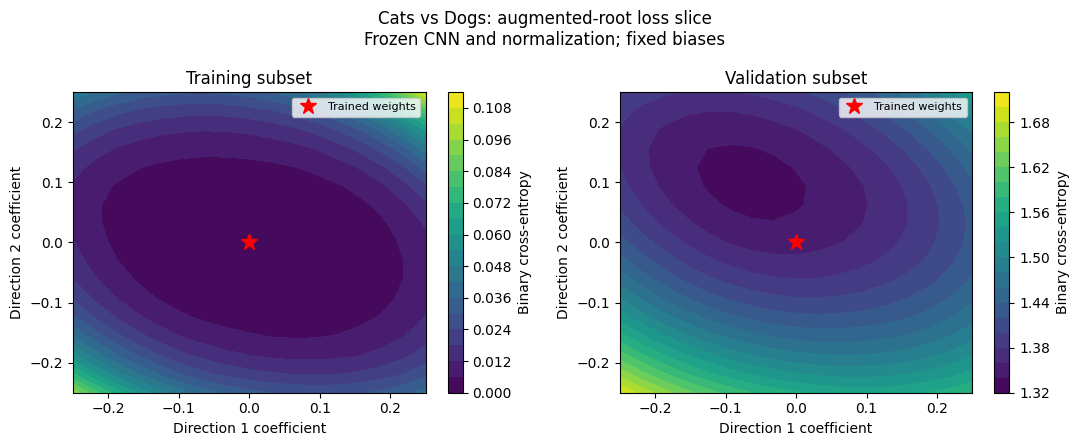

Cats vs Dogs landscape saved.


In [42]:
import numpy as np
import matplotlib.pyplot as plt
import copy

cd_landscape_root = copy.deepcopy(
    cd_roots["augmented"]
).to(cd_device)
cd_landscape_root.eval()

cd_cache = cd_feature_cache["augmented"]
cd_landscape_rng = torch.Generator().manual_seed(777)

cd_landscape_train_ids = torch.randperm(
    len(cd_cache["train_labels"]),
    generator=cd_landscape_rng
)[:2048]

cd_landscape_val_ids = torch.randperm(
    len(cd_cache["validation_labels"]),
    generator=cd_landscape_rng
)[:2048]

cd_landscape_train_X = cd_cache["train_features"][
    cd_landscape_train_ids
].to(cd_device)

cd_landscape_val_X = cd_cache["validation_features"][
    cd_landscape_val_ids
].to(cd_device)

cd_landscape_train_y = cd_cache["train_labels"][
    cd_landscape_train_ids
].float().to(cd_device)

cd_landscape_val_y = cd_cache["validation_labels"][
    cd_landscape_val_ids
].float().to(cd_device)

cd_center_parameters = {
    name: parameter.detach().clone()
    for name, parameter in cd_landscape_root.named_parameters()
}

cd_direction_rng = torch.Generator().manual_seed(888)


def cd_make_direction():
    direction = {}

    for name, parameter in cd_center_parameters.items():
        if parameter.ndim < 2:
            direction[name] = torch.zeros_like(parameter)
        else:
            noise = torch.randn(
                parameter.shape,
                generator=cd_direction_rng
            ).to(cd_device)

            direction[name] = (
                noise
                * parameter.norm(dim=1, keepdim=True)
                / noise.norm(dim=1, keepdim=True).clamp_min(1e-12)
            )

    return direction


cd_direction_1 = cd_make_direction()
cd_direction_2 = cd_make_direction()

cd_coordinates = np.linspace(-0.25, 0.25, 17)
cd_train_surface = np.zeros((17, 17))
cd_val_surface = np.zeros((17, 17))

try:
    with torch.no_grad():
        for row, beta in enumerate(cd_coordinates):
            for column, alpha in enumerate(cd_coordinates):
                for name, parameter in (
                    cd_landscape_root.named_parameters()
                ):
                    parameter.copy_(
                        cd_center_parameters[name]
                        + float(alpha) * cd_direction_1[name]
                        + float(beta) * cd_direction_2[name]
                    )

                cd_train_surface[row, column] = (
                    nn.functional.binary_cross_entropy_with_logits(
                        cd_landscape_root(cd_landscape_train_X),
                        cd_landscape_train_y
                    ).item()
                )

                cd_val_surface[row, column] = (
                    nn.functional.binary_cross_entropy_with_logits(
                        cd_landscape_root(cd_landscape_val_X),
                        cd_landscape_val_y
                    ).item()
                )
finally:
    with torch.no_grad():
        for name, parameter in cd_landscape_root.named_parameters():
            parameter.copy_(cd_center_parameters[name])

middle = len(cd_coordinates) // 2

print("Center training BCE:", cd_train_surface[middle, middle])
print("Center validation BCE:", cd_val_surface[middle, middle])
print("Minimum sampled training BCE:", cd_train_surface.min())
print("Minimum sampled validation BCE:", cd_val_surface.min())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, surface, title in [
    (axes[0], cd_train_surface, "Training subset"),
    (axes[1], cd_val_surface, "Validation subset")
]:
    contour = ax.contourf(
        cd_coordinates, cd_coordinates,
        surface, levels=20, cmap="viridis"
    )
    ax.plot(0, 0, "r*", markersize=12, label="Trained weights")
    ax.set(
        xlabel="Direction 1 coefficient",
        ylabel="Direction 2 coefficient",
        title=title
    )
    ax.legend(fontsize=8)
    fig.colorbar(contour, ax=ax, label="Binary cross-entropy")

fig.suptitle(
    "Cats vs Dogs: augmented-root loss slice\n"
    "Frozen CNN and normalization; fixed biases"
)
fig.tight_layout()

fig.savefig(
    cd_output_folder / "root_loss_landscape.pdf",
    bbox_inches="tight"
)
fig.savefig(
    cd_output_folder / "root_loss_landscape.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

np.savez(
    cd_output_folder / "root_loss_landscape.npz",
    coordinates=cd_coordinates,
    train_loss=cd_train_surface,
    validation_loss=cd_val_surface,
    train_indices=cd_landscape_train_ids.numpy(),
    validation_indices=cd_landscape_val_ids.numpy()
)

torch.save({
    "center_parameters": {
        name: value.cpu()
        for name, value in cd_center_parameters.items()
    },
    "direction_1": {
        name: value.cpu()
        for name, value in cd_direction_1.items()
    },
    "direction_2": {
        name: value.cpu()
        for name, value in cd_direction_2.items()
    },
    "feature_mean": cd_cache["feature_mean"],
    "feature_std": cd_cache["feature_std"]
}, cd_output_folder / "root_landscape_directions.pt")

print("Cats vs Dogs landscape saved.")

In [43]:
import torch
from pathlib import Path

cd_dd_folder = cd_output_folder / "double_descent"
cd_dd_folder.mkdir(parents=True, exist_ok=True)

cd_dd_definition_path = cd_dd_folder / "experiment_definition.pt"

if cd_dd_definition_path.exists():
    cd_dd_definition = torch.load(
        cd_dd_definition_path,
        map_location="cpu",
        weights_only=False
    )
    print("Loaded the existing experiment definition.")

else:
    cache = cd_feature_cache["augmented"]
    labels = cache["train_labels"].cpu().long()

    # Fixed balanced subset: 2,500 cats and 2,500 dogs.
    generator = torch.Generator().manual_seed(31415)

    selected = []
    for label in [0, 1]:
        candidates = torch.where(labels == label)[0]
        order = torch.randperm(len(candidates), generator=generator)
        selected.append(candidates[order[:2500]])

    selected = torch.cat(selected)
    selected = selected[
        torch.randperm(len(selected), generator=generator)
    ]

    clean_labels = labels[selected].clone()

    # Flip exactly 15% of labels; validation labels stay unchanged.
    noisy_labels = clean_labels.clone()
    noise_generator = torch.Generator().manual_seed(27182)
    changed = torch.randperm(
        len(selected), generator=noise_generator
    )[:750]
    noisy_labels[changed] = 1 - noisy_labels[changed]

    views = [
        cache["train_features"][selected].cpu().clone(),
        *[
            view[selected].cpu().clone()
            for view in cache["augmented_views"]
        ]
    ]

    cd_dd_definition = {
        "selected_ids": selected,
        "clean_labels": clean_labels,
        "noisy_labels": noisy_labels,
        "changed_indices": changed,
        "views": views,
        "feature_mean": views[0].mean(0),
        "feature_std": views[0].std(0).clamp_min(1e-6),
        "widths": [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128],
    }

    torch.save(cd_dd_definition, cd_dd_definition_path)
    print("Saved the experiment definition.")


cd_dd_views = cd_dd_definition["views"]
cd_dd_clean_labels = cd_dd_definition["clean_labels"]
cd_dd_noisy_labels = cd_dd_definition["noisy_labels"]
cd_dd_mean = cd_dd_definition["feature_mean"]
cd_dd_std = cd_dd_definition["feature_std"]
cd_dd_widths = cd_dd_definition["widths"]

cd_dd_validation_features = (
    cd_feature_cache["augmented"]["validation_features"]
)
cd_dd_validation_labels = (
    cd_feature_cache["augmented"]["validation_labels"].long()
)


def cd_dd_error_floor(features, labels):
    """Minimum errors forced by identical features with opposite labels."""
    _, group = torch.unique(
        features, dim=0, return_inverse=True
    )
    counts = torch.bincount(
        2 * group + labels,
        minlength=2 * (int(group.max()) + 1)
    ).reshape(-1, 2)

    return int(counts.min(dim=1).values.sum())


print("\nOriginal training images:", len(cd_dd_clean_labels))
print("Cached views per image:", len(cd_dd_views))
print(
    "Changed labels:",
    int((cd_dd_clean_labels != cd_dd_noisy_labels).sum())
)
print("Widths:", cd_dd_widths)

# These floors distinguish unavoidable contradictions from fitting errors.
for condition, labels in [
    ("clean", cd_dd_clean_labels),
    ("noise15", cd_dd_noisy_labels)
]:
    floor = cd_dd_error_floor(cd_dd_views[0], labels)
    print(
        f"{condition}: unavoidable original-feature "
        f"training errors = {floor}"
    )

print("\nSaved:", cd_dd_definition_path)

Saved the experiment definition.

Original training images: 5000
Cached views per image: 3
Changed labels: 750
Widths: [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128]
clean: unavoidable original-feature training errors = 1
noise15: unavoidable original-feature training errors = 1

Saved: /Users/aroma/catsdogs_augmentation_ensemble/double_descent/experiment_definition.pt


In [44]:
import time
import csv
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

cd_dd_seed = 201
cd_dd_epochs = 300
cd_dd_lr = 0.001
cd_dd_results = []


@torch.no_grad()
def cd_dd_scores(network, features):
    network.eval()
    return torch.cat([
        network(batch.to(cd_device)).cpu()
        for batch in features.split(512)
    ])


for condition, assigned_labels in [
    ("clean", cd_dd_clean_labels),
    ("noise15", cd_dd_noisy_labels)
]:
    assigned_labels = assigned_labels.cpu().long()

    original_floor = cd_dd_error_floor(
        cd_dd_views[0], assigned_labels
    )

    for width in cd_dd_widths:
        checkpoint_path = cd_dd_folder / (
            f"{condition}_width{width}_seed{cd_dd_seed}.pt"
        )

        saved = None
        if checkpoint_path.exists():
            saved = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=False
            )

            if saved["epoch"] >= cd_dd_epochs:
                cd_dd_results.append(saved["history"][-1])
                print(
                    f"Already completed: {condition}, width {width}",
                    flush=True
                )
                continue

        torch.manual_seed(cd_dd_seed)

        network = CDRoot(
            cd_dd_mean, cd_dd_std, width=width
        ).to(cd_device)

        optimizer = torch.optim.Adam(
            network.parameters(), lr=cd_dd_lr
        )

        loader_generator = torch.Generator().manual_seed(
            cd_dd_seed
        )
        view_generator = torch.Generator().manual_seed(
            cd_dd_seed + 10000
        )

        loader = DataLoader(
            TensorDataset(torch.arange(len(assigned_labels))),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=loader_generator
        )

        history = []
        start_epoch = 0

        if saved is not None:
            network.load_state_dict(saved["state"])
            optimizer.load_state_dict(saved["optimizer_state"])

            for parameter, state in optimizer.state.items():
                for name, value in state.items():
                    if isinstance(value, torch.Tensor) and name != "step":
                        state[name] = value.to(parameter.device)

            loader_generator.set_state(saved["loader_rng"])
            view_generator.set_state(saved["view_rng"])
            history = saved["history"]
            start_epoch = saved["epoch"]

        print(
            f"\n{condition.upper()} | WIDTH {width} "
            f"| starting epoch {start_epoch}",
            flush=True
        )
        start_time = time.perf_counter()

        for epoch in range(start_epoch + 1, cd_dd_epochs + 1):
            network.train()

            for (indices,) in loader:
                view_index = int(torch.randint(
                    len(cd_dd_views),
                    (1,),
                    generator=view_generator
                ).item())

                features = cd_dd_views[view_index][indices].to(
                    cd_device
                )
                targets = assigned_labels[indices].float().to(
                    cd_device
                )

                optimizer.zero_grad(set_to_none=True)
                loss = F.binary_cross_entropy_with_logits(
                    network(features), targets
                )
                loss.backward()
                optimizer.step()

            if epoch % 25 == 0:
                original_scores = cd_dd_scores(
                    network, cd_dd_views[0]
                )
                original_predictions = (
                    original_scores >= 0
                ).long()

                original_errors = int((
                    original_predictions != assigned_labels
                ).sum())

                view_errors = []
                view_losses = []

                for view_index, features in enumerate(cd_dd_views):
                    scores = (
                        original_scores if view_index == 0
                        else cd_dd_scores(network, features)
                    )

                    view_errors.append(int((
                        (scores >= 0).long() != assigned_labels
                    ).sum()))

                    view_losses.append(
                        F.binary_cross_entropy_with_logits(
                            scores, assigned_labels.float()
                        ).item()
                    )

                val_scores = cd_dd_scores(
                    network, cd_dd_validation_features
                )
                val_errors = int((
                    (val_scores >= 0).long()
                    != cd_dd_validation_labels
                ).sum())

                row = {
                    "condition": condition,
                    "seed": cd_dd_seed,
                    "width": width,
                    "epoch": epoch,
                    "head_parameters": sum(
                        p.numel() for p in network.parameters()
                    ),
                    "assigned_errors_original_inputs": original_errors,
                    "original_feature_error_floor": original_floor,
                    "excess_errors_original_inputs": (
                        original_errors - original_floor
                    ),
                    "assigned_errors_all_cached_views": sum(view_errors),
                    "mean_cached_view_BCE": (
                        sum(view_losses) / len(view_losses)
                    ),
                    "validation_errors": val_errors,
                    "validation_accuracy": 100 * (
                        1 - val_errors / len(cd_dd_validation_labels)
                    ),
                    "validation_BCE": (
                        F.binary_cross_entropy_with_logits(
                            val_scores,
                            cd_dd_validation_labels.float()
                        ).item()
                    )
                }
                history.append(row)

                torch.save({
                    "state": {
                        name: value.detach().cpu().clone()
                        for name, value in network.state_dict().items()
                    },
                    "optimizer_state": optimizer.state_dict(),
                    "loader_rng": loader_generator.get_state(),
                    "view_rng": view_generator.get_state(),
                    "epoch": epoch,
                    "learning_rate": cd_dd_lr,
                    "history": history
                }, checkpoint_path)

                with checkpoint_path.with_suffix(".csv").open(
                    "w", newline=""
                ) as file:
                    writer = csv.DictWriter(
                        file, fieldnames=history[0].keys()
                    )
                    writer.writeheader()
                    writer.writerows(history)

                if epoch % 100 == 0:
                    print(
                        f"Epoch {epoch}: train errors={original_errors} "
                        f"| excess above floor="
                        f"{original_errors - original_floor} "
                        f"| all-view errors={sum(view_errors)} "
                        f"| BCE={row['mean_cached_view_BCE']:.5f} "
                        f"| validation="
                        f"{row['validation_accuracy']:.2f}%",
                        flush=True
                    )

        cd_dd_results.append(history[-1])

        first_floor_epoch = next(
            (
                row["epoch"] for row in history
                if row["excess_errors_original_inputs"] == 0
            ),
            None
        )

        print(
            f"Finished width {width} "
            f"| first measured floor-reaching epoch="
            f"{first_floor_epoch} "
            f"| time={time.perf_counter() - start_time:.1f}s",
            flush=True
        )

        network.cpu()

results_path = cd_dd_folder / "capacity_results_seed201.csv"

with results_path.open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=cd_dd_results[0].keys()
    )
    writer.writeheader()
    writer.writerows(cd_dd_results)

print("\nSweep complete. Saved:", results_path)


CLEAN | WIDTH 1 | starting epoch 0
Epoch 100: train errors=555 | excess above floor=554 | all-view errors=1804 | BCE=0.32139 | validation=78.03%
Epoch 200: train errors=493 | excess above floor=492 | all-view errors=1618 | BCE=0.29911 | validation=77.91%
Epoch 300: train errors=470 | excess above floor=469 | all-view errors=1589 | BCE=0.29409 | validation=77.02%
Finished width 1 | first measured floor-reaching epoch=None | time=7.8s

CLEAN | WIDTH 2 | starting epoch 0
Epoch 100: train errors=549 | excess above floor=548 | all-view errors=1672 | BCE=0.21986 | validation=78.39%
Epoch 200: train errors=491 | excess above floor=490 | all-view errors=1428 | BCE=0.17266 | validation=77.75%
Epoch 300: train errors=442 | excess above floor=441 | all-view errors=1313 | BCE=0.14749 | validation=77.27%
Finished width 2 | first measured floor-reaching epoch=None | time=7.2s

CLEAN | WIDTH 3 | starting epoch 0
Epoch 100: train errors=317 | excess above floor=316 | all-view errors=900 | BCE=0.16502

In [45]:
cd_dd_stable_results = []
cd_dd_final_epoch = 600
cd_dd_stable_lr = 0.0001

for condition, assigned_labels in [
    ("clean", cd_dd_clean_labels),
    ("noise15", cd_dd_noisy_labels)
]:
    assigned_labels = assigned_labels.cpu().long()

    for width in cd_dd_widths:
        original_path = cd_dd_folder / (
            f"{condition}_width{width}_seed201.pt"
        )
        stable_path = cd_dd_folder / (
            f"{condition}_width{width}_seed201_stabilized.pt"
        )

        saved = torch.load(
            stable_path if stable_path.exists() else original_path,
            map_location="cpu",
            weights_only=False
        )

        if saved["epoch"] >= cd_dd_final_epoch:
            cd_dd_stable_results.append(saved["history"][-1])
            print(f"Already completed: {condition}, width {width}")
            continue

        network = CDRoot(
            cd_dd_mean, cd_dd_std, width=width
        ).to(cd_device)
        network.load_state_dict(saved["state"])

        optimizer = torch.optim.Adam(
            network.parameters(), lr=cd_dd_stable_lr
        )
        optimizer.load_state_dict(saved["optimizer_state"])

        for group in optimizer.param_groups:
            group["lr"] = cd_dd_stable_lr

        for parameter, state in optimizer.state.items():
            for name, value in state.items():
                if isinstance(value, torch.Tensor) and name != "step":
                    state[name] = value.to(parameter.device)

        loader_generator = torch.Generator()
        loader_generator.set_state(saved["loader_rng"])

        view_generator = torch.Generator()
        view_generator.set_state(saved["view_rng"])

        loader = DataLoader(
            TensorDataset(torch.arange(len(assigned_labels))),
            batch_size=256,
            shuffle=True,
            num_workers=0,
            generator=loader_generator
        )

        history = list(saved["history"])
        floor = cd_dd_error_floor(
            cd_dd_views[0], assigned_labels
        )

        print(f"\n{condition.upper()} | width {width}", flush=True)

        for epoch in range(saved["epoch"] + 1, cd_dd_final_epoch + 1):
            network.train()

            for (indices,) in loader:
                view_index = int(torch.randint(
                    len(cd_dd_views), (1,),
                    generator=view_generator
                ).item())

                optimizer.zero_grad(set_to_none=True)

                loss = F.binary_cross_entropy_with_logits(
                    network(
                        cd_dd_views[view_index][indices].to(cd_device)
                    ),
                    assigned_labels[indices].float().to(cd_device)
                )
                loss.backward()
                optimizer.step()

            if epoch % 25 == 0:
                original_scores = cd_dd_scores(
                    network, cd_dd_views[0]
                )

                original_errors = int((
                    (original_scores >= 0).long() != assigned_labels
                ).sum())

                errors_per_view = []
                losses_per_view = []

                for view_index, features in enumerate(cd_dd_views):
                    scores = (
                        original_scores if view_index == 0
                        else cd_dd_scores(network, features)
                    )

                    errors_per_view.append(int((
                        (scores >= 0).long() != assigned_labels
                    ).sum()))

                    losses_per_view.append(
                        F.binary_cross_entropy_with_logits(
                            scores, assigned_labels.float()
                        ).item()
                    )

                validation_scores = cd_dd_scores(
                    network, cd_dd_validation_features
                )
                validation_errors = int((
                    (validation_scores >= 0).long()
                    != cd_dd_validation_labels
                ).sum())

                row = {
                    "condition": condition,
                    "seed": 201,
                    "width": width,
                    "epoch": epoch,
                    "head_parameters": sum(
                        p.numel() for p in network.parameters()
                    ),
                    "assigned_errors_original_inputs": original_errors,
                    "original_feature_error_floor": floor,
                    "excess_errors_original_inputs": original_errors - floor,
                    "assigned_errors_all_cached_views": sum(errors_per_view),
                    "mean_cached_view_BCE": (
                        sum(losses_per_view) / len(losses_per_view)
                    ),
                    "validation_errors": validation_errors,
                    "validation_accuracy": 100 * (
                        1 - validation_errors / len(cd_dd_validation_labels)
                    ),
                    "validation_BCE": (
                        F.binary_cross_entropy_with_logits(
                            validation_scores,
                            cd_dd_validation_labels.float()
                        ).item()
                    )
                }
                history.append(row)

                torch.save({
                    "state": {
                        name: value.detach().cpu().clone()
                        for name, value in network.state_dict().items()
                    },
                    "optimizer_state": optimizer.state_dict(),
                    "loader_rng": loader_generator.get_state(),
                    "view_rng": view_generator.get_state(),
                    "epoch": epoch,
                    "learning_rate": cd_dd_stable_lr,
                    "history": history
                }, stable_path)

                if epoch % 100 == 0:
                    print(
                        f"Epoch {epoch}: train errors={original_errors} "
                        f"| excess={original_errors - floor} "
                        f"| all-view errors={sum(errors_per_view)} "
                        f"| BCE={row['mean_cached_view_BCE']:.5f} "
                        f"| validation={row['validation_accuracy']:.2f}%",
                        flush=True
                    )

        cd_dd_stable_results.append(history[-1])
        network.cpu()

stable_csv = cd_dd_folder / "capacity_stabilized_seed201.csv"

with stable_csv.open("w", newline="") as file:
    writer = csv.DictWriter(
        file, fieldnames=cd_dd_stable_results[0].keys()
    )
    writer.writeheader()
    writer.writerows(cd_dd_stable_results)

print("\nSaved:", stable_csv)


CLEAN | width 1
Epoch 400: train errors=456 | excess=455 | all-view errors=1506 | BCE=0.28767 | validation=77.19%
Epoch 500: train errors=462 | excess=461 | all-view errors=1521 | BCE=0.28658 | validation=77.19%
Epoch 600: train errors=464 | excess=463 | all-view errors=1513 | BCE=0.28604 | validation=77.31%

CLEAN | width 2
Epoch 400: train errors=417 | excess=416 | all-view errors=1244 | BCE=0.13424 | validation=77.11%
Epoch 500: train errors=417 | excess=416 | all-view errors=1207 | BCE=0.13127 | validation=77.02%
Epoch 600: train errors=418 | excess=417 | all-view errors=1250 | BCE=0.12855 | validation=77.02%

CLEAN | width 3
Epoch 400: train errors=133 | excess=132 | all-view errors=334 | BCE=0.05772 | validation=77.75%
Epoch 500: train errors=133 | excess=132 | all-view errors=334 | BCE=0.05611 | validation=77.63%
Epoch 600: train errors=133 | excess=132 | all-view errors=334 | BCE=0.05492 | validation=77.51%

CLEAN | width 4
Epoch 400: train errors=83 | excess=82 | all-view err

In [47]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 35.0 MB/s  0:00:0036.5 MB/s eta 0:00:01

[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Saved: /Users/aroma/catsdogs_augmentation_ensemble/double_descent/capacity_stabilized_seed201.png
Saved: /Users/aroma/catsdogs_augmentation_ensemble/double_descent/capacity_stabilized_seed201.pdf


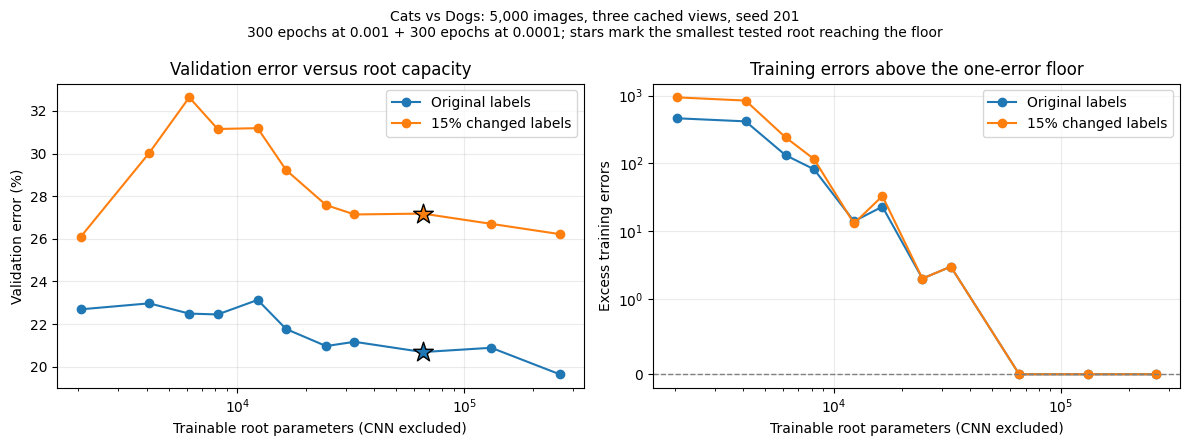

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

cd_dd_table = pd.read_csv(
    cd_dd_folder / "capacity_stabilized_seed201.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for condition, label, color in [
    ("clean", "Original labels", "tab:blue"),
    ("noise15", "15% changed labels", "tab:orange")
]:
    table = cd_dd_table[
        cd_dd_table["condition"] == condition
    ].sort_values("head_parameters")

    parameters = table["head_parameters"]

    # Validation error: lower is better.
    axes[0].plot(
        parameters,
        100 - table["validation_accuracy"],
        "o-", color=color, label=label
    )

    # Training errors above the unavoidable contradiction floor.
    axes[1].plot(
        parameters,
        table["excess_errors_original_inputs"],
        "o-", color=color, label=label
    )

    floor_reached = table[
        table["excess_errors_original_inputs"] == 0
    ]

    if not floor_reached.empty:
        first = floor_reached.iloc[0]

        axes[0].scatter(
            first["head_parameters"],
            100 - first["validation_accuracy"],
            marker="*", s=220, color=color,
            edgecolors="black", zorder=5
        )

axes[0].set_title("Validation error versus root capacity")
axes[0].set_ylabel("Validation error (%)")

axes[1].set_title("Training errors above the one-error floor")
axes[1].set_ylabel("Excess training errors")
axes[1].set_yscale("symlog", linthresh=1)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Trainable root parameters (CNN excluded)")
    ax.grid(True, alpha=0.25)
    ax.legend()

fig.suptitle(
    "Cats vs Dogs: 5,000 images, three cached views, seed 201\n"
    "300 epochs at 0.001 + 300 epochs at 0.0001; "
    "stars mark the smallest tested root reaching the floor",
    fontsize=10
)

fig.tight_layout()

for extension in ["png", "pdf"]:
    path = cd_dd_folder / f"capacity_stabilized_seed201.{extension}"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("Saved:", path)

plt.show()

In [49]:
import json
import torch

# Use the audited test split and original, unaugmented images.
cd_test_dataset = CDAssignmentDataset(
    cd_samples["test"],
    cd_clean_transform
)

cd_test_features = {}

for condition in ["clean", "augmented"]:
    features, labels = cd_extract_features(
        cd_feature_models[condition].trunk,
        cd_test_dataset
    )

    cd_test_features[condition] = features.cpu()
    if condition == "clean":
        cd_test_labels = labels.cpu().long()
    else:
        assert torch.equal(cd_test_labels, labels.cpu().long())

print("Test images:", len(cd_test_labels))


def cd_final_metrics(predictions):
    predictions = predictions.cpu().long()
    labels = cd_test_labels

    missed_dogs = int(((predictions == 0) & (labels == 1)).sum())
    false_dogs = int(((predictions == 1) & (labels == 0)).sum())
    errors = int((predictions != labels).sum())

    cat_recall = (
        (predictions[labels == 0] == 0).float().mean().item()
    )
    dog_recall = (
        (predictions[labels == 1] == 1).float().mean().item()
    )

    return {
        "accuracy": 100 * (1 - errors / len(labels)),
        "balanced_accuracy": 50 * (cat_recall + dog_recall),
        "errors": errors,
        "missed_dogs": missed_dogs,
        "false_dogs": false_dogs
    }


cd_final_test_predictions = {}
cd_final_test_results = {}

# Restore the planned epoch-100 full-data roots.
for condition in ["clean", "augmented"]:
    saved = torch.load(
        cd_output_folder / f"root_{condition}_seed42_epoch100.pt",
        map_location="cpu",
        weights_only=False
    )

    cache = cd_feature_cache[condition]
    root = CDRoot(
        cache["feature_mean"],
        cache["feature_std"],
        width=128
    ).to(cd_device)
    root.load_state_dict(saved["state"])

    scores = cd_root_scores(root, cd_test_features[condition])
    name = f"{condition}_root"
    cd_final_test_predictions[name] = (scores >= 0).long()
    root.cpu()


# Restore all five saved correction trees.
cd_test_member_roots = []
cd_test_member_trees = []

aug_cache = cd_feature_cache["augmented"]
test_features = cd_test_features["augmented"]

test_Z = (
    test_features - aug_cache["feature_mean"]
) / aug_cache["feature_std"]

for seed in [101, 102, 103, 104, 105]:
    saved = torch.load(
        cd_output_folder / f"corrected_tree_seed{seed}.pt",
        map_location="cpu",
        weights_only=False
    )

    root = CDRoot(
        aug_cache["feature_mean"],
        aug_cache["feature_std"],
        width=saved["root_width"]
    ).to(cd_device)
    root.load_state_dict(saved["root_state"])

    scores = cd_root_scores(root, test_features).double()
    cd_test_member_roots.append((scores >= 0).long())

    corrected_scores = scores.clone()

    for child_name, child_data in saved["children"].items():
        child = CDCorrectionChild(
            width=child_data["width"]
        ).to(cd_device)
        child.load_state_dict(child_data["state"])

        flags = cd_root_scores(child, test_Z) >= 0
        direction = 1 if child_name == "A" else -1

        corrected_scores += (
            direction
            * float(child_data["strength"])
            * flags.double()
        )
        child.cpu()

    cd_test_member_trees.append(
        (corrected_scores >= 0).long()
    )
    root.cpu()

cd_test_member_roots = torch.stack(cd_test_member_roots)
cd_test_member_trees = torch.stack(cd_test_member_trees)

# Fixed prefixes: seed 101; seeds 101–103; all five seeds.
for count in [1, 3, 5]:
    cd_final_test_predictions[f"roots_vote_{count}"] = (
        cd_majority_vote(cd_test_member_roots[:count])
    )
    cd_final_test_predictions[f"trees_vote_{count}"] = (
        cd_majority_vote(cd_test_member_trees[:count])
    )

print("\nFINAL TEST RESULTS")

for name, predictions in cd_final_test_predictions.items():
    result = cd_final_metrics(predictions)
    cd_final_test_results[name] = result

    print(
        f"{name:20s}: "
        f"accuracy={result['accuracy']:.2f}% | "
        f"balanced={result['balanced_accuracy']:.2f}% | "
        f"errors={result['errors']}"
    )

with (cd_output_folder / "final_test_results.json").open("w") as file:
    json.dump({
        "test_images": len(cd_test_labels),
        "epoch": 100,
        "ensemble_seed_order": [101, 102, 103, 104, 105],
        "results": cd_final_test_results
    }, file, indent=2)

torch.save({
    "labels": cd_test_labels,
    "predictions": cd_final_test_predictions,
    "member_root_predictions": cd_test_member_roots,
    "member_tree_predictions": cd_test_member_trees
}, cd_output_folder / "final_test_predictions.pt")

print("\nSaved: final_test_results.json")
print("Saved: final_test_predictions.pt")

Test images: 2496

FINAL TEST RESULTS
clean_root          : accuracy=80.05% | balanced=80.05% | errors=498
augmented_root      : accuracy=81.97% | balanced=81.97% | errors=450
roots_vote_1        : accuracy=81.57% | balanced=81.57% | errors=460
trees_vote_1        : accuracy=81.57% | balanced=81.57% | errors=460
roots_vote_3        : accuracy=82.09% | balanced=82.09% | errors=447
trees_vote_3        : accuracy=82.09% | balanced=82.09% | errors=447
roots_vote_5        : accuracy=82.85% | balanced=82.85% | errors=428
trees_vote_5        : accuracy=82.85% | balanced=82.85% | errors=428

Saved: final_test_results.json
Saved: final_test_predictions.pt
